<a href="https://colab.research.google.com/github/angelolucero-cloud/GO-Grupo-2/blob/main/Entrega_1_COMPLETO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entrega 1 — Calidad, Pronóstico e Integración
GRUPO 2

In [1]:
from pathlib import Path
import subprocess
import numpy as np
import pandas as pd
from IPython.display import display

carpeta_proyecto = Path('/content/GO-Grupo-2') if Path('/content').exists() else Path.cwd() / 'GO-Grupo-2'
if not carpeta_proyecto.exists():
    subprocess.run(['git', 'clone', 'https://github.com/angelolucero-cloud/GO-Grupo-2.git', str(carpeta_proyecto)], check=True)
ruta_datos = carpeta_proyecto / 'datos'
requeridos = ['maestro_sku.csv','demanda_semanal.csv','calidad_llenado.csv','calidad_atributos.csv','especificaciones_calidad.csv']
faltantes = [nombre for nombre in requeridos if not (ruta_datos/nombre).is_file()]
if faltantes:
    raise FileNotFoundError(f'Faltan archivos en {ruta_datos}: {faltantes}')
carpeta_salidas_integradas = Path('/content/salidas_entrega_1') if Path('/content').exists() else Path.cwd()/'salidas_entrega_1'
carpeta_salidas_integradas.mkdir(parents=True,exist_ok=True)
print('Datos verificados:', ruta_datos)


Datos verificados: /content/GO-Grupo-2/datos


# PARTE A — Calidad

In [2]:
# Datos comunes del proyecto: misma fuente para A, B y C
import matplotlib.pyplot as plt
import seaborn as sns
llenado = pd.read_csv(ruta_datos/'calidad_llenado.csv')
atributos = pd.read_csv(ruta_datos/'calidad_atributos.csv')
especificaciones = pd.read_csv(ruta_datos/'especificaciones_calidad.csv')
maestro = pd.read_csv(ruta_datos/'maestro_sku.csv')
demanda = pd.read_csv(ruta_datos/'demanda_semanal.csv')
print('Archivos cargados:', {k:len(v) for k,v in [('llenado',llenado),('atributos',atributos),('especificaciones',especificaciones),('maestro',maestro),('demanda',demanda)]})
display(llenado.head())

Archivos cargados: {'llenado': 4200, 'atributos': 210, 'especificaciones': 3, 'maestro': 9, 'demanda': 1404}


,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL
0,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,1,500.86
1,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,2,502.11
2,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,3,503.12
3,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,4,502.60
4,1,2026-07-20,1,A (06-14),L1,FUN-B05,0.5,06:00,5,499.11


Exploración y diagnóstico de los datos: comprobar que las mediciones de llenado estén correctamente registradas antes de construir las cartas de control.


In [3]:
# BLOQUE 2: EXPLORACIÓN Y DIAGNÓSTICO DE DATOS

# Revisar las primeras 5 filas
print(llenado.head())

# Revisar cantidad de filas y columnas
print("Dimensiones:")
print(llenado.shape)

# Revisar nombres y tipos de columnas
print("Información general:")
llenado.info()

# Obtener estadísticas descriptivas
print("Estadísticas descriptivas:")
print(llenado.describe())

   subgrupo       fecha  semana_registro      turno linea      sku  formato_L  \
0         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
1         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
2         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
3         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   
4         1  2026-07-20                1  A (06-14)    L1  FUN-B05        0.5   

    hora  n_obs  volumen_mL  
0  06:00      1      500.86  
1  06:00      2      502.11  
2  06:00      3      503.12  
3  06:00      4      502.60  
4  06:00      5      499.11  
Dimensiones:
(4200, 10)
Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   subgrupo         4200 non-null   int64  
 1   fecha            4200 non-null   objec

 Validación de datos
Antes de realizar el análisis estadístico del proceso de llenado, se realiza una validación inicial de la base de datos con el objetivo de identificar posibles problemas que puedan afectar los resultados. Para esto, se revisa la existencia de valores faltantes, registros duplicados, consistencia en el tamaño de los subgrupos de medición y distribución de las observaciones según línea de producción, formato y turno.
Esta etapa permite asegurar que los datos utilizados posteriormente para la construcción de cartas de control representen adecuadamente el comportamiento del proceso productivo.

In [4]:
#BLOQUE 3 validación de datos
#1
# Revisar valores faltantes

print("Valores faltantes por columna:")
print(llenado.isnull().sum())

#2
#Revisar registros duplicados

print("Cantidad de filas duplicadas:")
print(llenado.duplicated().sum())

#3
# Revisar tamaño de los subgrupos

cantidad_subgrupo = llenado.groupby("subgrupo").size()

print("Cantidad de mediciones por subgrupo:")
print(cantidad_subgrupo.value_counts())

#4
# Identificar subgrupos que no tienen 5 observaciones

subgrupos_incorrectos = cantidad_subgrupo[cantidad_subgrupo != 5]

print("Subgrupos con cantidad distinta de 5:")
print(subgrupos_incorrectos)

# 5
#Revisar cantidad de mediciones por línea

print("Mediciones por línea:")
print(llenado["linea"].value_counts())


#6
# Revisar cantidad por formato

print("\nMediciones por formato:")
print(llenado["formato_L"].value_counts())


#7
# Revisar cantidad por turno

print("\nMediciones por turno:")
print(llenado["turno"].value_counts())

Valores faltantes por columna:
subgrupo           0
fecha              0
semana_registro    0
turno              0
linea              0
sku                0
formato_L          0
hora               0
n_obs              0
volumen_mL         0
dtype: int64
Cantidad de filas duplicadas:
0
Cantidad de mediciones por subgrupo:
5    840
Name: count, dtype: int64
Subgrupos con cantidad distinta de 5:
Series([], dtype: int64)
Mediciones por línea:
linea
L2    3000
L1    1200
Name: count, dtype: int64

Mediciones por formato:
formato_L
3.0    1560
1.5    1440
0.5    1200
Name: count, dtype: int64

Mediciones por turno:
turno
A (06-14)    1600
B (14-22)    1600
C (22-06)    1000
Name: count, dtype: int64


1. "La base de datos de llenado no presenta valores faltantes, por lo que todas las observaciones pueden ser consideradas en el análisis estadístico posterior."
2. "No se identificaron registros duplicados, evitando que algunas mediciones tengan una influencia artificialmente mayor dentro del análisis."
3. Todos los subgrupos contienen cinco observaciones, cumpliendo la estructura necesaria para aplicar cartas de control X̄–R.
4. No se encontraron subgrupos con tamaños incorrectos, por lo que no fue necesario realizar ajustes en la estructura de los datos.
5. La línea L2 concentra la mayor cantidad de mediciones (3000), mientras que L1 posee 1200 observaciones. El análisis posterior considerará cada línea por separado.
6. Se identificaron tres formatos de producción (0,5 L, 1,5 L y 3,0 L). Debido a sus diferentes volúmenes nominales, serán analizados de manera independiente.
7. Se cuenta con registros de los tres turnos de operación, permitiendo evaluar posteriormente si existen diferencias asociadas al turno de producción.

**Selección de la carta de control**.

Las mediciones de volumen corresponden a una variable continua y se encuentran organizadas en subgrupos racionales de tamaño constante \(n=5\). Debido a que se trabaja con subgrupos pequeños, se seleccionaron cartas \(X̄-R\): la carta \(X̄\) permite monitorear cambios en el nivel medio de llenado, mientras que la carta \(R\) permite evaluar la variabilidad dentro de cada subgrupo mediante su rango. La alternativa \(X̄-S\) resulta más apropiada para subgrupos de mayor tamaño, donde la desviación estándar aprovecha mejor la información contenida en las observaciones.

**PREPARACIÓN DE DATOS CARTAS X-R**

Para construir las cartas de control X̄–R, se agrupan las mediciones individuales en subgrupos racionales de cinco observaciones. Para cada subgrupo se calcula el promedio del volumen y el rango, permitiendo evaluar tanto el nivel central del proceso como su variabilidad.

In [5]:
#BLOQUE 4 Preparación de datos para cartas X-R
# Crear tabla con promedio y rango por subgrupo

datos_control = llenado.groupby("subgrupo").agg(media_volumen=("volumen_mL", "mean"),
    rango_volumen=("volumen_mL", lambda x: x.max() - x.min()),
    linea=("linea", "first"),
    formato_L=("formato_L", "first"),
    turno=("turno", "first")
).reset_index()


# Mostrar primeros resultados

datos_control.head()


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno
0,1,501.560,4.01,L1,0.5,A (06-14)
1,2,501.752,5.17,L1,0.5,A (06-14)
2,3,503.630,4.13,L1,0.5,A (06-14)
3,4,503.172,2.10,L1,0.5,A (06-14)
4,5,503.396,8.49,L1,0.5,B (14-22)


Se transformaron las mediciones individuales en subgrupos racionales de cinco observaciones, calculando para cada uno la media y el rango del volumen de llenado. Esta estructura permitirá construir las cartas X̄–R, evaluando tanto el nivel promedio del proceso como su variabilidad.

 Separación de procesos por línea y formato
Y escribe:
Debido a que el proceso de llenado presenta diferentes líneas de producción y formatos de producto, los análisis estadísticos se realizarán de manera independiente para cada combinación línea-formato. Esto permite comparar procesos equivalentes y evitar distorsiones producto de diferencias en los volúmenes nominales.

In [6]:
#BLOQUE 5 Separación de procesos para análisis estadístico
# Revisar combinaciones de línea y formato

datos_control[["linea", "formato_L"]].drop_duplicates()

# Separar procesos por línea y formato

proceso_L1_05 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5)
]

proceso_L2_15 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 1.5)
]

proceso_L2_30 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 3.0)
]


print("L1 - 0.5 L:", proceso_L1_05.shape)
print("L2 - 1.5 L:", proceso_L2_15.shape)
print("L2 - 3.0 L:", proceso_L2_30.shape)

L1 - 0.5 L: (240, 6)
L2 - 1.5 L: (288, 6)
L2 - 3.0 L: (312, 6)


Se identificaron tres combinaciones de línea y formato, las cuales fueron separadas para realizar el análisis estadístico de manera independiente y evitar mezclar procesos con distintos volúmenes nominales.
¿Qué significa el resultado (240, 6)?
- 240: cantidad de subgrupos correspondientes a la línea L1 y formato 0,5 L.
- 6: cantidad de columnas de nuestra tabla datos_control.

In [7]:
#BLOQUE 6 : COMPROBACIONES
# Agregar la semana de cada subgrupo a datos_control

semana_subgrupo = llenado[
    ["subgrupo", "semana_registro"]
].drop_duplicates()

datos_control = pd.merge(
    datos_control,
    semana_subgrupo,
    on="subgrupo",
    how="left"
)

display(datos_control.head())

,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro
0,1,501.560,4.01,L1,0.5,A (06-14),1
1,2,501.752,5.17,L1,0.5,A (06-14),1
2,3,503.630,4.13,L1,0.5,A (06-14),1
3,4,503.172,2.10,L1,0.5,A (06-14),1
4,5,503.396,8.49,L1,0.5,B (14-22),1


In [8]:
# Cantidad de subgrupos por semana y proceso

print(
    datos_control.groupby(
        ["linea", "formato_L", "semana_registro"]
    ).size()
)

linea  formato_L  semana_registro
L1     0.5        1                  24
                  2                  24
                  3                  24
                  4                  24
                  5                  24
                  6                  24
                  7                  24
                  8                  24
                  9                  24
                  10                 24
L2     1.5        1                  20
                  2                  32
                  3                  28
                  4                  40
                  5                  16
                  6                  24
                  7                  32
                  8                  24
                  9                  36
                  10                 36
       3.0        1                  40
                  2                  28
                  3                  32
                  4                  20
      

**Definición de Fase I y Fase II**

Se utilizaron las semanas 1 y 2 como período candidato de Fase I, ya que corresponden al tramo cronológicamente inicial de la base y proporcionan una cantidad suficiente de subgrupos para estimar límites preliminares de control. Este período contiene 48 subgrupos para L1–0,5 L, 52 para L2–1,5 L y 68 para L2–3,0 L. Las semanas 3 a 10 se reservaron como Fase II, de modo que pudieran ser evaluadas posteriormente utilizando los límites obtenidos exclusivamente a partir del período inicial. La separación evita recalcular los límites con las mismas observaciones que posteriormente serán utilizadas para monitorear el proceso.

In [9]:
# BLOQUE 7: DEFINICIÓN DE FASE I Y FASE II

datos_control["fase"] = "II"

datos_control.loc[
    datos_control["semana_registro"].isin([1, 2]),
    "fase"
] = "I"

print(datos_control["fase"].value_counts())

display(datos_control.head())

fase
II    672
I     168
Name: count, dtype: int64


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase
0,1,501.560,4.01,L1,0.5,A (06-14),1,I
1,2,501.752,5.17,L1,0.5,A (06-14),1,I
2,3,503.630,4.13,L1,0.5,A (06-14),1,I
3,4,503.172,2.10,L1,0.5,A (06-14),1,I
4,5,503.396,8.49,L1,0.5,B (14-22),1,I


En consecuencia, los límites obtenidos no deben interpretarse como límites definitivos de un proceso estable, sino como una línea base preliminar utilizada para identificar posibles cambios durante la Fase II.

In [10]:
# FASE I DEL PROCESO L1 - 0.5 L

fase1_L1_05 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5) &
    (datos_control["fase"] == "I")
]

print("Cantidad de subgrupos en Fase I:")
print(fase1_L1_05.shape[0])

Cantidad de subgrupos en Fase I:
48


In [11]:
# Promedio de las medias de los subgrupos
media_medias = fase1_L1_05["media_volumen"].mean()

# Promedio de los rangos de los subgrupos
media_rangos = fase1_L1_05["rango_volumen"].mean()

print("Media de medias:", media_medias)
print("Media de rangos:", media_rangos)

Media de medias: 502.643625
Media de rangos: 4.749583333333333


Obtenemos desde las tablas impartidas en clases de calidad 2 las constantes # Constantes para cartas X barra - R con subgrupos de tamaño n = 5
A2 = 0.577
D3 = 0
D4 = 2.114

In [12]:
# Constantes para n = 5
A2 = 0.577
D3 = 0
D4 = 2.114

# Límites de la carta R
LC_R = media_rangos
LSC_R = D4 * media_rangos
LIC_R = D3 * media_rangos

# Límites de la carta X barra
LC_X = media_medias
LSC_X = media_medias + A2 * media_rangos
LIC_X = media_medias - A2 * media_rangos

print("Carta R")
print("LIC:", LIC_R)
print("LC:", LC_R)
print("LSC:", LSC_R)

print("\nCarta X barra")
print("LIC:", LIC_X)
print("LC:", LC_X)
print("LSC:", LSC_X)

Carta R
LIC: 0.0
LC: 4.749583333333333
LSC: 10.040619166666666

Carta X barra
LIC: 499.90311541666665
LC: 502.643625
LSC: 505.3841345833333


In [13]:
# Revisar puntos fuera de los límites en la carta R - Fase I

fuera_R = fase1_L1_05[
    (fase1_L1_05["rango_volumen"] > LSC_R) |
    (fase1_L1_05["rango_volumen"] < LIC_R)
]

print("Subgrupos fuera de control en la carta R:")
display(fuera_R)

Subgrupos fuera de control en la carta R:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase
91,92,502.946,10.06,L1,0.5,B (14-22),2,I


In [14]:
# Revisar las mediciones originales del subgrupo 92

subgrupo_92 = llenado[
    llenado["subgrupo"] == 92
]

display(subgrupo_92)

,subgrupo,fecha,semana_registro,turno,linea,sku,formato_L,hora,n_obs,volumen_mL
455,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,1,503.56
456,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,2,503.12
457,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,3,506.54
458,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,4,505.03
459,92,2026-07-27,2,B (14-22),L1,CIT-L05,0.5,20:00,5,496.48


Ahora tenemos que seguir investigando porque hay ese valor en este subgrupo por lo que iniciaremos una búsqueda de que salio mal, primero veremos los subgrupos cercanos para tener mas info

In [15]:
# Revisar subgrupos cercanos al 92

vecinos_92 = datos_control[
    (datos_control["linea"] == "L1") &
    (datos_control["formato_L"] == 0.5) &
    (datos_control["subgrupo"] >= 88) &
    (datos_control["subgrupo"] <= 96)
]

display(
    vecinos_92[
        ["subgrupo", "media_volumen", "rango_volumen",
         "turno", "semana_registro"]
    ]
)

,subgrupo,media_volumen,rango_volumen,turno,semana_registro
87,88,503.312,1.87,A (06-14),2
88,89,502.768,6.72,B (14-22),2
89,90,502.888,6.26,B (14-22),2
90,91,503.330,5.80,B (14-22),2
91,92,502.946,10.06,B (14-22),2
92,93,501.440,5.88,A (06-14),2
93,94,503.434,5.98,A (06-14),2
94,95,501.722,4.17,A (06-14),2
95,96,502.652,4.58,A (06-14),2


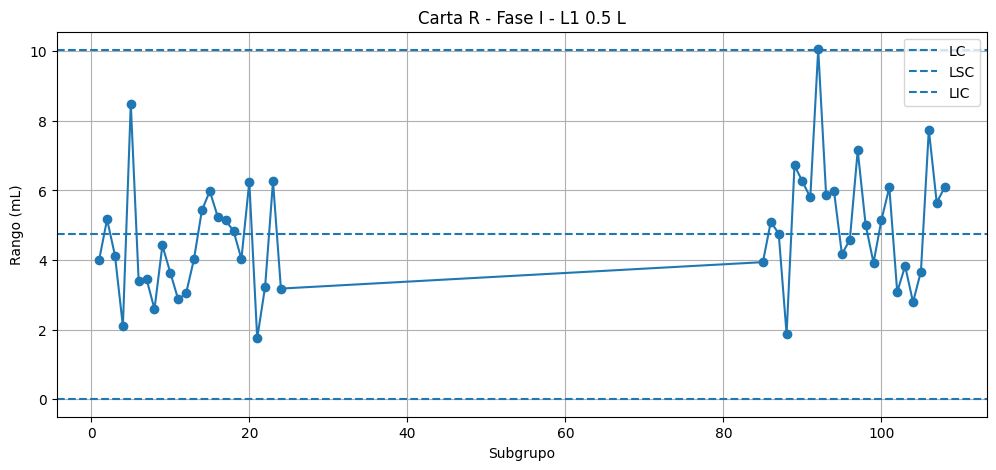

In [16]:
# Carta R - Fase I - L1 0.5 L

plt.figure(figsize=(12, 5))

plt.plot(
    fase1_L1_05["subgrupo"],
    fase1_L1_05["rango_volumen"],
    marker="o"
)

plt.axhline(LC_R, linestyle="--", label="LC")
plt.axhline(LSC_R, linestyle="--", label="LSC")
plt.axhline(LIC_R, linestyle="--", label="LIC")

plt.xlabel("Subgrupo")
plt.ylabel("Rango (mL)")
plt.title("Carta R - Fase I - L1 0.5 L")

plt.legend()
plt.grid()

plt.show()

In [17]:
# Crear orden consecutivo para los subgrupos de Fase I
fase1_L1_05 = fase1_L1_05.copy()

fase1_L1_05["orden"] = range(1, len(fase1_L1_05) + 1)

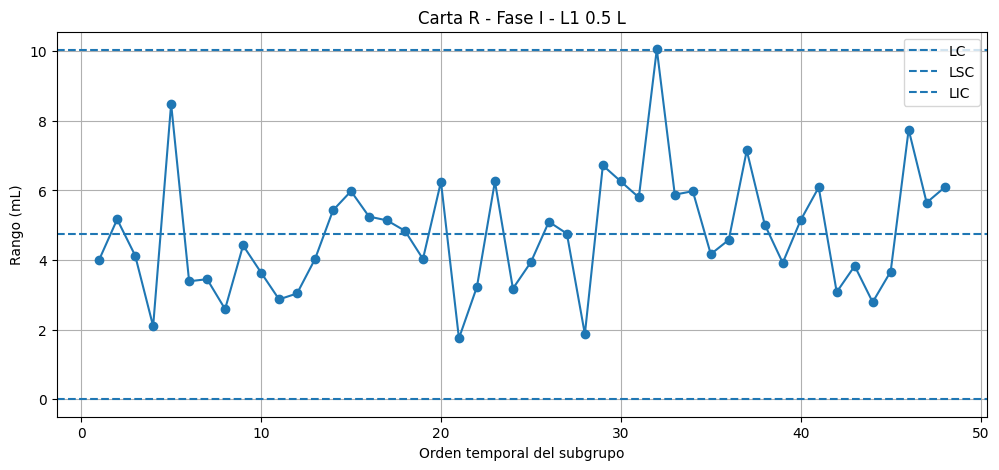

In [18]:
# Carta R - Fase I - L1 0.5 L

plt.figure(figsize=(12, 5))

plt.plot(
    fase1_L1_05["orden"],
    fase1_L1_05["rango_volumen"],
    marker="o"
)

plt.axhline(LC_R, linestyle="--", label="LC")
plt.axhline(LSC_R, linestyle="--", label="LSC")
plt.axhline(LIC_R, linestyle="--", label="LIC")

plt.xlabel("Orden temporal del subgrupo")
plt.ylabel("Rango (mL)")
plt.title("Carta R - Fase I - L1 0.5 L")

plt.legend()
plt.grid()

plt.show()

In [19]:
# Regla 1: punto fuera de los límites de control

regla1_R = fase1_L1_05[
    (fase1_L1_05["rango_volumen"] > LSC_R) |
    (fase1_L1_05["rango_volumen"] < LIC_R)
]

print("Regla 1 - Puntos fuera de los límites:")
display(regla1_R)

Regla 1 - Puntos fuera de los límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
91,92,502.946,10.06,L1,0.5,B (14-22),2,I,32


Se optó por aplicar un conjunto acotado de reglas de Nelson, evitando mezclar criterios de distintos sistemas y reduciendo el riesgo de falsas alarmas. Se consideraron tres patrones principales: puntos fuera de los límites de control, rachas prolongadas al mismo lado de la línea central y tendencias sostenidas crecientes o decrecientes. Esta selección permite detectar tanto señales extremas como comportamientos no aleatorios del proceso, manteniendo el análisis consistente con lo revisado en clases. 2_Calidad_II

In [20]:
# Regla 2 de Nelson:
# 9 puntos consecutivos al mismo lado de la línea central

valores_R = fase1_L1_05["rango_volumen"].tolist()
subgrupos_R = fase1_L1_05["subgrupo"].tolist()

senales_regla2 = []

for i in range(len(valores_R) - 8):

    grupo = valores_R[i:i+9]

    todos_arriba = all(valor > LC_R for valor in grupo)
    todos_abajo = all(valor < LC_R for valor in grupo)

    if todos_arriba or todos_abajo:
        senales_regla2.append(subgrupos_R[i:i+9])

print("Regla 2 - 9 puntos consecutivos al mismo lado de LC:")
print(senales_regla2)

Regla 2 - 9 puntos consecutivos al mismo lado de LC:
[]


In [21]:
# Tendencia de 6 puntos consecutivos en la carta R

senales_tendencia_R = []

for i in range(len(valores_R) - 5):

    grupo = valores_R[i:i+6]

    creciente = all(
        grupo[j] < grupo[j+1]
        for j in range(5)
    )

    decreciente = all(
        grupo[j] > grupo[j+1]
        for j in range(5)
    )

    if creciente or decreciente:
        senales_tendencia_R.append(
            subgrupos_R[i:i+6]
        )

print("Tendencias sostenidas detectadas en R:")
print(senales_tendencia_R)

Tendencias sostenidas detectadas en R:
[]


límites

In [22]:
LC_X = media_medias
LSC_X = media_medias + A2 * media_rangos
LIC_X = media_medias - A2 * media_rangos

In [23]:
fuera_X = fase1_L1_05[
    (fase1_L1_05["media_volumen"] > LSC_X) |
    (fase1_L1_05["media_volumen"] < LIC_X)
]

print("Subgrupos fuera de control en carta X barra:")
display(fuera_X)

Subgrupos fuera de control en carta X barra:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden


In [24]:
valores_X = fase1_L1_05["media_volumen"].tolist()
subgrupos_X = fase1_L1_05["subgrupo"].tolist()

In [25]:
senales_9_X = []

for i in range(len(valores_X) - 8):

    grupo = valores_X[i:i+9]

    todos_arriba = all(valor > LC_X for valor in grupo)
    todos_abajo = all(valor < LC_X for valor in grupo)

    if todos_arriba or todos_abajo:
        senales_9_X.append(subgrupos_X[i:i+9])

print("9 puntos consecutivos al mismo lado de LC:")
print(senales_9_X)

9 puntos consecutivos al mismo lado de LC:
[]


Tendencia

In [26]:
senales_tendencia_X = []

for i in range(len(valores_X) - 5):

    grupo = valores_X[i:i+6]

    creciente = all(
        grupo[j] < grupo[j+1]
        for j in range(5)
    )

    decreciente = all(
        grupo[j] > grupo[j+1]
        for j in range(5)
    )

    if creciente or decreciente:
        senales_tendencia_X.append(
            subgrupos_X[i:i+6]
        )

print("Tendencias sostenidas en X barra:")
print(senales_tendencia_X)

Tendencias sostenidas en X barra:
[]


La carta \(\bar X\) no presentó señales bajo ninguna de las tres reglas seleccionadas. La carta \(R\) presentó únicamente una señal aislada en el subgrupo 92, con \(R=10,06\) mL frente a un LSC de aproximadamente \(10,04\) mL. No se detectaron rachas ni tendencias sostenidas.

In [27]:
def analizar_fase1(datos_control, linea, formato):

    # Filtrar proceso y Fase I
    datos = datos_control[
        (datos_control["linea"] == linea) &
        (datos_control["formato_L"] == formato) &
        (datos_control["fase"] == "I")
    ].copy()

    # Orden temporal
    datos = datos.sort_values("subgrupo")
    datos["orden"] = range(1, len(datos) + 1)

    # Constantes para n = 5
    A2 = 0.577
    D3 = 0
    D4 = 2.114

    # -------------------------
    # Límites de control
    # -------------------------

    media_medias = datos["media_volumen"].mean()
    media_rangos = datos["rango_volumen"].mean()

    # Carta R
    LC_R = media_rangos
    LIC_R = D3 * media_rangos
    LSC_R = D4 * media_rangos

    # Carta X barra
    LC_X = media_medias
    LIC_X = media_medias - A2 * media_rangos
    LSC_X = media_medias + A2 * media_rangos

    print("PROCESO:", linea, "-", formato, "L")
    print("Cantidad de subgrupos:", len(datos))

    print("\nCarta R")
    print("LIC:", LIC_R)
    print("LC:", LC_R)
    print("LSC:", LSC_R)

    print("\nCarta X barra")
    print("LIC:", LIC_X)
    print("LC:", LC_X)
    print("LSC:", LSC_X)


    # =====================================================
    # CARTA R
    # =====================================================

    valores_R = datos["rango_volumen"].tolist()
    subgrupos_R = datos["subgrupo"].tolist()

    # Regla 1: fuera de límites
    fuera_R = datos[
        (datos["rango_volumen"] > LSC_R) |
        (datos["rango_volumen"] < LIC_R)
    ]

    # Regla 2: 9 puntos al mismo lado de LC
    senales_9_R = []

    for i in range(len(valores_R) - 8):

        grupo = valores_R[i:i+9]

        todos_arriba = all(valor > LC_R for valor in grupo)
        todos_abajo = all(valor < LC_R for valor in grupo)

        if todos_arriba or todos_abajo:
            senales_9_R.append(subgrupos_R[i:i+9])

    # Regla 3: tendencia de 6 puntos
    tendencia_R = []

    for i in range(len(valores_R) - 5):

        grupo = valores_R[i:i+6]

        creciente = all(
            grupo[j] < grupo[j+1]
            for j in range(5)
        )

        decreciente = all(
            grupo[j] > grupo[j+1]
            for j in range(5)
        )

        if creciente or decreciente:
            tendencia_R.append(subgrupos_R[i:i+6])


    # =====================================================
    # CARTA X BARRA
    # =====================================================

    valores_X = datos["media_volumen"].tolist()
    subgrupos_X = datos["subgrupo"].tolist()

    # Regla 1: fuera de límites
    fuera_X = datos[
        (datos["media_volumen"] > LSC_X) |
        (datos["media_volumen"] < LIC_X)
    ]

    # Regla 2: 9 puntos al mismo lado de LC
    senales_9_X = []

    for i in range(len(valores_X) - 8):

        grupo = valores_X[i:i+9]

        todos_arriba = all(valor > LC_X for valor in grupo)
        todos_abajo = all(valor < LC_X for valor in grupo)

        if todos_arriba or todos_abajo:
            senales_9_X.append(subgrupos_X[i:i+9])

    # Regla 3: tendencia de 6 puntos
    tendencia_X = []

    for i in range(len(valores_X) - 5):

        grupo = valores_X[i:i+6]

        creciente = all(
            grupo[j] < grupo[j+1]
            for j in range(5)
        )

        decreciente = all(
            grupo[j] > grupo[j+1]
            for j in range(5)
        )

        if creciente or decreciente:
            tendencia_X.append(subgrupos_X[i:i+6])


    # -------------------------
    # Mostrar resultados
    # -------------------------

    print("\n--- SEÑALES CARTA R ---")
    print("Fuera de límites:")
    display(fuera_R)

    print("9 puntos al mismo lado:")
    print(senales_9_R)

    print("Tendencias de 6 puntos:")
    print(tendencia_R)


    print("\n--- SEÑALES CARTA X BARRA ---")
    print("Fuera de límites:")
    display(fuera_X)

    print("9 puntos al mismo lado:")
    print(senales_9_X)

    print("Tendencias de 6 puntos:")
    print(tendencia_X)


    # -------------------------
    # Gráfico R
    # -------------------------

    plt.figure(figsize=(12, 5))

    plt.plot(
        datos["orden"],
        datos["rango_volumen"],
        marker="o"
    )

    plt.axhline(LC_R, linestyle="--", label="LC")
    plt.axhline(LSC_R, linestyle="--", label="LSC")
    plt.axhline(LIC_R, linestyle="--", label="LIC")

    plt.xlabel("Orden temporal del subgrupo")
    plt.ylabel("Rango del volumen (mL)")
    plt.title("Carta R - Fase I - " + linea + " " + str(formato) + " L")

    plt.legend()
    plt.grid()
    plt.show()


    # -------------------------
    # Gráfico X barra
    # -------------------------

    plt.figure(figsize=(12, 5))

    plt.plot(
        datos["orden"],
        datos["media_volumen"],
        marker="o"
    )

    plt.axhline(LC_X, linestyle="--", label="LC")
    plt.axhline(LSC_X, linestyle="--", label="LSC")
    plt.axhline(LIC_X, linestyle="--", label="LIC")

    plt.xlabel("Orden temporal del subgrupo")
    plt.ylabel("Media del volumen (mL)")
    plt.title("Carta X barra - Fase I - " + linea + " " + str(formato) + " L")

    plt.legend()
    plt.grid()
    plt.show()

PROCESO: L2 - 1.5 L
Cantidad de subgrupos: 52

Carta R
LIC: 0.0
LC: 11.658076923076937
LSC: 24.645174615384644

Carta X barra
LIC: 1497.7299819230768
LC: 1504.4566923076923
LSC: 1511.1834026923077

--- SEÑALES CARTA R ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
32,33,1505.642,25.95,L2,1.5,C (22-06),1,I,1


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[]

--- SEÑALES CARTA X BARRA ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
128,129,1513.752,9.26,L2,1.5,C (22-06),2,I,29


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[[158, 159, 160, 165, 166, 167]]


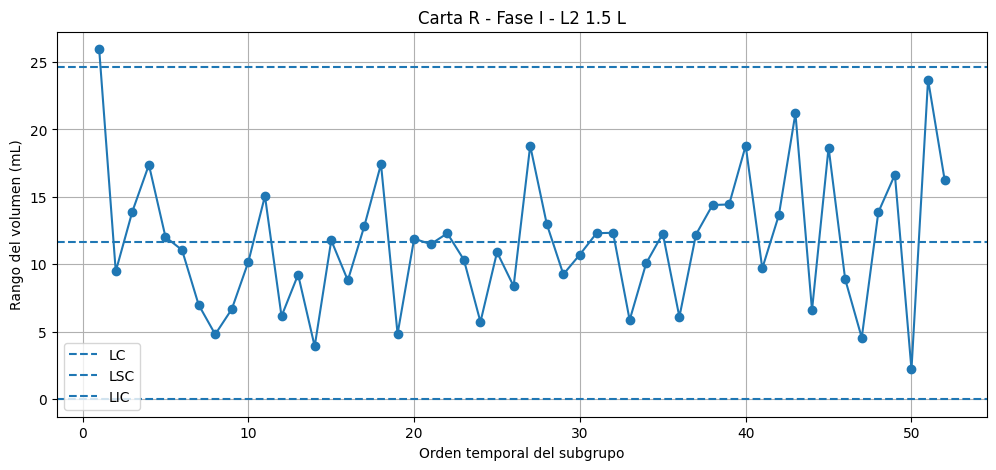

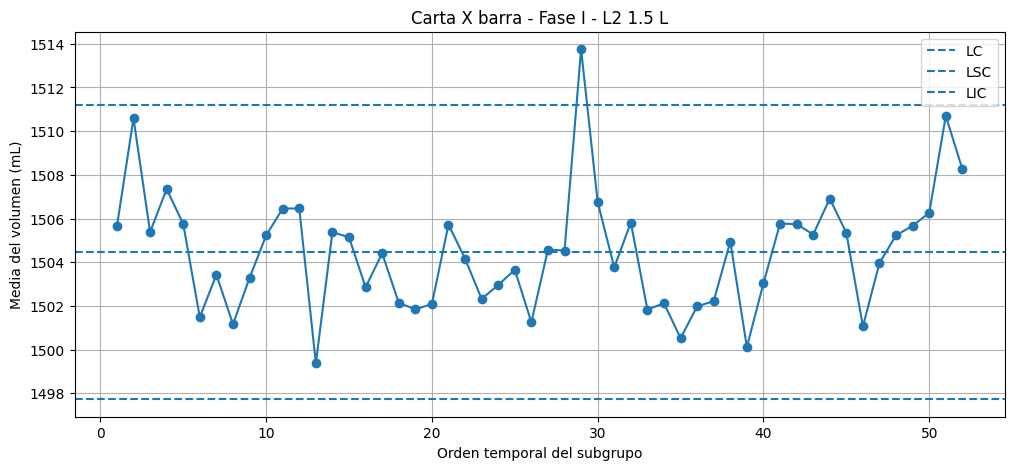

In [28]:
analizar_fase1(datos_control, "L2", 1.5)

La carta \(R\) muestra una señal puntual de variabilidad: el subgrupo 33 tiene \(R=25,95\) mL, superior al \(LSC_R=24,645\) mL. En cambio, la carta \(\bar X\) tiene dos tipos de señales: el subgrupo 129 está directamente sobre el límite superior, y además existe una secuencia de seis medias consecutivas con tendencia.

In [29]:
# Crear nuevamente la Fase I de L2 - 1.5 L
fase1_L2_15 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 1.5) &
    (datos_control["fase"] == "I")
].copy()

fase1_L2_15 = fase1_L2_15.sort_values("subgrupo")
fase1_L2_15["orden"] = range(1, len(fase1_L2_15) + 1)


# Subgrupos que presentaron señales
subgrupos_senal_15 = [
    33, 129,
    158, 159, 160, 165, 166, 167
]


# Recuperar SKU y hora desde los datos originales
info_subgrupo = llenado[
    ["subgrupo", "sku", "hora"]
].drop_duplicates()


# Filtrar solo los subgrupos señalados
diagnostico_15 = fase1_L2_15[
    fase1_L2_15["subgrupo"].isin(subgrupos_senal_15)
].copy()


# Agregar SKU y hora
diagnostico_15 = pd.merge(
    diagnostico_15,
    info_subgrupo,
    on="subgrupo",
    how="left"
)


# Mostrar información relevante
display(
    diagnostico_15[
        [
            "orden",
            "subgrupo",
            "semana_registro",
            "turno",
            "sku",
            "hora",
            "media_volumen",
            "rango_volumen"
        ]
    ]
)

,orden,subgrupo,semana_registro,turno,sku,hora,media_volumen,rango_volumen
0,1,33,1,C (22-06),NEC-D15,22:00,1505.642,25.95
1,29,129,2,C (22-06),NEC-D15,22:00,1513.752,9.26
2,46,158,2,A (06-14),FUN-B15,08:00,1501.064,8.90
3,47,159,2,A (06-14),FUN-B15,10:00,1503.966,4.56
4,48,160,2,A (06-14),FUN-B15,12:00,1505.232,13.86
5,49,165,2,C (22-06),FUN-B15,22:00,1505.674,16.65
6,50,166,2,C (22-06),FUN-B15,00:00,1506.258,2.21
7,51,167,2,C (22-06),FUN-B15,02:00,1510.700,23.70


El diagnóstico de las señales mostró dos comportamientos diferenciados. Los subgrupos 33 y 129 corresponden al SKU NEC-D15, fueron registrados durante el turno C a las 22:00 y pertenecen a semanas distintas, lo que sugiere investigar una posible condición asociada al inicio del turno nocturno o al ajuste de la línea para dicho SKU. Por otra parte, la tendencia detectada en la carta \(\bar X\) corresponde íntegramente al SKU FUN-B15 durante la semana 2. Las medias aumentan progresivamente desde 1501,064 hasta 1510,700 mL. Como la secuencia comprende tanto el turno A como el turno C, la señal no puede atribuirse exclusivamente a un turno y resulta más consistente con un comportamiento temporal asociado al SKU o a las condiciones de operación durante su producción.

PROCESO: L2 - 3.0 L
Cantidad de subgrupos: 68

Carta R
LIC: 0.0
LC: 18.49999999999996
LSC: 39.10899999999992

Carta X barra
LIC: 2998.0858529411767
LC: 3008.7603529411767
LSC: 3019.434852941177

--- SEÑALES CARTA R ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[[56, 57, 58, 59, 60, 65]]

--- SEÑALES CARTA X BARRA ---
Fuera de límites:


,subgrupo,media_volumen,rango_volumen,linea,formato_L,turno,semana_registro,fase,orden
56,57,3023.588,21.08,L2,3.0,C (22-06),1,I,21


9 puntos al mismo lado:
[]
Tendencias de 6 puntos:
[[79, 80, 81, 82, 83, 84]]


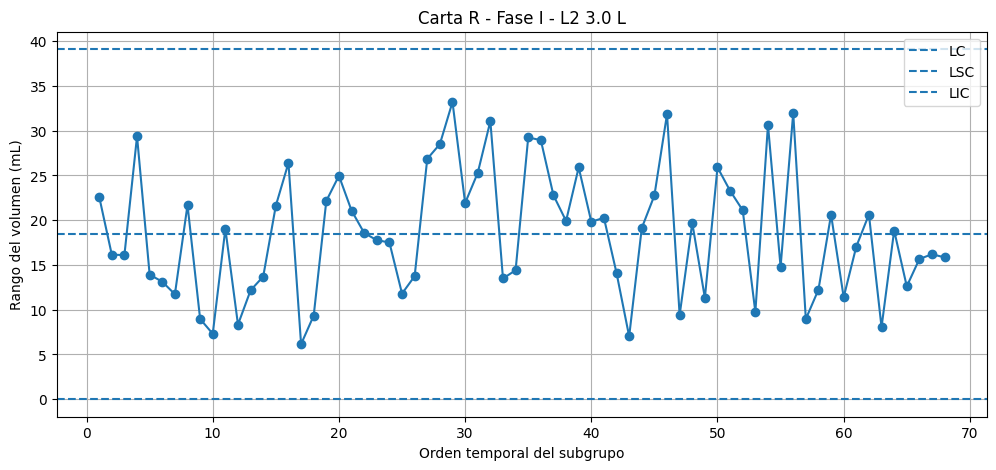

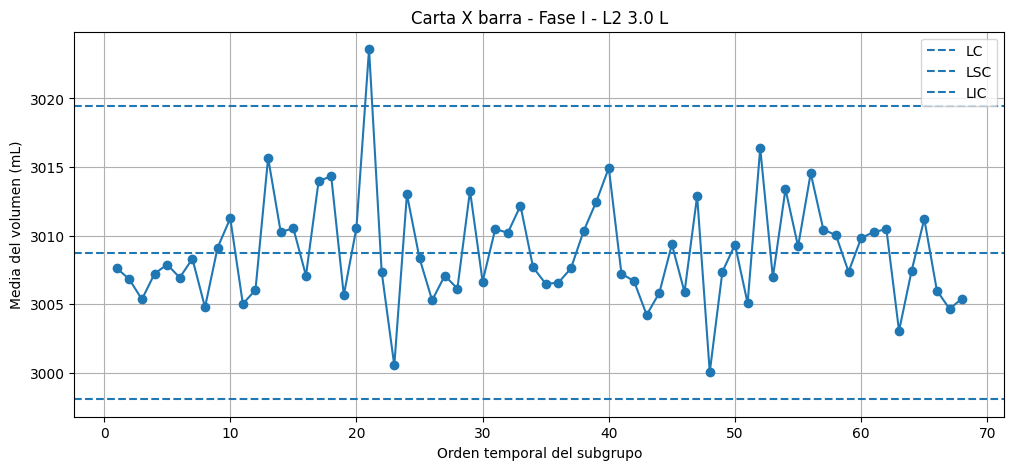

In [30]:
analizar_fase1(datos_control, "L2", 3.0)

Se analizaron los subgrupos identificados mediante las cartas de control y las reglas de Nelson durante la Fase I. Se revisaron sus medias y rangos, junto con las variables fecha, semana, turno, SKU y hora de registro, con el propósito de caracterizar las señales detectadas e identificar posibles asociaciones con las condiciones de operación

In [31]:
# DIAGNÓSTICO DE SEÑALES - L2 3.0 L

# 1. Recuperar los subgrupos de Fase I
fase1_L2_30 = datos_control[
    (datos_control["linea"] == "L2") &
    (datos_control["formato_L"] == 3.0) &
    (datos_control["fase"] == "I")
].copy()

fase1_L2_30 = fase1_L2_30.sort_values("subgrupo")

# 2. Identificar los subgrupos con señales
subgrupos_senal_30 = [
    56, 57, 58, 59, 60, 65,
    79, 80, 81, 82, 83, 84
]

# 3. Recuperar fecha, SKU y hora
info_subgrupo = llenado[
    ["subgrupo", "fecha", "sku", "hora"]
].drop_duplicates()

# 4. Seleccionar solamente los subgrupos señalados
diagnostico_30 = fase1_L2_30[
    fase1_L2_30["subgrupo"].isin(subgrupos_senal_30)
].copy()

# 5. Incorporar la información original
diagnostico_30 = pd.merge(
    diagnostico_30,
    info_subgrupo,
    on="subgrupo",
    how="left"
)

# 6. Mostrar resultados
display(
    diagnostico_30[
        [
            "subgrupo",
            "fecha",
            "semana_registro",
            "turno",
            "sku",
            "hora",
            "media_volumen",
            "rango_volumen"
        ]
    ]
)

,subgrupo,fecha,semana_registro,turno,sku,hora,media_volumen,rango_volumen
0,56,2026-07-22,1,B (14-22),FUN-B30,20:00,3010.568,24.97
1,57,2026-07-22,1,C (22-06),FUN-B30,22:00,3023.588,21.08
2,58,2026-07-22,1,C (22-06),FUN-B30,00:00,3007.366,18.58
3,59,2026-07-22,1,C (22-06),FUN-B30,02:00,3000.548,17.77
4,60,2026-07-22,1,C (22-06),FUN-B30,04:00,3013.016,17.52
5,65,2026-07-23,1,B (14-22),NEC-D30,14:00,3008.356,11.80
6,79,2026-07-24,1,B (14-22),NEC-D30,18:00,3006.496,29.25
7,80,2026-07-24,1,B (14-22),NEC-D30,20:00,3006.574,28.95
8,81,2026-07-24,1,C (22-06),NEC-D30,22:00,3007.624,22.79
9,82,2026-07-24,1,C (22-06),NEC-D30,00:00,3010.328,19.92


Durante la Fase I del proceso L2–3,0 L se identificaron señales de comportamiento no aleatorio tanto en la dispersión como en el nivel medio de llenado.

En la carta R se detectó una tendencia decreciente de seis subgrupos consecutivos, cuyos rangos disminuyeron desde 24,97 hasta 11,80 mL. Esta secuencia comprende principalmente el SKU FUN-B30, finalizando con NEC-D30, por lo que podría estar relacionada con cambios en las condiciones operacionales o en el producto procesado.

En la carta X̄ se identificó al subgrupo 57 con una media de 3.023,588 mL, superior al límite de control de 3.019,435 mL. Además, se detectó una tendencia creciente de seis medias consecutivas, desde 3.006,496 hasta 3.014,944 mL, correspondientes al SKU NEC-D30 durante la semana 1.

Las señales sugieren posibles variaciones asociadas a ajustes del equipo, condiciones de operación o cambios de SKU. Sin embargo, la información disponible no permite establecer una causa asignable definitiva, por lo que las observaciones se conservan y las señales se documentan para su evaluación posterior.

no tenemos evidencia suficiente para afirmar que el proceso estuvo completamente bajo control estadístico durante las semanas 1 y 2


In [32]:
# BLOQUE: RESUMEN DE SEÑALES DETECTADAS EN FASE I

# Crear tabla resumen con las señales identificadas

resumen_fase1 = pd.DataFrame({

    "Proceso": [
        "L1 - 0.5 L",
        "L2 - 1.5 L",
        "L2 - 1.5 L",
        "L2 - 1.5 L",
        "L2 - 3.0 L",
        "L2 - 3.0 L",
        "L2 - 3.0 L"
    ],

    "Carta": [
        "R", "R", "X barra", "X barra",
        "R", "X barra", "X barra"
    ],

    "Regla": [
        "Fuera de límites",
        "Fuera de límites",
        "Fuera de límites",
        "Tendencia 6 puntos",
        "Tendencia 6 puntos",
        "Fuera de límites",
        "Tendencia 6 puntos"
    ],

    "Subgrupos": [
        "92",
        "33",
        "129",
        "158, 159, 160, 165, 166, 167",
        "56, 57, 58, 59, 60, 65",
        "57",
        "79, 80, 81, 82, 83, 84"
    ],

    "Posible causa": [
        "Variación puntual del llenado",
        "Dispersión elevada en turno C",
        "Posible ajuste al inicio del turno C",
        "Posible deriva durante producción de FUN-B15",
        "Cambio gradual de variabilidad entre SKU",
        "Posible ajuste al inicio del turno C",
        "Posible deriva durante producción de NEC-D30"
    ],

    "Causa confirmada": [
        "No", "No", "No", "No",
        "No", "No", "No"
    ],

    "Decisión": [
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar",
        "Conservar y documentar"
    ]
})

display(resumen_fase1)

,Proceso,Carta,Regla,Subgrupos,Posible causa,Causa confirmada,Decisión
0,L1 - 0.5 L,R,Fuera de límites,92,Variación puntual del llenado,No,Conservar y documentar
1,L2 - 1.5 L,R,Fuera de límites,33,Dispersión elevada en turno C,No,Conservar y documentar
2,L2 - 1.5 L,X barra,Fuera de límites,129,Posible ajuste al inicio del turno C,No,Conservar y documentar
3,L2 - 1.5 L,X barra,Tendencia 6 puntos,"158, 159, 160, 165, 166, 167",Posible deriva durante producción de FUN-B15,No,Conservar y documentar
4,L2 - 3.0 L,R,Tendencia 6 puntos,"56, 57, 58, 59, 60, 65",Cambio gradual de variabilidad entre SKU,No,Conservar y documentar
5,L2 - 3.0 L,X barra,Fuera de límites,57,Posible ajuste al inicio del turno C,No,Conservar y documentar
6,L2 - 3.0 L,X barra,Tendencia 6 puntos,"79, 80, 81, 82, 83, 84",Posible deriva durante producción de NEC-D30,No,Conservar y documentar


Se consolidaron las señales identificadas mediante las cartas \(\bar X-R\) y las reglas de Nelson para las tres combinaciones línea–formato. La tabla permite comparar los comportamientos anormales detectados, identificar los subgrupos involucrados y registrar las posibles causas operacionales. Las hipótesis planteadas no se consideran causas asignables confirmadas, por lo que los registros se mantienen en la base original.

Ahora hay que distinguir las señales estadísticas de posibles errores en los datos

In [33]:
# BLOQUE: VERIFICACIÓN DE DATOS EN SUBGRUPOS SEÑALADOS

# Reunir los identificadores de todos los subgrupos señalados
subgrupos_senalados = [
    92, 33, 129,
    158, 159, 160, 165, 166, 167,
    56, 57, 58, 59, 60, 65,
    79, 80, 81, 82, 83, 84
]

revision_datos = []

for sg in sorted(set(subgrupos_senalados)):

    datos_sg = llenado[
        llenado["subgrupo"] == sg
    ]

    # Cantidad de mediciones
    cantidad = len(datos_sg)

    # Revisar faltantes
    faltantes = datos_sg.isnull().sum().sum()

    # Revisar observaciones numeradas 1 a 5
    numeracion_correcta = (
        sorted(datos_sg["n_obs"].tolist()) == [1, 2, 3, 4, 5]
    )

    # Revisar consistencia del formato
    formato_correcto = datos_sg["formato_L"].nunique() == 1

    # Revisar volúmenes válidos
    volumen_positivo = (datos_sg["volumen_mL"] > 0).all()

    revision_datos.append({
        "subgrupo": sg,
        "mediciones": cantidad,
        "faltantes": faltantes,
        "numeracion_correcta": numeracion_correcta,
        "formato_consistente": formato_correcto,
        "volumen_positivo": volumen_positivo
    })

tabla_verificacion = pd.DataFrame(revision_datos)

display(tabla_verificacion)

,subgrupo,mediciones,faltantes,numeracion_correcta,formato_consistente,volumen_positivo
0,33,5,0,True,True,True
1,56,5,0,True,True,True
2,57,5,0,True,True,True
3,58,5,0,True,True,True
4,59,5,0,True,True,True
5,60,5,0,True,True,True
6,65,5,0,True,True,True
7,79,5,0,True,True,True
8,80,5,0,True,True,True
9,81,5,0,True,True,True


Verificación de integridad de los subgrupos señalados
Se revisaron las mediciones individuales de los subgrupos que presentaron señales estadísticas durante la Fase I, con el objetivo de identificar posibles problemas de registro, valores faltantes o inconsistencias respecto del formato de envase. Esta revisión permite diferenciar anomalías estadísticas de posibles errores de datos, evitando excluir observaciones válidas sin una justificación técnica.

Ahora nos preguntamos ¿Los subgrupos del turno C presentan, en general, medias o rangos mayores que los otros turnos dentro del mismo proceso?

In [34]:
# BLOQUE: EVALUACIÓN DE POSIBLES CAUSAS - TURNOS

# Seleccionar únicamente Fase I
datos_fase1 = datos_control[
    datos_control["fase"] == "I"
].copy()

# Comparar media y rango por proceso y turno
comparacion_turnos = datos_fase1.groupby(
    ["linea", "formato_L", "turno"]
)[["media_volumen", "rango_volumen"]].agg(
    ["count", "mean"]
)

print("Comparación de procesos según turno:")
display(comparacion_turnos)

Comparación de procesos según turno:


media_volumen              rango_volumen           
                                  count         mean         count       mean
linea formato_L turno                                                        
L1    0.5       A (06-14)            24   502.431750            24   4.237917
                B (14-22)            24   502.855500            24   5.261250
L2    1.5       A (06-14)            28  1503.083500            28  10.247857
                B (14-22)             4  1502.581500             4  14.962500
                C (22-06)            20  1506.754200            20  12.971500
      3.0       A (06-14)            12  3009.026500            12  17.616667
                B (14-22)            36  3007.904389            36  16.690556
                C (22-06)            20  3010.141400            20  22.287000

Una vez verificada la integridad básica de los subgrupos señalados, se procedió a contrastar las anomalías estadísticas con las condiciones de operación. Se analizaron las diferencias en el nivel medio y la dispersión del volumen según línea, formato y turno durante la Fase I, con el objetivo de identificar posibles asociaciones entre las señales detectadas y las características del proceso productivo.

Este análisis es exploratorio y permite formular hipótesis operacionales, sin establecer relaciones causales definitivas.

Proceso	Hallazgo principal
L1–0,5 L	El turno B tiene mayor rango promedio (5,26 mL) que A (4,24 mL).
L2–1,5 L	El turno C presenta la media más alta (1.506,75 mL).
L2–3,0 L	El turno C presenta tanto la media más alta (3.010,14 mL) como el rango promedio más alto (22,29 mL).

**DECISION PARA FASE 2!!!!!:**
Después de revisar las anomalías detectadas en los tres procesos, comprobamos que los subgrupos tenían sus cinco mediciones, no presentaban datos faltantes y cumplían las verificaciones básicas realizadas.

Aunque encontramos valores fuera de los límites de control y algunas tendencias, no logramos identificar una causa específica que permitiera justificar la eliminación de esos registros.

Por esta razón, decidimos conservar todos los datos y mantener los límites calculados inicialmente, evitando modificar los resultados sin una justificación.

Sin embargo, como se detectaron señales de comportamiento anormal, todavía no podemos afirmar que los procesos sean completamente estables. Por lo tanto, utilizaremos estos límites de manera provisional para analizar las semanas siguientes (Fase II), dejando constancia de esta limitación.

In [35]:
# BLOQUE: DECISIÓN SOBRE LÍMITES DE FASE I

decision_limites = pd.DataFrame({
    "Proceso": [
        "L1 - 0.5 L",
        "L2 - 1.5 L",
        "L2 - 3.0 L"
    ],

    "Subgrupos_Fase_I": [
        48, 52, 68
    ],

    "Causa_asignable_confirmada": [
        "No", "No", "No"
    ],

    "Exclusiones": [
        0, 0, 0
    ],

    "Decision": [
        "Conservar límites preliminares",
        "Conservar límites preliminares",
        "Conservar límites preliminares"
    ],

    "Estado": [
        "Estabilidad no demostrada",
        "Estabilidad no demostrada",
        "Estabilidad no demostrada"
    ]
})

display(decision_limites)

,Proceso,Subgrupos_Fase_I,Causa_asignable_confirmada,Exclusiones,Decision,Estado
0,L1 - 0.5 L,48,No,0,Conservar límites preliminares,Estabilidad no demostrada
1,L2 - 1.5 L,52,No,0,Conservar límites preliminares,Estabilidad no demostrada
2,L2 - 3.0 L,68,No,0,Conservar límites preliminares,Estabilidad no demostrada


**PREPARACION FASE 2**
Para saber:
Fase I (semanas 1 y 2): calculamos límites, detectamos anomalías e investigamos posibles causas.
Fase II (semanas 3 a 10): evaluaremos si los nuevos subgrupos presentan señales utilizando los mismos límites.


In [36]:
#PREPARACIÓN FASE 2
# BLOQUE: GUARDAR LÍMITES DE FASE I

# Constantes para subgrupos de 5 botellas
A2 = 0.577
D3 = 0
D4 = 2.114

limites_fase1 = []

# Procesos que estamos analizando
procesos = [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]

for linea, formato in procesos:

    # Seleccionar únicamente los subgrupos de Fase I
    datos = datos_control[
        (datos_control["linea"] == linea) &
        (datos_control["formato_L"] == formato) &
        (datos_control["fase"] == "I")
    ]

    # Promedio de medias y rangos
    media_medias = datos["media_volumen"].mean()
    media_rangos = datos["rango_volumen"].mean()

    # Guardar límites de ambas cartas
    limites_fase1.append({
        "linea": linea,
        "formato_L": formato,
        "LIC_R": D3 * media_rangos,
        "LC_R": media_rangos,
        "LSC_R": D4 * media_rangos,
        "LIC_X": media_medias - A2 * media_rangos,
        "LC_X": media_medias,
        "LSC_X": media_medias + A2 * media_rangos
    })

limites_fase1 = pd.DataFrame(limites_fase1)

display(limites_fase1.round(3))

,linea,formato_L,LIC_R,LC_R,LSC_R,LIC_X,LC_X,LSC_X
0,L1,0.5,0.0,4.750,10.041,499.903,502.644,505.384
1,L2,1.5,0.0,11.658,24.645,1497.730,1504.457,1511.183
2,L2,3.0,0.0,18.500,39.109,2998.086,3008.760,3019.435


Preparación de la Fase II

Para evaluar el comportamiento del llenado durante las semanas 3 a 10, se utilizarán los límites preliminares obtenidos en Fase I (semanas 1 y 2). Estos límites se mantendrán constantes durante el monitoreo, evitando recalcularlos con las nuevas observaciones.

Debido a las señales detectadas durante Fase I, los resultados de Fase II se interpretarán como una evaluación provisional del proceso.

In [37]:
# BLOQUE: SELECCIÓN DE DATOS PARA FASE II

fase2 = datos_control[
    datos_control["fase"] == "II"
].copy()

# Revisar cantidad total de subgrupos
print("Total de subgrupos en Fase II:")
print(fase2.shape[0])

# Revisar distribución por proceso
print("\nSubgrupos por línea y formato:")
print(
    fase2.groupby(["linea", "formato_L"]).size()
)

Total de subgrupos en Fase II:
672

Subgrupos por línea y formato:
linea  formato_L
L1     0.5          192
L2     1.5          236
       3.0          244
dtype: int64


Selección de datos para Fase II

Para desarrollar el monitoreo de Fase II se seleccionaron los subgrupos correspondientes a las semanas 3 a 10. Estos datos se evaluarán utilizando los límites preliminares obtenidos durante las semanas 1 y 2, sin modificarlos ni recalcularlos con las nuevas observaciones.

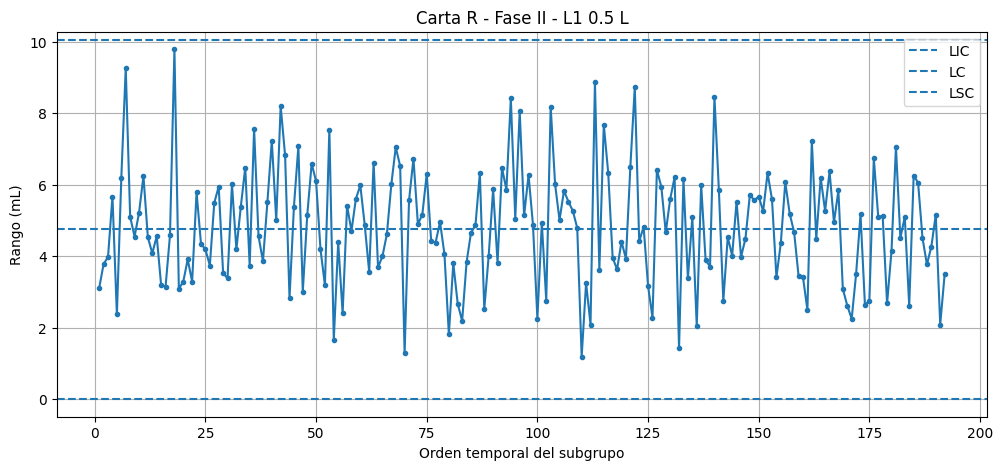

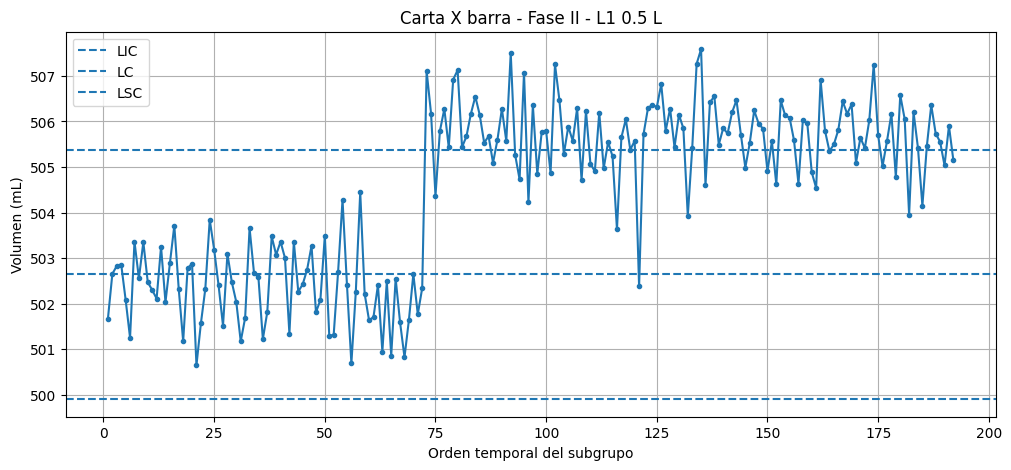

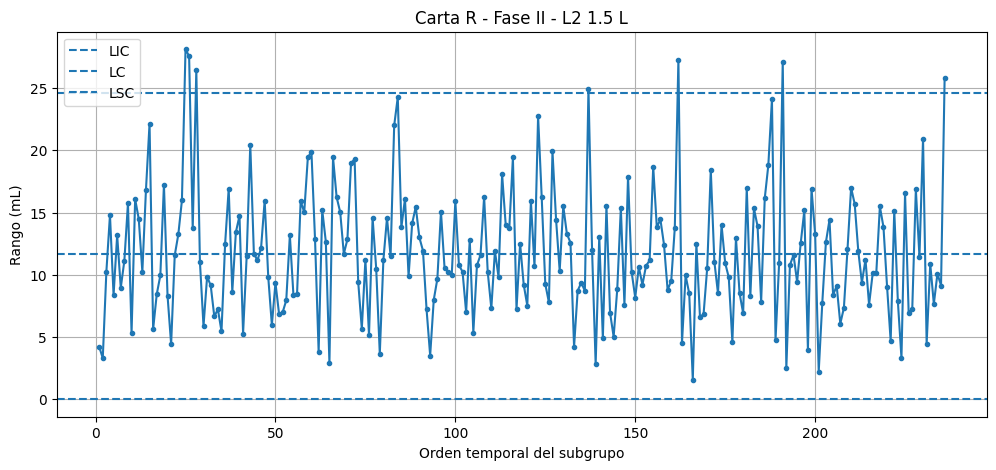

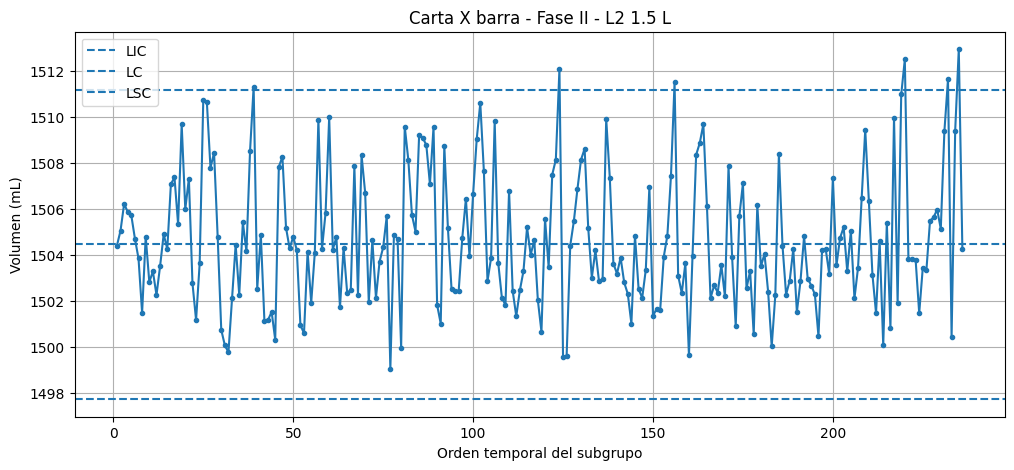

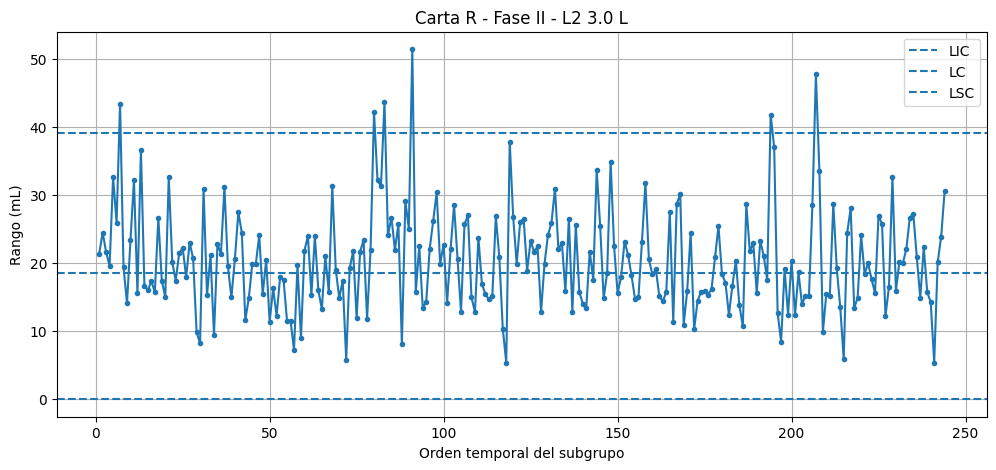

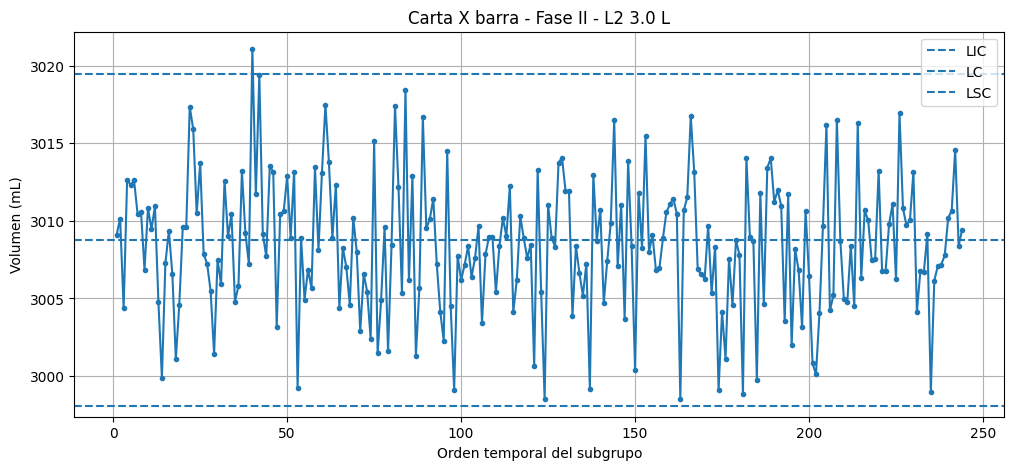

In [38]:
# BLOQUE: CARTAS DE CONTROL - FASE II


def graficar_fase2(linea, formato):

    # Seleccionar el proceso en Fase II
    datos = fase2[
        (fase2["linea"] == linea) &
        (fase2["formato_L"] == formato)
    ].copy()

    datos = datos.sort_values("subgrupo")
    datos["orden"] = range(1, len(datos) + 1)

    # Recuperar los límites calculados en Fase I
    limites = limites_fase1[
        (limites_fase1["linea"] == linea) &
        (limites_fase1["formato_L"] == formato)
    ].iloc[0]

    # Graficar ambas cartas
    for variable, nombre, tipo in [
        ("rango_volumen", "R", "R"),
        ("media_volumen", "X barra", "X")
    ]:

        LIC = limites["LIC_" + tipo]
        LC = limites["LC_" + tipo]
        LSC = limites["LSC_" + tipo]

        plt.figure(figsize=(12, 5))

        plt.plot(
            datos["orden"],
            datos[variable],
            marker="o",
            markersize=3
        )

        plt.axhline(LIC, linestyle="--", label="LIC")
        plt.axhline(LC, linestyle="--", label="LC")
        plt.axhline(LSC, linestyle="--", label="LSC")

        plt.xlabel("Orden temporal del subgrupo")
        plt.ylabel("Volumen (mL)" if tipo == "X" else "Rango (mL)")
        plt.title(
            "Carta " + nombre + " - Fase II - " +
            linea + " " + str(formato) + " L"
        )

        plt.legend()
        plt.grid()
        plt.show()



# Ejecutar las cartas de Fase II para los tres procesos

graficar_fase2("L1", 0.5)

graficar_fase2("L2", 1.5)

graficar_fase2("L2", 3.0)

### Análisis de las cartas de control – Fase II

Una vez terminada la revisión de la Fase I, se comenzó el análisis de la Fase II, utilizando los datos correspondientes a las semanas 3 a 10. En esta etapa se analizaron 672 subgrupos, distribuidos entre los tres procesos de llenado: L1–0,5 L (192 subgrupos), L2–1,5 L (236 subgrupos) y L2–3,0 L (244 subgrupos).

El objetivo de esta etapa es evaluar si el comportamiento del proceso de llenado se mantiene similar al observado durante las primeras dos semanas. Para ello, se utilizaron los límites de control calculados en la Fase I, manteniéndolos sin modificaciones.

Es importante recordar que durante la Fase I se detectaron algunas señales de comportamiento anormal que no pudieron asociarse a causas confirmadas. Por esta razón, los límites utilizados son provisionales y los resultados de esta segunda etapa deben interpretarse considerando esa limitación.

**¿Qué representan los gráficos?**

Para cada combinación de línea y formato se construyeron dos cartas de control:

**1. Carta R: análisis de la variabilidad**

Esta carta permite observar cuánto varía el volumen entre las cinco botellas de un mismo subgrupo.

Cada punto del gráfico representa el rango de un subgrupo, calculado como la diferencia entre la botella con mayor volumen y la de menor volumen.

La carta R permite identificar si la dispersión del llenado se mantiene similar a la del período inicial o si aparecen cambios importantes.

Por ejemplo, un punto con un rango elevado significa que las cinco botellas de ese subgrupo presentan diferencias de volumen mayores de lo habitual.

**2. Carta X̄: análisis del promedio de llenado**

Esta carta muestra cómo cambia el volumen promedio de las cinco botellas de cada subgrupo a lo largo del tiempo.

Cada punto representa la media de un subgrupo.

Su objetivo es detectar si el proceso comienza a llenar, en promedio, con cantidades más altas o más bajas que las observadas durante la Fase I.

Por ejemplo, un aumento sostenido de las medias podría indicar que el proceso está entregando progresivamente más producto del esperado.

**¿Qué significan las líneas de los gráficos?**

Ambas cartas tienen tres líneas horizontales:

- **LIC (Límite Inferior de Control):** indica el límite inferior esperado para el comportamiento estadístico del proceso.
- **LC (Línea Central):** representa el valor promedio utilizado como referencia, calculado durante la Fase I.
- **LSC (Límite Superior de Control):** indica el límite superior esperado para el comportamiento estadístico del proceso.

Cuando un punto supera el LSC o queda por debajo del LIC, se identifica una señal de posible causa especial que debe investigarse.

Sin embargo, un proceso también puede presentar comportamientos anormales aunque todos los puntos estén dentro de los límites. Por eso, además de observar los gráficos, se aplicarán las reglas de Nelson seleccionadas anteriormente.

**¿Qué buscamos comprobar en Fase II?**

Buscamos identificar si durante las semanas 3 a 10 aparecen cambios en el promedio o la variabilidad del llenado.

Para ello, se revisarán los puntos fuera de los límites de control, las secuencias de nueve puntos consecutivos al mismo lado de la línea central y las tendencias de seis puntos consecutivos crecientes o decrecientes.

Los resultados permitirán identificar los períodos que requieren mayor atención y relacionar las señales con las condiciones de producción, como el turno, la semana y el SKU.

Es importante señalar que los límites de control no son lo mismo que los límites de especificación del producto. Las cartas permiten estudiar la estabilidad estadística del proceso, mientras que el cumplimiento de las especificaciones se evaluará posteriormente mediante el análisis de capacidad.

In [39]:
# BLOQUE: REGLAS DE NELSON - FASE II

def detectar_senales(datos, columna, carta, limites, proceso):

    valores = datos[columna].tolist()
    subgrupos = datos["subgrupo"].tolist()

    LIC = limites["LIC_" + carta]
    LC = limites["LC_" + carta]
    LSC = limites["LSC_" + carta]

    senales = []

    # Regla 1: puntos fuera de límites
    for i in range(len(valores)):

        if valores[i] > LSC or valores[i] < LIC:
            senales.append([
                proceso, carta, "Fuera de límites",
                str(subgrupos[i])
            ])

    # Regla 2: 9 puntos al mismo lado de LC
    for i in range(len(valores) - 8):

        grupo = valores[i:i+9]

        arriba = all(x > LC for x in grupo)
        abajo = all(x < LC for x in grupo)

        if arriba or abajo:
            senales.append([
                proceso, carta, "9 puntos mismo lado",
                str(subgrupos[i:i+9])
            ])

    # Regla 3: tendencia de 6 puntos
    for i in range(len(valores) - 5):

        grupo = valores[i:i+6]

        creciente = all(
            grupo[j] < grupo[j+1] for j in range(5)
        )

        decreciente = all(
            grupo[j] > grupo[j+1] for j in range(5)
        )

        if creciente or decreciente:
            senales.append([
                proceso, carta, "Tendencia 6 puntos",
                str(subgrupos[i:i+6])
            ])

    return senales


# Aplicar las reglas a los tres procesos
resultados = []

for linea, formato in [("L1", 0.5), ("L2", 1.5), ("L2", 3.0)]:

    datos = fase2[
        (fase2["linea"] == linea) &
        (fase2["formato_L"] == formato)
    ].sort_values(["semana_registro", "subgrupo"])

    limites = limites_fase1[
        (limites_fase1["linea"] == linea) &
        (limites_fase1["formato_L"] == formato)
    ].iloc[0]

    proceso = linea + " - " + str(formato) + " L"

    resultados += detectar_senales(
        datos, "rango_volumen", "R", limites, proceso
    )

    resultados += detectar_senales(
        datos, "media_volumen", "X", limites, proceso
    )


# Crear tabla con los resultados
senales_fase2 = pd.DataFrame(
    resultados,
    columns=["Proceso", "Carta", "Regla", "Subgrupos"]
)

print("Señales detectadas en Fase II:")
display(senales_fase2)

Señales detectadas en Fase II:


,Proceso,Carta,Regla,Subgrupos
0,L1 - 0.5 L,R,Tendencia 6 puntos,"[684, 685, 686, 687, 688, 689]"
1,L1 - 0.5 L,X,Fuera de límites,421
2,L1 - 0.5 L,X,Fuera de límites,422
3,L1 - 0.5 L,X,Fuera de límites,424
4,L1 - 0.5 L,X,Fuera de límites,425
...,...,...,...,...
222,L2 - 3.0 L,X,9 puntos mismo lado,"[641, 642, 643, 644, 645, 646, 647, 648, 649]"
223,L2 - 3.0 L,X,Tendencia 6 puntos,"[572, 577, 578, 579, 580, 613]"
224,L2 - 3.0 L,X,Tendencia 6 puntos,"[823, 824, 829, 830, 831, 832]"
225,L2 - 3.0 L,X,Tendencia 6 puntos,"[824, 829, 830, 831, 832, 833]"


In [40]:


print("L1 - 0.5 L")
display(
    senales_fase2[
        senales_fase2["Proceso"] == "L1 - 0.5 L"
    ]
)

print("L2 - 1.5 L")
display(
    senales_fase2[
        senales_fase2["Proceso"] == "L2 - 1.5 L"
    ]
)

print("L2 - 3.0 L")
display(
    senales_fase2[
        senales_fase2["Proceso"] == "L2 - 3.0 L"
    ]
)

L1 - 0.5 L


,Proceso,Carta,Regla,Subgrupos
0,L1 - 0.5 L,R,Tendencia 6 puntos,"[684, 685, 686, 687, 688, 689]"
1,L1 - 0.5 L,X,Fuera de límites,421
2,L1 - 0.5 L,X,Fuera de límites,422
3,L1 - 0.5 L,X,Fuera de límites,424
4,L1 - 0.5 L,X,Fuera de límites,425
...,...,...,...,...
190,L1 - 0.5 L,X,9 puntos mismo lado,"[768, 769, 770, 771, 772, 773, 774, 775, 776]"
191,L1 - 0.5 L,X,9 puntos mismo lado,"[769, 770, 771, 772, 773, 774, 775, 776, 777]"
192,L1 - 0.5 L,X,9 puntos mismo lado,"[770, 771, 772, 773, 774, 775, 776, 777, 778]"
193,L1 - 0.5 L,X,9 puntos mismo lado,"[771, 772, 773, 774, 775, 776, 777, 778, 779]"


L2 - 1.5 L


,Proceso,Carta,Regla,Subgrupos
195,L2 - 1.5 L,R,Fuera de límites,249
196,L2 - 1.5 L,R,Fuera de límites,250
197,L2 - 1.5 L,R,Fuera de límites,252
198,L2 - 1.5 L,R,Fuera de límites,585
199,L2 - 1.5 L,R,Fuera de límites,670
200,L2 - 1.5 L,R,Fuera de límites,735
201,L2 - 1.5 L,R,Fuera de límites,840
202,L2 - 1.5 L,X,Fuera de límites,287
203,L2 - 1.5 L,X,Fuera de límites,564
204,L2 - 1.5 L,X,Fuera de límites,636


L2 - 3.0 L


,Proceso,Carta,Regla,Subgrupos
212,L2 - 3.0 L,R,Fuera de límites,203
213,L2 - 3.0 L,R,Fuera de límites,392
214,L2 - 3.0 L,R,Fuera de límites,395
215,L2 - 3.0 L,R,Fuera de límites,407
216,L2 - 3.0 L,R,Fuera de límites,666
217,L2 - 3.0 L,R,Fuera de límites,719
218,L2 - 3.0 L,R,9 puntos mismo lado,"[391, 392, 393, 394, 395, 396, 397, 398, 399]"
219,L2 - 3.0 L,R,9 puntos mismo lado,"[479, 480, 481, 482, 483, 484, 493, 494, 495]"
220,L2 - 3.0 L,X,Fuera de límites,300
221,L2 - 3.0 L,X,9 puntos mismo lado,"[640, 641, 642, 643, 644, 645, 646, 647, 648]"


Se aplicaron las tres reglas de Nelson utilizadas anteriormente para detectar posibles anomalías durante la Fase II. El análisis se realizó por separado para cada línea y formato, utilizando los límites establecidos en Fase I, con el objetivo de identificar cambios en la variabilidad y en el promedio de llenado.
*resultado** : los gráficos nos permitieron observar cómo se comportó el llenado y las reglas de Nelson nos ayudaron a detectar posibles cambios. Ahora tenemos que organizar e investigar esas señales para completar correctamente la Fase II.

In [41]:
# Resumen de las señales detectadas en Fase II

resumen_senales_fase2 = (
    senales_fase2
    .groupby(["Proceso", "Carta", "Regla"])
    .size()
    .reset_index(name="Cantidad de detecciones")
)

display(resumen_senales_fase2)

,Proceso,Carta,Regla,Cantidad de detecciones
0,L1 - 0.5 L,R,Tendencia 6 puntos,1
1,L1 - 0.5 L,X,9 puntos mismo lado,106
2,L1 - 0.5 L,X,Fuera de límites,88
3,L2 - 1.5 L,R,Fuera de límites,7
4,L2 - 1.5 L,X,9 puntos mismo lado,1
5,L2 - 1.5 L,X,Fuera de límites,6
6,L2 - 1.5 L,X,Tendencia 6 puntos,3
7,L2 - 3.0 L,R,9 puntos mismo lado,2
8,L2 - 3.0 L,R,Fuera de límites,6
9,L2 - 3.0 L,X,9 puntos mismo lado,2


La tabla nos muestra cuantas veces se activo cada regla de nelson durante la fase 2,
### Resultados de las reglas de Nelson – Fase II

Al aplicar las reglas de Nelson se identificaron distintas señales de posibles cambios en los procesos de llenado. El resultado más destacado corresponde a L1–0,5 L, donde 88 de los 192 subgrupos presentaron promedios fuera de los límites de control. En L2–1,5 L y L2–3,0 L también se detectaron señales relacionadas con el promedio y la variabilidad.

Estos resultados requieren una revisión por semana, turno y SKU para investigar posibles causas. Además, algunas secuencias detectadas se superponen, por lo que no deben contarse como anomalías independientes.

In [42]:
# Revisar puntos fuera de límites por semana

revision = fase2.merge(
    limites_fase1,
    on=["linea", "formato_L"]
)

revision["fuera_X"] = (
    (revision["media_volumen"] < revision["LIC_X"]) |
    (revision["media_volumen"] > revision["LSC_X"])
)

revision["fuera_R"] = (
    (revision["rango_volumen"] < revision["LIC_R"]) |
    (revision["rango_volumen"] > revision["LSC_R"])
)

resumen_semanal = revision.groupby(
    ["linea", "formato_L", "semana_registro"]
)[["fuera_X", "fuera_R"]].sum()

display(resumen_semanal)

fuera_X  fuera_R
linea formato_L semana_registro                  
L1    0.5       3                      0        0
                4                      0        0
                5                      0        0
                6                     19        0
                7                     14        0
                8                     21        0
                9                     17        0
                10                    17        0
L2    1.5       3                      0        3
                4                      1        0
                5                      0        0
                6                      0        0
                7                      1        1
                8                      1        1
                9                      0        1
                10                     3        1
      3.0       3                      0        1
                4                      1        0
                5                      0        3
                6                      0        0
                7                      0        0
                8                      0        1
                9                      0        1
                10                     0        0

**### Análisis de las señales por semana – Fase II**

Al revisar las señales por semana, se observó que el proceso L1–0,5 L presenta el cambio más importante. Durante las semanas 3 a 5 no se detectaron promedios fuera de límites, pero desde la semana 6 comenzaron a aparecer numerosas señales, alcanzando un total de 88 subgrupos.

En los procesos L2–1,5 L y L2–3,0 L también se identificaron puntos fuera de límites, aunque en menor cantidad y distribuidos entre distintas semanas.

Estos resultados indican posibles cambios en el comportamiento del llenado que requieren una revisión más detallada para investigar sus causas.

In [43]:
# Revisar las señales de L1 - 0.5 L

l1_fuera = revision[
    (revision["linea"] == "L1") &
    (revision["formato_L"] == 0.5) &
    (revision["fuera_X"])
].copy()

# Identificar si el promedio quedó arriba o abajo
l1_fuera["direccion"] = "Bajo el LIC"

l1_fuera.loc[
    l1_fuera["media_volumen"] > l1_fuera["LSC_X"],
    "direccion"
] = "Sobre el LSC"

# Contar señales por semana, turno y dirección
resumen_l1 = (
    l1_fuera
    .groupby(["semana_registro", "turno", "direccion"])
    .size()
    .reset_index(name="Cantidad")
)

display(resumen_l1)

,semana_registro,turno,direccion,Cantidad
0,6,A (06-14),Sobre el LSC,11
1,6,B (14-22),Sobre el LSC,8
2,7,A (06-14),Sobre el LSC,7
3,7,B (14-22),Sobre el LSC,7
4,8,A (06-14),Sobre el LSC,10
5,8,B (14-22),Sobre el LSC,11
6,9,A (06-14),Sobre el LSC,9
7,9,B (14-22),Sobre el LSC,8
8,10,A (06-14),Sobre el LSC,9
9,10,B (14-22),Sobre el LSC,8


**Revisión de las señales del proceso L1–0,5 L**

Al analizar los 88 subgrupos con promedios fuera de control, se observó que todos superaron el límite superior. Estas señales comenzaron en la semana 6 y continuaron hasta la semana 10.

Además, se presentaron en ambos turnos: 46 detecciones en el turno A y 42 en el turno B. Esto sugiere un posible aumento sostenido del promedio de llenado, cuya causa todavía debe investigarse.

Los resultados se interpretan considerando que los límites de Fase I son provisionales.

In [44]:
# Revisar los nombres de las columnas de los datos originales
print(llenado.columns.tolist())

['subgrupo', 'fecha', 'semana_registro', 'turno', 'linea', 'sku', 'formato_L', 'hora', 'n_obs', 'volumen_mL']


In [45]:
# ANALISIS DE LAS SEÑALES POR SKU - L1 0.5 L

# Obtener el SKU de cada subgrupo, sin repetir las 5 botellas
sku_subgrupos = llenado[["subgrupo", "sku"]].drop_duplicates()

# Seleccionar L1 - 0.5 L, semanas 6 a 10
datos_l1 = revision[
    (revision["linea"] == "L1") &
    (revision["formato_L"] == 0.5) &
    (revision["semana_registro"] >= 6)
].copy()

# Agregar el SKU correspondiente a cada subgrupo
datos_l1 = datos_l1.merge(
    sku_subgrupos,
    on="subgrupo",
    how="left"
)

# Identificar promedios superiores al límite
datos_l1["sobre_LSC"] = (
    datos_l1["media_volumen"] > datos_l1["LSC_X"]
)

# Resumir los resultados por SKU
resumen_sku = datos_l1.groupby("sku")["sobre_LSC"].agg(
    ["count", "sum"]
).reset_index()

resumen_sku.columns = [
    "SKU", "Subgrupos analizados", "Sobre el LSC"
]

# Calcular el porcentaje de señales
resumen_sku["Porcentaje (%)"] = (
    resumen_sku["Sobre el LSC"] /
    resumen_sku["Subgrupos analizados"] * 100
).round(1)

display(resumen_sku)

,SKU,Subgrupos analizados,Sobre el LSC,Porcentaje (%)
0,CIT-L05,40,33,82.5
1,FUN-B05,32,20,62.5
2,NEC-D05,48,35,72.9


### Análisis de señales según SKU – L1 de 0,5 L

Al revisar las semanas 6 a 10, se observó que los tres SKU presentaron promedios superiores al límite de control. El mayor porcentaje corresponde a CIT-L05 (82,5 %), seguido de NEC-D05 (72,9 %) y FUN-B05 (62,5 %).

En total, 88 de los 120 subgrupos analizados superaron el límite superior de control. Como las señales aparecen en distintos productos y en ambos turnos, podría existir un factor común en el proceso de llenado. Sin embargo, su causa no puede confirmarse únicamente con estos datos.

In [46]:
# Revisar señales por SKU y turno en L2

datos_l2 = revision[
    revision["linea"] == "L2"
].copy()

datos_l2 = datos_l2.merge(
    sku_subgrupos,
    on="subgrupo",
    how="left"
)

resumen_l2 = datos_l2.groupby(
    ["formato_L", "sku", "turno"]
)[["fuera_X", "fuera_R"]].sum()

display(resumen_l2)

fuera_X  fuera_R
formato_L sku     turno                      
1.5       CIT-L15 A (06-14)        0        0
                  B (14-22)        0        0
                  C (22-06)        0        1
          FUN-B15 A (06-14)        0        0
                  B (14-22)        0        0
                  C (22-06)        3        4
          NEC-D15 A (06-14)        0        1
                  B (14-22)        0        0
                  C (22-06)        3        1
3.0       CIT-L30 A (06-14)        0        0
                  B (14-22)        0        1
                  C (22-06)        0        1
          FUN-B30 A (06-14)        0        0
                  B (14-22)        0        0
                  C (22-06)        1        1
          NEC-D30 A (06-14)        0        0
                  B (14-22)        0        1
                  C (22-06)        0        2

**### Análisis de señales por SKU y turno – Línea L2**

En el formato de 1,5 L se identificaron 6 puntos fuera de límites en la carta X̄ y 7 en la carta R, concentrados principalmente en el turno C.

En el formato de 3,0 L se detectó 1 punto fuera de límites en la carta X̄ y 6 en la carta R, con mayor presencia de señales de variabilidad en los turnos B y C.

Estos resultados indican que es necesario revisar las condiciones de producción de dichos turnos. Sin embargo, las señales no permiten confirmar una causa específica.

In [47]:
# Comparar señales según la cantidad producida por turno

comparacion_l2 = datos_l2.groupby(
    ["formato_L", "turno"]
).agg(
    subgrupos=("subgrupo", "count"),
    fuera_X=("fuera_X", "sum"),
    fuera_R=("fuera_R", "sum")
).reset_index()

# Calcular porcentajes
comparacion_l2["porcentaje_X"] = (
    comparacion_l2["fuera_X"] /
    comparacion_l2["subgrupos"] * 100
).round(1)

comparacion_l2["porcentaje_R"] = (
    comparacion_l2["fuera_R"] /
    comparacion_l2["subgrupos"] * 100
).round(1)

display(comparacion_l2)

,formato_L,turno,subgrupos,fuera_X,fuera_R,porcentaje_X,porcentaje_R
0,1.5,A (06-14),80,0,1,0.0,1.2
1,1.5,B (14-22),72,0,0,0.0,0.0
2,1.5,C (22-06),84,6,6,7.1,7.1
3,3.0,A (06-14),80,0,0,0.0,0.0
4,3.0,B (14-22),88,0,2,0.0,2.3
5,3.0,C (22-06),76,1,4,1.3,5.3


Comparación de señales entre turnos – Línea L2

Al comparar los porcentajes de puntos fuera de los límites de control, se observó que el turno C presenta las mayores proporciones de señales en ambos formatos.

En L2–1,5 L, el 7,1 % de los subgrupos del turno C presentó señales tanto en la carta X̄ como en la carta R. En L2–3,0 L, el porcentaje más alto corresponde a la carta R del mismo turno, con un 5,3 %.

Estos resultados sugieren que es necesario investigar las condiciones de producción del turno C, aunque no permiten confirmar que este sea la causa de las variaciones.

In [48]:
# BLOQUE: CONSOLIDAR SEÑALES DE FASE II EN EPISODIOS

def consolidar_eventos(datos, columna, carta, limites, proceso):

    datos = datos.sort_values(
        ["semana_registro", "subgrupo"]
    ).reset_index(drop=True)

    valores = datos[columna].tolist()
    subgrupos = datos["subgrupo"].tolist()

    LIC = limites["LIC_" + carta]
    LC = limites["LC_" + carta]
    LSC = limites["LSC_" + carta]

    eventos = []

    # 1. Puntos fuera de los límites
    estados = []

    for valor in valores:

        if valor > LSC:
            estados.append("Sobre LSC")

        elif valor < LIC:
            estados.append("Bajo LIC")

        else:
            estados.append("Dentro")

    i = 0

    while i < len(valores):

        if estados[i] == "Dentro":
            i += 1
            continue

        estado = estados[i]
        inicio = i

        while (
            i + 1 < len(valores) and
            estados[i + 1] == estado
        ):
            i += 1

        fin = i

        eventos.append({
            "Proceso": proceso,
            "Carta": carta,
            "Regla": "Fuera de límites",
            "Direccion": estado,
            "N_puntos": fin - inicio + 1,
            "Subgrupos": subgrupos[inicio:fin + 1]
        })

        i += 1

    # 2. Racha de 9 o más puntos al mismo lado de LC
    i = 0

    while i < len(valores):

        if valores[i] > LC:
            lado = "Sobre LC"

        elif valores[i] < LC:
            lado = "Bajo LC"

        else:
            i += 1
            continue

        inicio = i
        i += 1

        while i < len(valores):

            if lado == "Sobre LC" and valores[i] > LC:
                i += 1

            elif lado == "Bajo LC" and valores[i] < LC:
                i += 1

            else:
                break

        fin = i - 1
        cantidad = fin - inicio + 1

        if cantidad >= 9:

            eventos.append({
                "Proceso": proceso,
                "Carta": carta,
                "Regla": "Racha mismo lado",
                "Direccion": lado,
                "N_puntos": cantidad,
                "Subgrupos": subgrupos[inicio:fin + 1]
            })

    # 3. Tendencia de 6 o más puntos
    i = 0

    while i < len(valores) - 1:

        if valores[i + 1] > valores[i]:
            direccion = "Creciente"

        elif valores[i + 1] < valores[i]:
            direccion = "Decreciente"

        else:
            i += 1
            continue

        inicio = i
        i += 1

        while i < len(valores) - 1:

            if (
                direccion == "Creciente" and
                valores[i + 1] > valores[i]
            ):
                i += 1

            elif (
                direccion == "Decreciente" and
                valores[i + 1] < valores[i]
            ):
                i += 1

            else:
                break

        fin = i
        cantidad = fin - inicio + 1

        if cantidad >= 6:

            eventos.append({
                "Proceso": proceso,
                "Carta": carta,
                "Regla": "Tendencia",
                "Direccion": direccion,
                "N_puntos": cantidad,
                "Subgrupos": subgrupos[inicio:fin + 1]
            })

    return eventos

In [49]:
# Aplicar consolidación a los tres procesos

eventos = []

for linea, formato in [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]:

    datos = fase2[
        (fase2["linea"] == linea) &
        (fase2["formato_L"] == formato)
    ]

    limites = limites_fase1[
        (limites_fase1["linea"] == linea) &
        (limites_fase1["formato_L"] == formato)
    ].iloc[0]

    proceso = linea + " - " + str(formato) + " L"

    eventos += consolidar_eventos(
        datos,
        "rango_volumen",
        "R",
        limites,
        proceso
    )

    eventos += consolidar_eventos(
        datos,
        "media_volumen",
        "X",
        limites,
        proceso
    )


episodios_fase2 = pd.DataFrame(eventos)

display(episodios_fase2)

,Proceso,Carta,Regla,Direccion,N_puntos,Subgrupos
0,L1 - 0.5 L,R,Tendencia,Decreciente,6,"[684, 685, 686, 687, 688, 689]"
1,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,2,"[421, 422]"
2,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,12,"[424, 425, 426, 427, 428, 429, 430, 431, 432, ..."
3,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,4,"[437, 438, 439, 440]"
4,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,1,[443]
5,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,1,[505]
6,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,2,"[507, 508]"
7,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,2,"[510, 511]"
8,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,3,"[513, 514, 515]"
9,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,1,[517]


**### Conclusión de Fase II**

El análisis de Fase II permitió identificar posibles cambios en los tres procesos de llenado.

El resultado más importante se encontró en **L1–0,5 L**, donde 88 subgrupos superaron el límite superior de la carta X̄ desde la semana 6 hasta la 10. Las señales aparecieron en ambos turnos y en los tres SKU, lo que sugiere un posible cambio general en el promedio de llenado.

En **L2–1,5 L y L2–3,0 L** también se detectaron puntos fuera de control, principalmente relacionados con el turno C y con variaciones en los rangos.

Las reglas de Nelson permitieron identificar además rachas y tendencias que requieren investigación. Sin embargo, no se confirmaron causas específicas, por lo que los resultados se consideran preliminares, al igual que los límites obtenidos en Fase I.

In [50]:
# RESUMEN DE EPISODIOS CONSOLIDADOS - FASE II

resumen_episodios = (
    episodios_fase2
    .groupby(
        ["Proceso", "Carta", "Regla", "Direccion"]
    )
    .agg(
        Cantidad_episodios=("N_puntos", "size"),
        Puntos_involucrados=("N_puntos", "sum"),
        Episodio_mas_largo=("N_puntos", "max")
    )
    .reset_index()
)

display(resumen_episodios)

,Proceso,Carta,Regla,Direccion,Cantidad_episodios,Puntos_involucrados,Episodio_mas_largo
0,L1 - 0.5 L,R,Tendencia,Decreciente,1,6,6
1,L1 - 0.5 L,X,Fuera de límites,Sobre LSC,28,88,12
2,L1 - 0.5 L,X,Racha mismo lado,Bajo LC,1,11,11
3,L1 - 0.5 L,X,Racha mismo lado,Sobre LC,2,119,71
4,L2 - 1.5 L,R,Fuera de límites,Sobre LSC,6,7,2
5,L2 - 1.5 L,X,Fuera de límites,Sobre LSC,6,6,1
6,L2 - 1.5 L,X,Racha mismo lado,Sobre LC,1,9,9
7,L2 - 1.5 L,X,Tendencia,Creciente,1,7,7
8,L2 - 1.5 L,X,Tendencia,Decreciente,1,6,6
9,L2 - 3.0 L,R,Fuera de límites,Sobre LSC,6,6,1


Conclusión de Fase II. El monitoreo de las semanas 3 a 10 evidencia comportamientos no aleatorios en los tres procesos. El cambio más relevante corresponde a L1–0,5 L, donde se observa un desplazamiento sostenido del nivel medio de llenado: 88 subgrupos superaron el límite superior de la carta \(\bar X\) y se identificaron rachas prolongadas por encima de la línea central, incluyendo una secuencia de 71 puntos. Dado que las señales se presentan en ambos turnos y en los tres SKU de 0,5 L, el comportamiento parece estar asociado a una condición común de la línea y no a un producto específico. En L2–1,5 L se detectaron señales tanto en la media como en la dispersión, mientras que L2–3,0 L presentó principalmente alteraciones en la variabilidad. Las causas operacionales propuestas son hipótesis y no pueden considerarse confirmadas con la información disponible.

In [51]:
display(especificaciones)

,formato_L,nominal_mL,LIE_mL,LSE_mL,tolerancia_oiml_mL,limite_legal_inferior_mL
0,0.5,500.0,492.0,508.0,15.0,485.0
1,1.5,1500.0,1485.0,1515.0,22.5,1477.5
2,3.0,3000.0,2975.0,3025.0,45.0,2955.0


In [52]:
# ============================================================
# ANÁLISIS DE CAPACIDAD - Cp, Cpk, Pp, Ppk
# GLOBAL Y POR TURNO
# ============================================================

# Constante d2 para subgrupos de tamaño n = 5
d2 = 2.326

resultados_capacidad = []

# Procesos que estamos analizando
procesos = [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]

# ------------------------------------------------------------
# Recorrer cada proceso
# ------------------------------------------------------------

for linea, formato in procesos:

    # Especificaciones correspondientes al formato
    spec = especificaciones[
        especificaciones["formato_L"] == formato
    ].iloc[0]

    nominal = spec["nominal_mL"]
    LIE = spec["LIE_mL"]
    LSE = spec["LSE_mL"]
    tolerancia_oiml = spec["tolerancia_oiml_mL"]
    limite_legal = spec["limite_legal_inferior_mL"]


    # ========================================================
    # CAPACIDAD GLOBAL DEL PROCESO
    # Se utilizan solamente semanas 1 y 2 (Fase I)
    # ========================================================

    datos_proceso = llenado[
        (llenado["linea"] == linea) &
        (llenado["formato_L"] == formato) &
        (llenado["semana_registro"].isin([1, 2]))
    ].copy()

    # Rangos por subgrupo
    rangos = datos_proceso.groupby(
        "subgrupo"
    )["volumen_mL"].agg(
        lambda x: x.max() - x.min()
    )

    # Media del proceso
    mu = datos_proceso["volumen_mL"].mean()

    # Rango promedio
    R_promedio = rangos.mean()

    # Sigma de corto plazo
    sigma_corto = R_promedio / d2

    # Sigma de largo plazo
    sigma_largo = datos_proceso[
        "volumen_mL"
    ].std(ddof=1)


    # --------------------------------------------------------
    # Cp y Cpk
    # --------------------------------------------------------

    Cp = (
        (LSE - LIE) /
        (6 * sigma_corto)
    )

    Cpu = (
        (LSE - mu) /
        (3 * sigma_corto)
    )

    Cpl = (
        (mu - LIE) /
        (3 * sigma_corto)
    )

    Cpk = min(Cpu, Cpl)


    # --------------------------------------------------------
    # Pp y Ppk
    # --------------------------------------------------------

    Pp = (
        (LSE - LIE) /
        (6 * sigma_largo)
    )

    Ppu = (
        (LSE - mu) /
        (3 * sigma_largo)
    )

    Ppl = (
        (mu - LIE) /
        (3 * sigma_largo)
    )

    Ppk = min(Ppu, Ppl)


    # --------------------------------------------------------
    # Verificación del límite legal
    # --------------------------------------------------------

    bajo_limite_legal = (
        datos_proceso["volumen_mL"] < limite_legal
    ).sum()

    total_observaciones = len(datos_proceso)

    porcentaje_bajo_legal = (
        bajo_limite_legal /
        total_observaciones * 100
    )

    minimo_observado = datos_proceso[
        "volumen_mL"
    ].min()

    cumple_limite_legal = (
        bajo_limite_legal == 0
    )


    # Guardar resultado global
    resultados_capacidad.append({

        "Proceso": linea + " - " + str(formato) + " L",

        "Nivel": "Global",

        "Nominal_mL": nominal,
        "LIE_mL": LIE,
        "LSE_mL": LSE,

        "Media_mL": mu,

        "R_promedio": R_promedio,

        "Sigma_corto": sigma_corto,
        "Sigma_largo": sigma_largo,

        "Cp": Cp,
        "Cpk": Cpk,
        "Pp": Pp,
        "Ppk": Ppk,

        "Limite_legal_mL": limite_legal,
        "Minimo_observado_mL": minimo_observado,

        "Observaciones_bajo_legal": bajo_limite_legal,
        "Porcentaje_bajo_legal": porcentaje_bajo_legal,

        "Cumple_limite_legal": cumple_limite_legal
    })


    # ========================================================
    # CAPACIDAD DESAGREGADA POR TURNO
    # ========================================================

    for turno in datos_proceso["turno"].unique():

        datos_turno = datos_proceso[
            datos_proceso["turno"] == turno
        ].copy()

        # Rangos por subgrupo del turno
        rangos_turno = datos_turno.groupby(
            "subgrupo"
        )["volumen_mL"].agg(
            lambda x: x.max() - x.min()
        )

        # Media
        mu_turno = datos_turno[
            "volumen_mL"
        ].mean()

        # Rango promedio
        R_promedio_turno = rangos_turno.mean()

        # Sigma corto plazo
        sigma_corto_turno = (
            R_promedio_turno / d2
        )

        # Sigma largo plazo
        sigma_largo_turno = datos_turno[
            "volumen_mL"
        ].std(ddof=1)


        # ----------------------------------------------------
        # Cp y Cpk por turno
        # ----------------------------------------------------

        Cp_turno = (
            (LSE - LIE) /
            (6 * sigma_corto_turno)
        )

        Cpu_turno = (
            (LSE - mu_turno) /
            (3 * sigma_corto_turno)
        )

        Cpl_turno = (
            (mu_turno - LIE) /
            (3 * sigma_corto_turno)
        )

        Cpk_turno = min(
            Cpu_turno,
            Cpl_turno
        )


        # ----------------------------------------------------
        # Pp y Ppk por turno
        # ----------------------------------------------------

        Pp_turno = (
            (LSE - LIE) /
            (6 * sigma_largo_turno)
        )

        Ppu_turno = (
            (LSE - mu_turno) /
            (3 * sigma_largo_turno)
        )

        Ppl_turno = (
            (mu_turno - LIE) /
            (3 * sigma_largo_turno)
        )

        Ppk_turno = min(
            Ppu_turno,
            Ppl_turno
        )


        # ----------------------------------------------------
        # Límite legal por turno
        # ----------------------------------------------------

        bajo_legal_turno = (
            datos_turno["volumen_mL"] <
            limite_legal
        ).sum()

        total_turno = len(datos_turno)

        porcentaje_bajo_legal_turno = (
            bajo_legal_turno /
            total_turno * 100
        )

        minimo_turno = datos_turno[
            "volumen_mL"
        ].min()

        cumple_legal_turno = (
            bajo_legal_turno == 0
        )


        # Guardar resultado por turno
        resultados_capacidad.append({

            "Proceso": linea + " - " + str(formato) + " L",

            "Nivel": turno,

            "Nominal_mL": nominal,
            "LIE_mL": LIE,
            "LSE_mL": LSE,

            "Media_mL": mu_turno,

            "R_promedio": R_promedio_turno,

            "Sigma_corto": sigma_corto_turno,
            "Sigma_largo": sigma_largo_turno,

            "Cp": Cp_turno,
            "Cpk": Cpk_turno,
            "Pp": Pp_turno,
            "Ppk": Ppk_turno,

            "Limite_legal_mL": limite_legal,
            "Minimo_observado_mL": minimo_turno,

            "Observaciones_bajo_legal": bajo_legal_turno,
            "Porcentaje_bajo_legal": porcentaje_bajo_legal_turno,

            "Cumple_limite_legal": cumple_legal_turno
        })


# ============================================================
# CREAR TABLA FINAL
# ============================================================

capacidad = pd.DataFrame(
    resultados_capacidad
)

# Redondear resultados
columnas_redondear = [
    "Media_mL",
    "R_promedio",
    "Sigma_corto",
    "Sigma_largo",
    "Cp",
    "Cpk",
    "Pp",
    "Ppk",
    "Minimo_observado_mL",
    "Porcentaje_bajo_legal"
]

capacidad[columnas_redondear] = (
    capacidad[columnas_redondear]
    .round(3)
)

print("Resultados de capacidad y desempeño:")
display(capacidad)

Resultados de capacidad y desempeño:


,Proceso,Nivel,Nominal_mL,LIE_mL,LSE_mL,Media_mL,R_promedio,Sigma_corto,Sigma_largo,Cp,Cpk,Pp,Ppk,Limite_legal_mL,Minimo_observado_mL,Observaciones_bajo_legal,Porcentaje_bajo_legal,Cumple_limite_legal
0,L1 - 0.5 L,Global,500.0,492.0,508.0,502.644,4.750,2.042,2.041,1.306,0.874,1.306,0.875,485.0,496.48,0,0.0,True
1,L1 - 0.5 L,A (06-14),500.0,492.0,508.0,502.432,4.238,1.822,1.867,1.464,1.019,1.429,0.994,485.0,498.37,0,0.0,True
2,L1 - 0.5 L,B (14-22),500.0,492.0,508.0,502.855,5.261,2.262,2.189,1.179,0.758,1.218,0.783,485.0,496.48,0,0.0,True
3,L2 - 1.5 L,Global,1500.0,1485.0,1515.0,1504.457,11.658,5.012,5.317,0.998,0.701,0.940,0.661,1477.5,1491.53,0,0.0,True
4,L2 - 1.5 L,C (22-06),1500.0,1485.0,1515.0,1506.754,12.971,5.577,5.827,0.897,0.493,0.858,0.472,1477.5,1493.73,0,0.0,True
5,L2 - 1.5 L,A (06-14),1500.0,1485.0,1515.0,1503.084,10.248,4.406,4.235,1.135,0.902,1.181,0.938,1477.5,1491.53,0,0.0,True
6,L2 - 1.5 L,B (14-22),1500.0,1485.0,1515.0,1502.582,14.962,6.433,5.646,0.777,0.644,0.886,0.733,1477.5,1494.16,0,0.0,True
7,L2 - 3.0 L,Global,3000.0,2975.0,3025.0,3008.760,18.500,7.954,8.196,1.048,0.681,1.017,0.660,2955.0,2988.10,0,0.0,True
8,L2 - 3.0 L,A (06-14),3000.0,2975.0,3025.0,3009.026,17.617,7.574,7.381,1.100,0.703,1.129,0.721,2955.0,2989.70,0,0.0,True
9,L2 - 3.0 L,B (14-22),3000.0,2975.0,3025.0,3007.904,16.691,7.176,7.283,1.161,0.794,1.144,0.782,2955.0,2989.87,0,0.0,True


In [53]:
# ============================================================
# EVALUACIÓN DE NORMALIDAD POR PROCESO Y FASE
# ============================================================

from scipy.stats import shapiro, skew, kurtosis
import pandas as pd

resultados_normalidad = []

procesos = [
    ("L1", 0.5),
    ("L2", 1.5),
    ("L2", 3.0)
]

for linea, formato in procesos:

    for fase, semanas in [
        ("Fase I", [1, 2]),
        ("Fase II", list(range(3, 11)))
    ]:

        datos = llenado[
            (llenado["linea"] == linea) &
            (llenado["formato_L"] == formato) &
            (llenado["semana_registro"].isin(semanas))
        ]["volumen_mL"].dropna()

        estadistico, p_valor = shapiro(datos)

        resultados_normalidad.append({
            "Proceso": f"{linea} - {formato} L",
            "Fase": fase,
            "n": len(datos),
            "Shapiro_W": estadistico,
            "p_valor": p_valor,
            "Asimetria": skew(datos),
            "Curtosis_exceso": kurtosis(datos),
            "Conclusion": (
                "No se rechaza normalidad"
                if p_valor >= 0.05
                else "Se rechaza normalidad"
            )
        })

normalidad = pd.DataFrame(resultados_normalidad)

display(normalidad.round(4))

,Proceso,Fase,n,Shapiro_W,p_valor,Asimetria,Curtosis_exceso,Conclusion
0,L1 - 0.5 L,Fase I,240,0.9968,0.9091,-0.0649,-0.0677,No se rechaza normalidad
1,L1 - 0.5 L,Fase II,960,0.9940,0.0007,-0.2010,-0.3347,Se rechaza normalidad
2,L2 - 1.5 L,Fase I,260,0.9768,0.0003,0.5258,0.3347,Se rechaza normalidad
3,L2 - 1.5 L,Fase II,1180,0.9909,0.0000,0.3459,0.4083,Se rechaza normalidad
4,L2 - 3.0 L,Fase I,340,0.9953,0.3879,0.1345,0.0897,No se rechaza normalidad
5,L2 - 3.0 L,Fase II,1220,0.9988,0.6009,0.0523,0.0511,No se rechaza normalidad


### Interpretación de normalidad

La evaluación de normalidad mostró resultados mixtos. En Fase I no se rechazó normalidad para L1–0,5 L ni L2–3,0 L, mientras que L2–1,5 L presentó evidencia de desviación respecto de una distribución normal. En Fase II se rechazó normalidad para L1–0,5 L y L2–1,5 L, pero no para L2–3,0 L. No obstante, los valores de asimetría y curtosis fueron moderados en todos los casos, por lo que las desviaciones detectadas no corresponden a formas extremadamente alejadas de la normalidad. En consecuencia, la interpretación de los índices de capacidad debe realizarse con cautela, especialmente considerando que además se detectaron señales de inestabilidad estadística.

**Verificación del límite legal**

Además de las especificaciones internas de ingeniería, se verificó el límite legal inferior proporcionado en la base de especificaciones. Para cada formato, este límite corresponde al contenido nominal menos la tolerancia OIML indicada en los datos: 485 mL para 0,5 L, 1.477,5 mL para 1,5 L y 2.955 mL para 3,0 L. En las observaciones analizadas durante la Fase I no se registraron botellas por debajo de dichos límites. Este resultado permite afirmar que no se observaron incumplimientos del límite legal inferior en la muestra estudiada, sin extender esta conclusión más allá de las observaciones disponibles.

**Análisis de capacidad**

 Los tres procesos presentan índices \(Cpk\) inferiores a 1, lo que indica que, bajo las condiciones observadas en la Fase I, ninguno demuestra capacidad suficiente respecto de las especificaciones de ingeniería. En L1–0,5 L, el valor de \(Cp=1,306\) frente a \(Cpk=0,874\) evidencia principalmente un problema de centrado, con una media de 502,644 mL superior al nominal de 500 mL. En L2–1,5 L, \(Cp=0,998\) y \(Cpk=0,701\) muestran tanto una dispersión excesiva como un desplazamiento de la media. En L2–3,0 L, \(Cp=1,048\) y \(Cpk=0,681\) indican una capacidad potencial limitada y un importante descentrado hacia valores superiores al nominal. El análisis por turno muestra un desempeño particularmente desfavorable del turno C en los formatos de 1,5 y 3,0 L. No se observaron mediciones inferiores al límite legal en la muestra analizada. La evaluación de normalidad mostró resultados mixtos, con evidencia de desviación principalmente en L2–1,5 L durante Fase I. Sumado a que la estabilidad estadística no pudo demostrarse completamente, los índices de capacidad se interpretan como indicadores diagnósticos y no como estimaciones definitivas de capacidad futura.

In [54]:
# ============================================================
# REVISIÓN INICIAL DE DATOS POR ATRIBUTOS
# ============================================================

print("Dimensiones:")
print(atributos.shape)

print("\nColumnas:")
print(atributos.columns.tolist())

print("\nPrimeras filas:")
display(atributos.head())

print("\nValores faltantes:")
print(atributos.isnull().sum())

print("\nTamaños de inspección utilizados:")
print(atributos["n_inspeccionadas"].value_counts().sort_index())

print("\nCantidad de tamaños de muestra distintos:")
print(atributos["n_inspeccionadas"].nunique())

print("\nResumen de unidades defectuosas:")
print(atributos["n_defectuosas"].describe())

print("\nCausas principales registradas:")
print(atributos["causa_principal"].value_counts())

Dimensiones:
(210, 8)

Columnas:
['fecha', 'semana_registro', 'turno', 'linea', 'sku', 'n_inspeccionadas', 'n_defectuosas', 'causa_principal']

Primeras filas:


,fecha,semana_registro,turno,linea,sku,n_inspeccionadas,n_defectuosas,causa_principal
0,2026-07-20,1,A (06-14),L1,FUN-B05,238,1,Envase deformado
1,2026-07-20,1,B (14-22),L1,CIT-L05,182,3,Etiqueta
2,2026-07-21,1,A (06-14),L1,NEC-D05,190,4,Envase deformado
3,2026-07-21,1,B (14-22),L1,CIT-L05,194,3,Nivel de llenado
4,2026-07-22,1,A (06-14),L1,CIT-L05,190,8,Etiqueta



Valores faltantes:
fecha               0
semana_registro     0
turno               0
linea               0
sku                 0
n_inspeccionadas    0
n_defectuosas       0
causa_principal     0
dtype: int64

Tamaños de inspección utilizados:
n_inspeccionadas
181    3
182    1
183    6
184    3
185    2
      ..
255    2
257    1
258    4
259    1
260    5
Name: count, Length: 77, dtype: int64

Cantidad de tamaños de muestra distintos:
77

Resumen de unidades defectuosas:
count    210.000000
mean       6.071429
std        4.198387
min        0.000000
25%        4.000000
50%        5.000000
75%        7.000000
max       26.000000
Name: n_defectuosas, dtype: float64

Causas principales registradas:
causa_principal
Etiqueta            63
Nivel de llenado    57
Sello/tapa          53
Envase deformado    22
Cuerpo extranio     13
Sin defectos         2
Name: count, dtype: int64


**Selección de la carta por atributos**

En esta etapa se analiza la cantidad de unidades clasificadas como defectuosas respecto del total inspeccionado. Se seleccionó una carta \(p\) debido a que el tamaño de las inspecciones no es constante: se identificaron 77 tamaños muestrales diferentes. La carta \(p\) trabaja con la proporción \(p_i= n_defectuosas,i/n_inspeccionadas,i\), permitiendo comparar inspecciones con distintos tamaños de muestra. Una carta \(np\), en cambio, analiza directamente el número de unidades defectuosas y requiere tamaños muestrales constantes, por lo que no resulta adecuada para estos datos. Debido a que \(n_i\) varía, los límites de control de la carta \(p\) también cambian entre inspecciones.


LINEA: L1
p barra: 0.0192
Inspecciones fuera de control:


,fecha,semana_registro,turno,sku,n_inspeccionadas,n_defectuosas,p,LSC,causa_principal


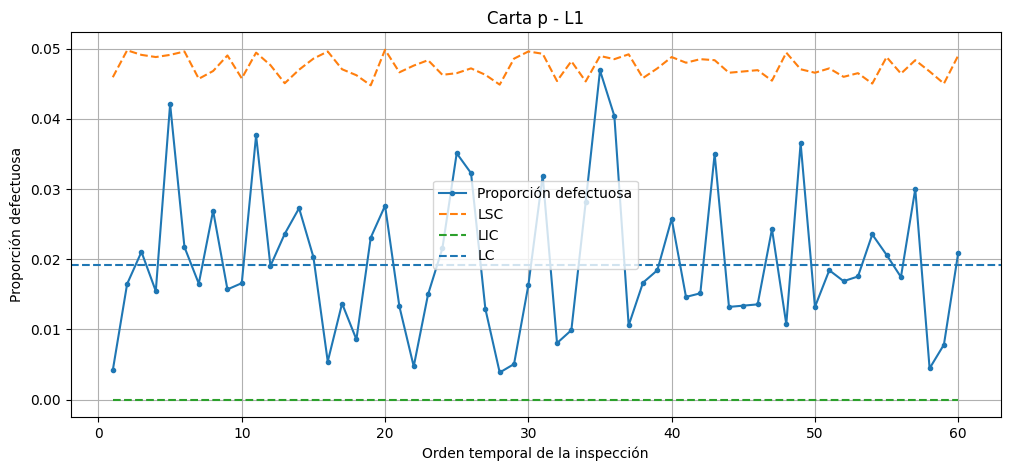


LINEA: L2
p barra: 0.0311
Inspecciones fuera de control:


,fecha,semana_registro,turno,sku,n_inspeccionadas,n_defectuosas,p,LSC,causa_principal
84,2026-08-27,6,A (06-14),FUN-B30,198,18,0.090909,0.068181,Nivel de llenado
105,2026-09-07,8,A (06-14),CIT-L30,198,15,0.075758,0.068181,Etiqueta
107,2026-09-07,8,C (22-06),NEC-D30,234,18,0.076923,0.065213,Etiqueta
109,2026-09-08,8,B (14-22),FUN-B15,246,20,0.081301,0.064372,Etiqueta
110,2026-09-08,8,C (22-06),FUN-B15,237,21,0.088608,0.064997,Etiqueta
111,2026-09-09,8,A (06-14),CIT-L30,236,20,0.084746,0.065069,Sello/tapa
113,2026-09-09,8,C (22-06),CIT-L30,231,21,0.090909,0.065434,Etiqueta
114,2026-09-10,8,A (06-14),NEC-D30,225,23,0.102222,0.065888,Nivel de llenado
115,2026-09-10,8,B (14-22),CIT-L30,258,17,0.065891,0.063590,Etiqueta
116,2026-09-10,8,C (22-06),NEC-D30,241,26,0.107884,0.064715,Sello/tapa


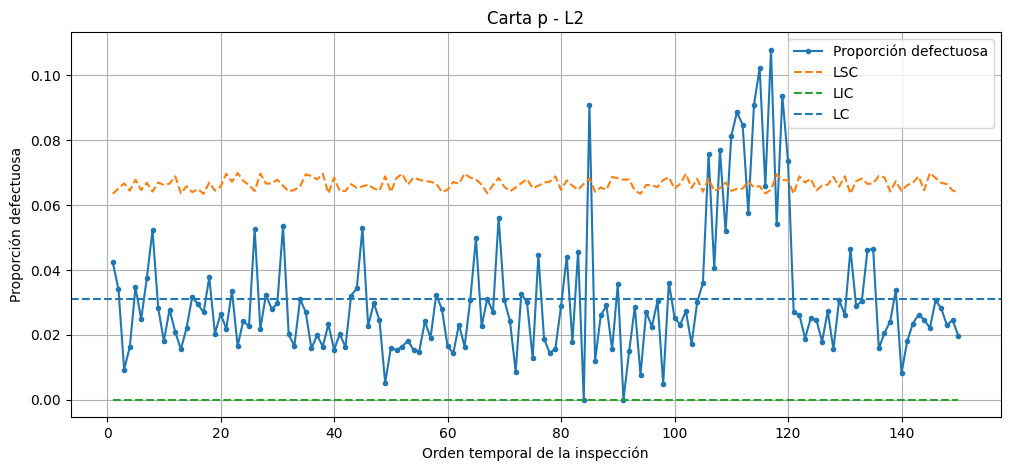


Resumen por línea:


,Linea,Inspecciones,Total_inspeccionadas,Total_defectuosas,p_barra,Porcentaje_defectuoso,Puntos_fuera_control
0,L1,60,12905,248,0.0192,1.92,0
1,L2,150,32974,1027,0.0311,3.11,12



Pareto de causas de defecto:


,causa_principal,n_defectuosas,Porcentaje,Porcentaje_acumulado
0,Etiqueta,440,34.5,34.5
1,Sello/tapa,344,27.0,61.5
2,Nivel de llenado,324,25.4,86.9
3,Envase deformado,92,7.2,94.1
4,Cuerpo extranio,75,5.9,100.0


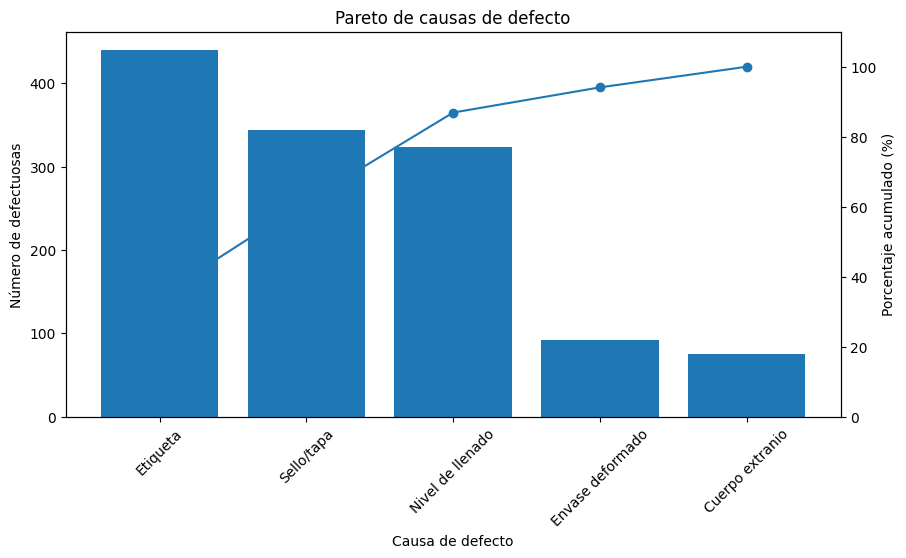

In [55]:
# ============================================================
# CARTA p POR ATRIBUTOS + PARETO DE CAUSAS
# ============================================================

datos_atributos = atributos.copy()

# Proporción defectuosa de cada inspección
datos_atributos["p"] = (
    datos_atributos["n_defectuosas"] /
    datos_atributos["n_inspeccionadas"]
)

resumen_p = []

# ------------------------------------------------------------
# CARTA p POR LÍNEA
# ------------------------------------------------------------

for linea in ["L1", "L2"]:

    datos_linea = datos_atributos[
        datos_atributos["linea"] == linea
    ].copy()

    # Orden temporal
    datos_linea = datos_linea.sort_values(
        ["fecha", "turno"]
    ).reset_index(drop=True)

    datos_linea["orden"] = range(
        1, len(datos_linea) + 1
    )

    # Proporción defectuosa promedio ponderada
    p_barra = (
        datos_linea["n_defectuosas"].sum() /
        datos_linea["n_inspeccionadas"].sum()
    )

    # Límites variables para cada inspección
    error_estandar = np.sqrt(
        p_barra * (1 - p_barra) /
        datos_linea["n_inspeccionadas"]
    )

    datos_linea["LC"] = p_barra

    datos_linea["LSC"] = (
        p_barra + 3 * error_estandar
    )

    datos_linea["LIC"] = (
        p_barra - 3 * error_estandar
    ).clip(lower=0)

    # Identificar puntos fuera de control
    datos_linea["fuera_control"] = (
        (datos_linea["p"] > datos_linea["LSC"]) |
        (datos_linea["p"] < datos_linea["LIC"])
    )

    # Guardar resumen
    resumen_p.append({
        "Linea": linea,
        "Inspecciones": len(datos_linea),
        "Total_inspeccionadas": datos_linea["n_inspeccionadas"].sum(),
        "Total_defectuosas": datos_linea["n_defectuosas"].sum(),
        "p_barra": p_barra,
        "Porcentaje_defectuoso": p_barra * 100,
        "Puntos_fuera_control": datos_linea["fuera_control"].sum()
    })

    # Mostrar puntos fuera de control
    print("\nLINEA:", linea)
    print("p barra:", round(p_barra, 4))

    print("Inspecciones fuera de control:")

    display(
        datos_linea[
            datos_linea["fuera_control"]
        ][
            [
                "fecha",
                "semana_registro",
                "turno",
                "sku",
                "n_inspeccionadas",
                "n_defectuosas",
                "p",
                "LSC",
                "causa_principal"
            ]
        ]
    )

    # Gráfico carta p
    plt.figure(figsize=(12, 5))

    plt.plot(
        datos_linea["orden"],
        datos_linea["p"],
        marker="o",
        markersize=3,
        label="Proporción defectuosa"
    )

    plt.plot(
        datos_linea["orden"],
        datos_linea["LSC"],
        linestyle="--",
        label="LSC"
    )

    plt.plot(
        datos_linea["orden"],
        datos_linea["LIC"],
        linestyle="--",
        label="LIC"
    )

    plt.axhline(
        p_barra,
        linestyle="--",
        label="LC"
    )

    plt.xlabel("Orden temporal de la inspección")
    plt.ylabel("Proporción defectuosa")
    plt.title("Carta p - " + linea)

    plt.legend()
    plt.grid()
    plt.show()


# ------------------------------------------------------------
# RESUMEN DE TASA DEFECTUOSA POR LÍNEA
# ------------------------------------------------------------

resumen_p = pd.DataFrame(resumen_p)

resumen_p["p_barra"] = (
    resumen_p["p_barra"].round(4)
)

resumen_p["Porcentaje_defectuoso"] = (
    resumen_p["Porcentaje_defectuoso"].round(2)
)

print("\nResumen por línea:")
display(resumen_p)


# ------------------------------------------------------------
# PARETO DE CAUSAS DE DEFECTO
# ------------------------------------------------------------

pareto = (
    datos_atributos
    .groupby("causa_principal")["n_defectuosas"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

# Eliminar "Sin defectos" si su cantidad es 0
pareto = pareto[
    pareto["n_defectuosas"] > 0
].copy()

pareto["Porcentaje"] = (
    pareto["n_defectuosas"] /
    pareto["n_defectuosas"].sum() * 100
)

pareto["Porcentaje_acumulado"] = (
    pareto["Porcentaje"].cumsum()
)

pareto["Porcentaje"] = (
    pareto["Porcentaje"].round(1)
)

pareto["Porcentaje_acumulado"] = (
    pareto["Porcentaje_acumulado"].round(1)
)

print("\nPareto de causas de defecto:")
display(pareto)


# Gráfico de Pareto

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.bar(
    pareto["causa_principal"],
    pareto["n_defectuosas"]
)

ax1.set_xlabel("Causa de defecto")
ax1.set_ylabel("Número de defectuosas")

plt.xticks(rotation=45)

ax2 = ax1.twinx()

ax2.plot(
    pareto["causa_principal"],
    pareto["Porcentaje_acumulado"],
    marker="o"
)

ax2.set_ylabel("Porcentaje acumulado (%)")
ax2.set_ylim(0, 110)

plt.title("Pareto de causas de defecto")

plt.show()

In [56]:
# ============================================================
# COMPARACIÓN DEL SOBRELLENADO SEGÚN PERÍODO
# ============================================================

comparacion_sobrellenado = []

for (linea, formato), grupo in llenado.groupby(["linea", "formato_L"]):

    nominal = formato * 1000

    # Fase I: semanas 1-2
    fase1 = grupo[
        grupo["semana_registro"].isin([1, 2])
    ]["volumen_mL"]

    # Período completo: semanas 1-10
    completo = grupo["volumen_mL"]

    # Período reciente
    # L1: semanas 6-10, porque detectamos el desplazamiento desde semana 6
    # L2: semanas 3-10, correspondiente a la Fase II monitoreada
    if linea == "L1":
        reciente = grupo[
            grupo["semana_registro"] >= 6
        ]["volumen_mL"]
        periodo_reciente = "Semanas 6-10"
    else:
        reciente = grupo[
            grupo["semana_registro"] >= 3
        ]["volumen_mL"]
        periodo_reciente = "Semanas 3-10"

    comparacion_sobrellenado.append({
        "Linea": linea,
        "Formato_L": formato,
        "Nominal_mL": nominal,

        "Media_F1_mL": fase1.mean(),
        "Sobrellenado_F1_mL": fase1.mean() - nominal,

        "Media_10_sem_mL": completo.mean(),
        "Sobrellenado_10_sem_mL": completo.mean() - nominal,

        "Periodo_reciente": periodo_reciente,
        "Media_reciente_mL": reciente.mean(),
        "Sobrellenado_reciente_mL": reciente.mean() - nominal
    })

comparacion_sobrellenado = pd.DataFrame(comparacion_sobrellenado)

columnas_redondear = [
    "Media_F1_mL",
    "Sobrellenado_F1_mL",
    "Media_10_sem_mL",
    "Sobrellenado_10_sem_mL",
    "Media_reciente_mL",
    "Sobrellenado_reciente_mL"
]

comparacion_sobrellenado[columnas_redondear] = (
    comparacion_sobrellenado[columnas_redondear].round(3)
)

display(comparacion_sobrellenado)

,Linea,Formato_L,Nominal_mL,Media_F1_mL,Sobrellenado_F1_mL,Media_10_sem_mL,Sobrellenado_10_sem_mL,Periodo_reciente,Media_reciente_mL,Sobrellenado_reciente_mL
0,L1,0.5,500.0,502.644,2.644,504.094,4.094,Semanas 6-10,505.720,5.720
1,L2,1.5,1500.0,1504.457,4.457,1504.601,4.601,Semanas 3-10,1504.633,4.633
2,L2,3.0,3000.0,3008.760,8.760,3008.501,8.501,Semanas 3-10,3008.429,8.429


Estimación del sobrellenado medio. Para cuantificar el sobrellenado se comparó el volumen medio observado con el contenido nominal de cada formato. Además, se contrastaron tres períodos: Fase I, las diez semanas completas y el período reciente. Esta comparación se realizó porque las cartas de control mostraron un desplazamiento del nivel medio de llenado en L1 a partir de la semana 6. Por lo tanto, utilizar únicamente el promedio de Fase I podría no representar adecuadamente las condiciones actuales de operación. Para estimar el consumo adicional de producto asociado a la planificación futura se utilizaron los promedios del período reciente.

Resultados de la comparación
Resultados por formato. En L1–0,5 L se observa el cambio más importante: el sobrellenado medio pasó de 2,644 mL por botella durante Fase I a 5,720 mL por botella en las semanas 6 a 10. Este resultado es consistente con el desplazamiento hacia arriba previamente detectado en la carta \(\bar X\), e indica que el régimen reciente presenta un mayor consumo de producto por unidad. En L2 los cambios fueron considerablemente menores: el formato de 1,5 L pasó de 4,457 a 4,633 mL adicionales por botella, mientras que el formato de 3,0 L pasó de 8,760 a 8,429 mL. Por esta razón, el cambio operacional más relevante corresponde al formato de 0,5 L.

Valores que se utilizarán
Sobrellenado representativo. Considerando el comportamiento reciente del proceso, se adoptaron como parámetros de sobrellenado medio 5,720 mL por botella para el formato de 0,5 L, 4,633 mL para 1,5 L y 8,429 mL para 3,0 L. Estos valores representan el contenido adicional promedio entregado respecto del volumen nominal de cada formato y serán utilizados para cuantificar el consumo adicional de producto y su impacto económico.

Conversión a litros adicionales por caja. Para traducir el sobrellenado a una medida operacional, el exceso medio por botella se multiplicó por el número de botellas contenidas en cada caja. Así, el formato de 0,5 L, con 12 botellas por caja, consume aproximadamente 0,06864 L adicionales por caja; el formato de 1,5 L, con 6 botellas, consume 0,02780 L adicionales; y el formato de 3,0 L, con 4 botellas por caja, consume 0,03372 L adicionales. Aunque el formato de 3,0 L presenta el mayor sobrellenado en mL por botella, el formato de 0,5 L genera el mayor consumo adicional por caja debido a la mayor cantidad de botellas contenidas en ella.

Interpretación operacional
Interpretación. El sobrellenado representa producto que cumple o incluso excede el contenido nominal, pero que no genera ingresos adicionales para la empresa. Por ello, constituye un consumo adicional de materia prima y capacidad de mezcla. El caso más relevante es L1–0,5 L, donde el desplazamiento reciente del proceso elevó significativamente el exceso medio por botella. Corregir el centrado del proceso permitiría reducir este consumo adicional sin necesariamente modificar su variabilidad. El siguiente paso consiste en combinar los litros adicionales por caja con el volumen anual de producción para estimar los litros de producto entregados en exceso y su costo variable anual.

In [57]:
print(maestro.columns.tolist())
display(maestro.head())

['sku', 'familia', 'nombre_familia', 'sabor', 'formato_L', 'botellas_por_caja', 'litros_por_caja', 'linea_envasado', 'tasa_envasado_cajas_h', 'costo_variable_caja_clp', 'precio_lista_caja_clp', 'costo_inventario_caja_semana_clp', 'penalidad_atraso_caja_semana_clp']


,sku,familia,nombre_familia,sabor,formato_L,botellas_por_caja,litros_por_caja,linea_envasado,tasa_envasado_cajas_h,costo_variable_caja_clp,precio_lista_caja_clp,costo_inventario_caja_semana_clp,penalidad_atraso_caja_semana_clp
0,NEC-D05,NEC,Nectares con pulpa,Durazno,0.5,12,6.0,L1,180,3840,6620,95,1400
1,NEC-D15,NEC,Nectares con pulpa,Durazno,1.5,6,9.0,L2,210,5760,9930,95,1400
2,NEC-D30,NEC,Nectares con pulpa,Durazno,3.0,4,12.0,L2,130,7680,13240,95,1400
3,CIT-L05,CIT,Citricos gasificados,Limon,0.5,12,6.0,L1,180,2820,5320,95,1400
4,CIT-L15,CIT,Citricos gasificados,Limon,1.5,6,9.0,L2,210,4230,7980,95,1400


Revisar los valores monetarios de los productos

In [58]:
# ============================================================
# CUANTIFICACIÓN ECONÓMICA DEL SOBRELLENADO
# ============================================================

# Sobrellenado representativo del período reciente
sobrellenado_formato = pd.DataFrame({
    "formato_L": [0.5, 1.5, 3.0],
    "sobrellenado_mL_botella": [5.720, 4.633, 8.429]
})

# ------------------------------------------------------------
# 1. Ventas de las últimas 52 semanas
# ------------------------------------------------------------

semana_max = demanda["semana"].max()

ventas_52 = demanda[
    demanda["semana"] > semana_max - 52
].copy()

ventas_anuales = (
    ventas_52
    .groupby("sku", as_index=False)["ventas_cajas"]
    .sum()
    .rename(columns={"ventas_cajas": "cajas_anuales"})
)

# ------------------------------------------------------------
# 2. Agregar información del maestro
# ------------------------------------------------------------

sobrellenado_anual = ventas_anuales.merge(
    maestro[
        [
            "sku",
            "familia",
            "formato_L",
            "botellas_por_caja",
            "litros_por_caja",
            "linea_envasado",
            "costo_variable_caja_clp"
        ]
    ],
    on="sku",
    how="left"
)

sobrellenado_anual = sobrellenado_anual.merge(
    sobrellenado_formato,
    on="formato_L",
    how="left"
)

# ------------------------------------------------------------
# 3. Litros adicionales por caja
# ------------------------------------------------------------

sobrellenado_anual["sobrellenado_L_caja"] = (
    sobrellenado_anual["sobrellenado_mL_botella"]
    * sobrellenado_anual["botellas_por_caja"]
    / 1000
)

# ------------------------------------------------------------
# 4. Litros adicionales al año
# ------------------------------------------------------------

sobrellenado_anual["litros_extra_anuales"] = (
    sobrellenado_anual["cajas_anuales"]
    * sobrellenado_anual["sobrellenado_L_caja"]
)

# ------------------------------------------------------------
# 5. Costo variable aproximado por litro
# ------------------------------------------------------------

sobrellenado_anual["costo_variable_L_clp"] = (
    sobrellenado_anual["costo_variable_caja_clp"]
    / sobrellenado_anual["litros_por_caja"]
)

# ------------------------------------------------------------
# 6. Costo anual del sobrellenado
# ------------------------------------------------------------

sobrellenado_anual["costo_sobrellenado_anual_clp"] = (
    sobrellenado_anual["litros_extra_anuales"]
    * sobrellenado_anual["costo_variable_L_clp"]
)

# Redondear
columnas_redondear = [
    "sobrellenado_L_caja",
    "litros_extra_anuales",
    "costo_variable_L_clp",
    "costo_sobrellenado_anual_clp"
]

sobrellenado_anual[columnas_redondear] = (
    sobrellenado_anual[columnas_redondear].round(2)
)

print("DETALLE POR SKU")
display(
    sobrellenado_anual[
        [
            "sku",
            "familia",
            "formato_L",
            "cajas_anuales",
            "sobrellenado_mL_botella",
            "sobrellenado_L_caja",
            "litros_extra_anuales",
            "costo_variable_L_clp",
            "costo_sobrellenado_anual_clp"
        ]
    ]
)

# ------------------------------------------------------------
# 7. Resumen por formato
# ------------------------------------------------------------

resumen_sobrellenado = (
    sobrellenado_anual
    .groupby("formato_L", as_index=False)
    .agg(
        cajas_anuales=("cajas_anuales", "sum"),
        litros_extra_anuales=("litros_extra_anuales", "sum"),
        costo_sobrellenado_anual_clp=(
            "costo_sobrellenado_anual_clp", "sum"
        )
    )
)

resumen_sobrellenado[
    ["litros_extra_anuales", "costo_sobrellenado_anual_clp"]
] = resumen_sobrellenado[
    ["litros_extra_anuales", "costo_sobrellenado_anual_clp"]
].round(0)

print("\nRESUMEN POR FORMATO")
display(resumen_sobrellenado)

# ------------------------------------------------------------
# 8. Total planta
# ------------------------------------------------------------

total_litros = sobrellenado_anual["litros_extra_anuales"].sum()
total_costo = sobrellenado_anual["costo_sobrellenado_anual_clp"].sum()

print("\nTOTAL PLANTA")
print("Litros adicionales al año:", round(total_litros, 0))
print("Costo variable anual estimado: $", round(total_costo, 0))

DETALLE POR SKU


,sku,familia,formato_L,cajas_anuales,sobrellenado_mL_botella,sobrellenado_L_caja,litros_extra_anuales,costo_variable_L_clp,costo_sobrellenado_anual_clp
0,CIT-L05,CIT,0.5,133114.0,5.720,0.07,9136.94,470.0,4294364.13
1,CIT-L15,CIT,1.5,114955.0,4.633,0.03,3195.52,470.0,1501893.97
2,CIT-L30,CIT,3.0,22513.0,8.429,0.03,759.05,470.0,356752.70
3,FUN-B05,FUN,0.5,128996.0,5.720,0.07,8854.29,810.0,7171971.21
4,FUN-B15,FUN,1.5,90729.0,4.633,0.03,2522.08,810.0,2042888.64
5,FUN-B30,FUN,3.0,7580.0,8.429,0.03,255.57,810.0,207009.50
6,NEC-D05,NEC,0.5,79233.0,5.720,0.07,5438.55,640.0,3480674.00
7,NEC-D15,NEC,1.5,139996.0,4.633,0.03,3891.61,640.0,2490629.64
8,NEC-D30,NEC,3.0,32359.0,8.429,0.03,1091.02,640.0,698250.27



RESUMEN POR FORMATO


,formato_L,cajas_anuales,litros_extra_anuales,costo_sobrellenado_anual_clp
0,0.5,341343.0,23430.0,14947009.0
1,1.5,345680.0,9609.0,6035412.0
2,3.0,62452.0,2106.0,1262012.0



TOTAL PLANTA
Litros adicionales al año: 35145.0
Costo variable anual estimado: $ 22244434.0


Cuantificación económica del sobrellenado. Utilizando como referencia el comportamiento reciente del proceso y las ventas de las últimas 52 semanas como aproximación del volumen anual, se estimó que el sobrellenado genera aproximadamente 35.145 litros adicionales de producto al año. Valorizados mediante el costo variable equivalente por litro de cada SKU, estos representan un costo aproximado de $22,24 millones anuales. El formato de 0,5 L concentra el mayor impacto, con 23.430 litros adicionales y un costo cercano a 14,95 millones anuales, equivalentes a aproximadamente dos tercios del volumen total sobrellenado. Este resultado es consistente con el desplazamiento de la media detectado previamente en L1, especialmente desde la semana 6.


Supuesto de cálculo. Debido a que la base disponible registra ventas y no producción efectiva, se utilizaron las ventas de las últimas 52 semanas como aproximación del volumen anual producido. Asimismo, dado que no se dispone de un costo específico del jarabe por litro, se estimó un costo variable equivalente por litro a partir del costo variable y los litros nominales por caja. Por ello, el resultado debe interpretarse como una estimación económica del impacto del sobrellenado. Una vez reconstruida la demanda en la Parte B, el cálculo puede actualizarse si se considera necesario.


Las líneas presentan patologías distintas. L2 concentra el mayor problema de calidad por atributos, con una fracción defectuosa de 3,11 % y episodios de deterioro estadístico. En cambio, L1 concentra el mayor impacto económico asociado al sobrellenado, con aproximadamente 23.430 litros adicionales y $14,95 millones de costo variable al año.




El análisis demuestra que estabilidad estadística y capacidad de proceso son conceptos distintos: un proceso puede presentar un comportamiento predecible y, aun así, no ser capaz de cumplir consistentemente las especificaciones. En Bebidas del Maipo, ninguno de los tres procesos alcanza un \(Cpk\) global de 1,33, aunque las causas del problema difieren. L1–0,5 L presenta principalmente un problema de centrado, evidenciado por la diferencia entre \(Cp=1,306\) y \(Cpk=0,874\), además del desplazamiento ascendente observado desde la semana 6. En L2–1,5 L, \(Cp=0,998\) muestra que también existe un problema importante de variabilidad, mientras que L2–3,0 L combina un centrado deficiente con una capacidad potencial ajustada. Por lo tanto, no corresponde aplicar la misma acción a todos los procesos: los problemas de media requieren recalibración o ajuste del setpoint, mientras que los problemas de dispersión requieren intervenir las fuentes de variabilidad del proceso.
En el análisis por atributos, L1 presentó una tasa defectuosa de 1,92 %, mientras que L2 alcanzó 3,11 % y registró 12 inspecciones sobre el límite superior de control, principalmente concentradas en la semana 8. El Pareto mostró que Etiqueta, Sello/tapa y Nivel de llenado concentran el 86,9 % de las unidades defectuosas. Por otro lado, el impacto económico del sobrellenado se concentra en L1–0,5 L: se estimaron aproximadamente 35.145 litros adicionales al año para toda la planta, equivalentes a 22,24 millones anuales de costo variable, de los cuales 23.430 litros y aproximadamente $14,95 millones corresponden al formato de 0,5 L. En consecuencia, L2 presenta el mayor problema asociado a defectos, mientras que L1 presenta el mayor impacto económico por sobrellenado.


# PARTE B — Pronóstico de demanda

# Entrega 1 - Parte B: pronóstico de demanda (puntos 1 a 4)



## 1. Diagnóstico documentado de las nueve series

Se examinarán tendencia, estacionalidad, valores atípicos, faltantes,
quiebres estructurales, intermitencia y promociones. Para cada anomalía
detectada se documentará el método de detección, su interpretación
y el tratamiento aplicado.

In [59]:
carpeta_proyecto = carpeta_proyecto
print('Repositorio del proyecto:', carpeta_proyecto)

Repositorio del proyecto: /content/GO-Grupo-2


In [60]:
import numpy as np
import pandas as pd
from IPython.display import display

ruta_datos = carpeta_proyecto / "datos"

demanda_original = pd.read_csv(ruta_datos / "demanda_semanal.csv")
maestro_original = pd.read_csv(ruta_datos / "maestro_sku.csv")

print("Primeras cinco filas de las ventas semanales:")
display(demanda_original.head())

print("Información de los productos:")
display(maestro_original)

print("Filas de ventas:", len(demanda_original))
print("Productos distintos:", demanda_original["sku"].nunique())
print("Semanas distintas:", demanda_original["semana"].nunique())

Primeras cinco filas de las ventas semanales:


,semana,fecha_lunes,anio_iso,semana_iso,sku,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
0,1,2023-10-02,2023,40,NEC-D05,1209.0,0.0,0,6620,6620
1,2,2023-10-09,2023,41,NEC-D05,1095.0,0.0,0,6620,6620
2,3,2023-10-16,2023,42,NEC-D05,1345.0,0.0,0,6620,6620
3,4,2023-10-23,2023,43,NEC-D05,1888.0,0.0,1,6620,4819
4,5,2023-10-30,2023,44,NEC-D05,991.0,0.0,0,6620,6620


Información de los productos:


,sku,familia,nombre_familia,sabor,formato_L,botellas_por_caja,litros_por_caja,linea_envasado,tasa_envasado_cajas_h,costo_variable_caja_clp,precio_lista_caja_clp,costo_inventario_caja_semana_clp,penalidad_atraso_caja_semana_clp
0,NEC-D05,NEC,Nectares con pulpa,Durazno,0.5,12,6.0,L1,180,3840,6620,95,1400
1,NEC-D15,NEC,Nectares con pulpa,Durazno,1.5,6,9.0,L2,210,5760,9930,95,1400
2,NEC-D30,NEC,Nectares con pulpa,Durazno,3.0,4,12.0,L2,130,7680,13240,95,1400
3,CIT-L05,CIT,Citricos gasificados,Limon,0.5,12,6.0,L1,180,2820,5320,95,1400
4,CIT-L15,CIT,Citricos gasificados,Limon,1.5,6,9.0,L2,210,4230,7980,95,1400
5,CIT-L30,CIT,Citricos gasificados,Limon,3.0,4,12.0,L2,130,5640,10640,95,1400
6,FUN-B05,FUN,Funcionales,Berries,0.5,12,6.0,L1,180,4860,9920,95,1400
7,FUN-B15,FUN,Funcionales,Berries,1.5,6,9.0,L2,210,7290,14880,95,1400
8,FUN-B30,FUN,Funcionales,Berries,3.0,4,12.0,L2,130,9720,19840,95,1400


Filas de ventas: 1404
Productos distintos: 9
Semanas distintas: 156


### 1.1. Revisión inicial de los datos

Se revisan fechas, tipos de datos, valores faltantes, registros duplicados,
continuidad semanal y consistencia de las variables. Los datos originales
se conservan sin modificaciones.

In [61]:
# Trabajamos con copias para conservar los datos originales.
demanda = demanda_original.copy()
maestro = maestro_original.copy()

# Convertimos las fechas. Las fechas que no se puedan interpretar
# quedarán marcadas como NaT.
demanda["fecha_lunes"] = pd.to_datetime(
    demanda["fecha_lunes"], errors="coerce"
)

print("1. TIPOS DE DATOS")
display(demanda.dtypes.rename("tipo").to_frame())

print("2. VALORES FALTANTES POR COLUMNA")
display(demanda.isna().sum().rename("faltantes").to_frame())

print("3. REGISTROS DUPLICADOS")
print("Filas completamente repetidas:",
      demanda_original.duplicated().sum())

duplicados = demanda.duplicated(
    subset=["sku", "semana"], keep=False
)
print("Filas con combinación SKU-semana repetida:",
      duplicados.sum())

if duplicados.any():
    display(demanda.loc[duplicados].sort_values(["sku", "semana"]))

print("4. COBERTURA POR PRODUCTO")
resumen = demanda.groupby("sku").agg(
    registros=("semana", "size"),
    semanas_distintas=("semana", "nunique"),
    primera_fecha=("fecha_lunes", "min"),
    ultima_fecha=("fecha_lunes", "max")
)
display(resumen)

print("5. CONTINUIDAD SEMANAL")
calendario = pd.date_range(
    demanda["fecha_lunes"].min(),
    demanda["fecha_lunes"].max(),
    freq="7D"
)

revision_calendario = []

for sku, grupo in demanda.groupby("sku"):
    fechas = pd.DatetimeIndex(grupo["fecha_lunes"].dropna().unique())
    faltantes = calendario.difference(fechas)

    revision_calendario.append({
        "sku": sku,
        "fechas_invalidas_o_faltantes": grupo["fecha_lunes"].isna().sum(),
        "fechas_que_no_son_lunes":
            (grupo["fecha_lunes"].dropna().dt.dayofweek != 0).sum(),
        "semanas_ausentes": len(faltantes)
    })

display(pd.DataFrame(revision_calendario).set_index("sku"))

print("6. CONSISTENCIA DE LAS VARIABLES")

controles = pd.Series({
    "Ventas negativas":
        (demanda["ventas_cajas"] < 0).sum(),
    "Días sin stock fuera del rango 0 a 7":
        (~demanda["dias_sin_stock"].between(0, 7)
         & demanda["dias_sin_stock"].notna()).sum(),
    "Promoción distinta de 0 o 1":
        (~demanda["promocion"].isin([0, 1])
         & demanda["promocion"].notna()).sum(),
    "Precio de lista menor o igual a cero":
        (demanda["precio_lista_clp"] <= 0).sum(),
    "Precio efectivo menor o igual a cero":
        (demanda["precio_efectivo_clp"] <= 0).sum(),
    "Precio efectivo mayor que el de lista":
        (demanda["precio_efectivo_clp"]
         > demanda["precio_lista_clp"]).sum(),
    "SKU del maestro repetidos":
        maestro["sku"].duplicated().sum()
}, name="registros_a_revisar")

display(controles.to_frame())

sku_sin_maestro = set(demanda["sku"].dropna()) - set(maestro["sku"].dropna())
print("SKU de ventas que no aparecen en el maestro:", sku_sin_maestro)

1. TIPOS DE DATOS


,tipo
semana,int64
fecha_lunes,datetime64[ns]
anio_iso,int64
semana_iso,int64
sku,object
ventas_cajas,float64
dias_sin_stock,float64
promocion,int64
precio_lista_clp,int64
precio_efectivo_clp,int64


2. VALORES FALTANTES POR COLUMNA


,faltantes
semana,0
fecha_lunes,0
anio_iso,0
semana_iso,0
sku,0
ventas_cajas,3
dias_sin_stock,3
promocion,0
precio_lista_clp,0
precio_efectivo_clp,0


3. REGISTROS DUPLICADOS
Filas completamente repetidas: 0
Filas con combinación SKU-semana repetida: 0
4. COBERTURA POR PRODUCTO


...

5. CONTINUIDAD SEMANAL


,fechas_invalidas_o_faltantes,fechas_que_no_son_lunes,semanas_ausentes
sku,,,
CIT-L05,0,0,0
CIT-L15,0,0,0
CIT-L30,0,0,0
FUN-B05,0,0,0
FUN-B15,0,0,0
FUN-B30,0,0,0
NEC-D05,0,0,0
NEC-D15,0,0,0
NEC-D30,0,0,0


6. CONSISTENCIA DE LAS VARIABLES


,registros_a_revisar
Ventas negativas,0
Días sin stock fuera del rango 0 a 7,0
Promoción distinta de 0 o 1,0
Precio de lista menor o igual a cero,0
Precio efectivo menor o igual a cero,0
Precio efectivo mayor que el de lista,0
SKU del maestro repetidos,0


SKU de ventas que no aparecen en el maestro: set()


In [62]:
columnas_revision = [
    "sku", "semana", "fecha_lunes", "ventas_cajas",
    "dias_sin_stock", "promocion",
    "precio_lista_clp", "precio_efectivo_clp"
]

mascara_faltantes = demanda[
    ["ventas_cajas", "dias_sin_stock"]
].isna().any(axis=1)

filas_faltantes = demanda.loc[mascara_faltantes].sort_values(
    ["sku", "semana"]
)

print("REGISTROS CON ALGÚN VALOR FALTANTE")
display(filas_faltantes[columnas_revision])

print("Filas afectadas:", len(filas_faltantes))
print(
    "Filas donde faltan ambas variables:",
    demanda[["ventas_cajas", "dias_sin_stock"]]
    .isna().all(axis=1).sum()
)

for _, fila in filas_faltantes.iterrows():
    contexto = demanda.loc[
        (demanda["sku"] == fila["sku"])
        & demanda["semana"].between(
            fila["semana"] - 2,
            fila["semana"] + 2
        ),
        columnas_revision
    ].sort_values("semana")

    print(
        f"\nProducto {fila['sku']} — "
        f"semana con faltante: {fila['semana']}"
    )
    display(contexto)

REGISTROS CON ALGÚN VALOR FALTANTE


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
724,CIT-L15,101,2025-09-01,NaN,NaN,0,7980,7980
725,CIT-L15,102,2025-09-08,NaN,NaN,1,7980,6433
726,CIT-L15,103,2025-09-15,NaN,NaN,0,7980,7980


Filas afectadas: 3
Filas donde faltan ambas variables: 3

Producto CIT-L15 — semana con faltante: 101


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
722,CIT-L15,99,2025-08-18,1276.0,0.0,0,7980,7980
723,CIT-L15,100,2025-08-25,1431.0,0.0,0,7980,7980
724,CIT-L15,101,2025-09-01,NaN,NaN,0,7980,7980
725,CIT-L15,102,2025-09-08,NaN,NaN,1,7980,6433
726,CIT-L15,103,2025-09-15,NaN,NaN,0,7980,7980



Producto CIT-L15 — semana con faltante: 102


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
723,CIT-L15,100,2025-08-25,1431.0,0.0,0,7980,7980
724,CIT-L15,101,2025-09-01,NaN,NaN,0,7980,7980
725,CIT-L15,102,2025-09-08,NaN,NaN,1,7980,6433
726,CIT-L15,103,2025-09-15,NaN,NaN,0,7980,7980
727,CIT-L15,104,2025-09-22,1985.0,0.0,0,7980,7980



Producto CIT-L15 — semana con faltante: 103


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
724,CIT-L15,101,2025-09-01,NaN,NaN,0,7980,7980
725,CIT-L15,102,2025-09-08,NaN,NaN,1,7980,6433
726,CIT-L15,103,2025-09-15,NaN,NaN,0,7980,7980
727,CIT-L15,104,2025-09-22,1985.0,0.0,0,7980,7980
728,CIT-L15,105,2025-09-29,1837.0,0.0,0,7980,7980


### 1.2. Hallazgo: valores faltantes en CIT-L15

Detección: mediante isna() se identificaron tres registros con ausencia
simultánea de ventas_cajas y dias_sin_stock, correspondientes a las
semanas 101, 102 y 103 (1, 8 y 15 de septiembre de 2025).

Interpretación: las fechas, promociones y precios están registrados,
pero faltan las ventas y la disponibilidad de stock. Esto podría deberse
a una falla de registro o extracción; la causa no puede confirmarse
con la información disponible. La semana 102 presenta promoción.

Tratamiento inicial: se mantienen las filas y los valores faltantes,
sin reemplazarlos por cero. Se agregan indicadores para conservar la
trazabilidad. La imputación de ventas se definirá después de examinar
la estacionalidad, las promociones y las restricciones de stock.

In [63]:
demanda["ventas_faltantes_original"] = demanda["ventas_cajas"].isna()
demanda["stock_faltante_original"] = demanda["dias_sin_stock"].isna()

display(
    demanda.loc[
        demanda["ventas_faltantes_original"]
        | demanda["stock_faltante_original"],
        [
            "sku", "semana", "fecha_lunes",
            "ventas_cajas", "dias_sin_stock", "promocion",
            "ventas_faltantes_original", "stock_faltante_original"
        ]
    ]
)

,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,ventas_faltantes_original,stock_faltante_original
724,CIT-L15,101,2025-09-01,NaN,NaN,0,True,True
725,CIT-L15,102,2025-09-08,NaN,NaN,1,True,True
726,CIT-L15,103,2025-09-15,NaN,NaN,0,True,True


### 1.3. Inspección visual de las nueve series

Se grafican las ventas semanales de cada SKU y su media móvil de
13 semanas como apoyo visual para identificar cambios de nivel.
También se señalan promociones, semanas con días sin stock y
registros con ventas faltantes.

Esta revisión es exploratoria: los gráficos orientan el diagnóstico,
pero no confirman por sí solos anomalías ni sus causas.

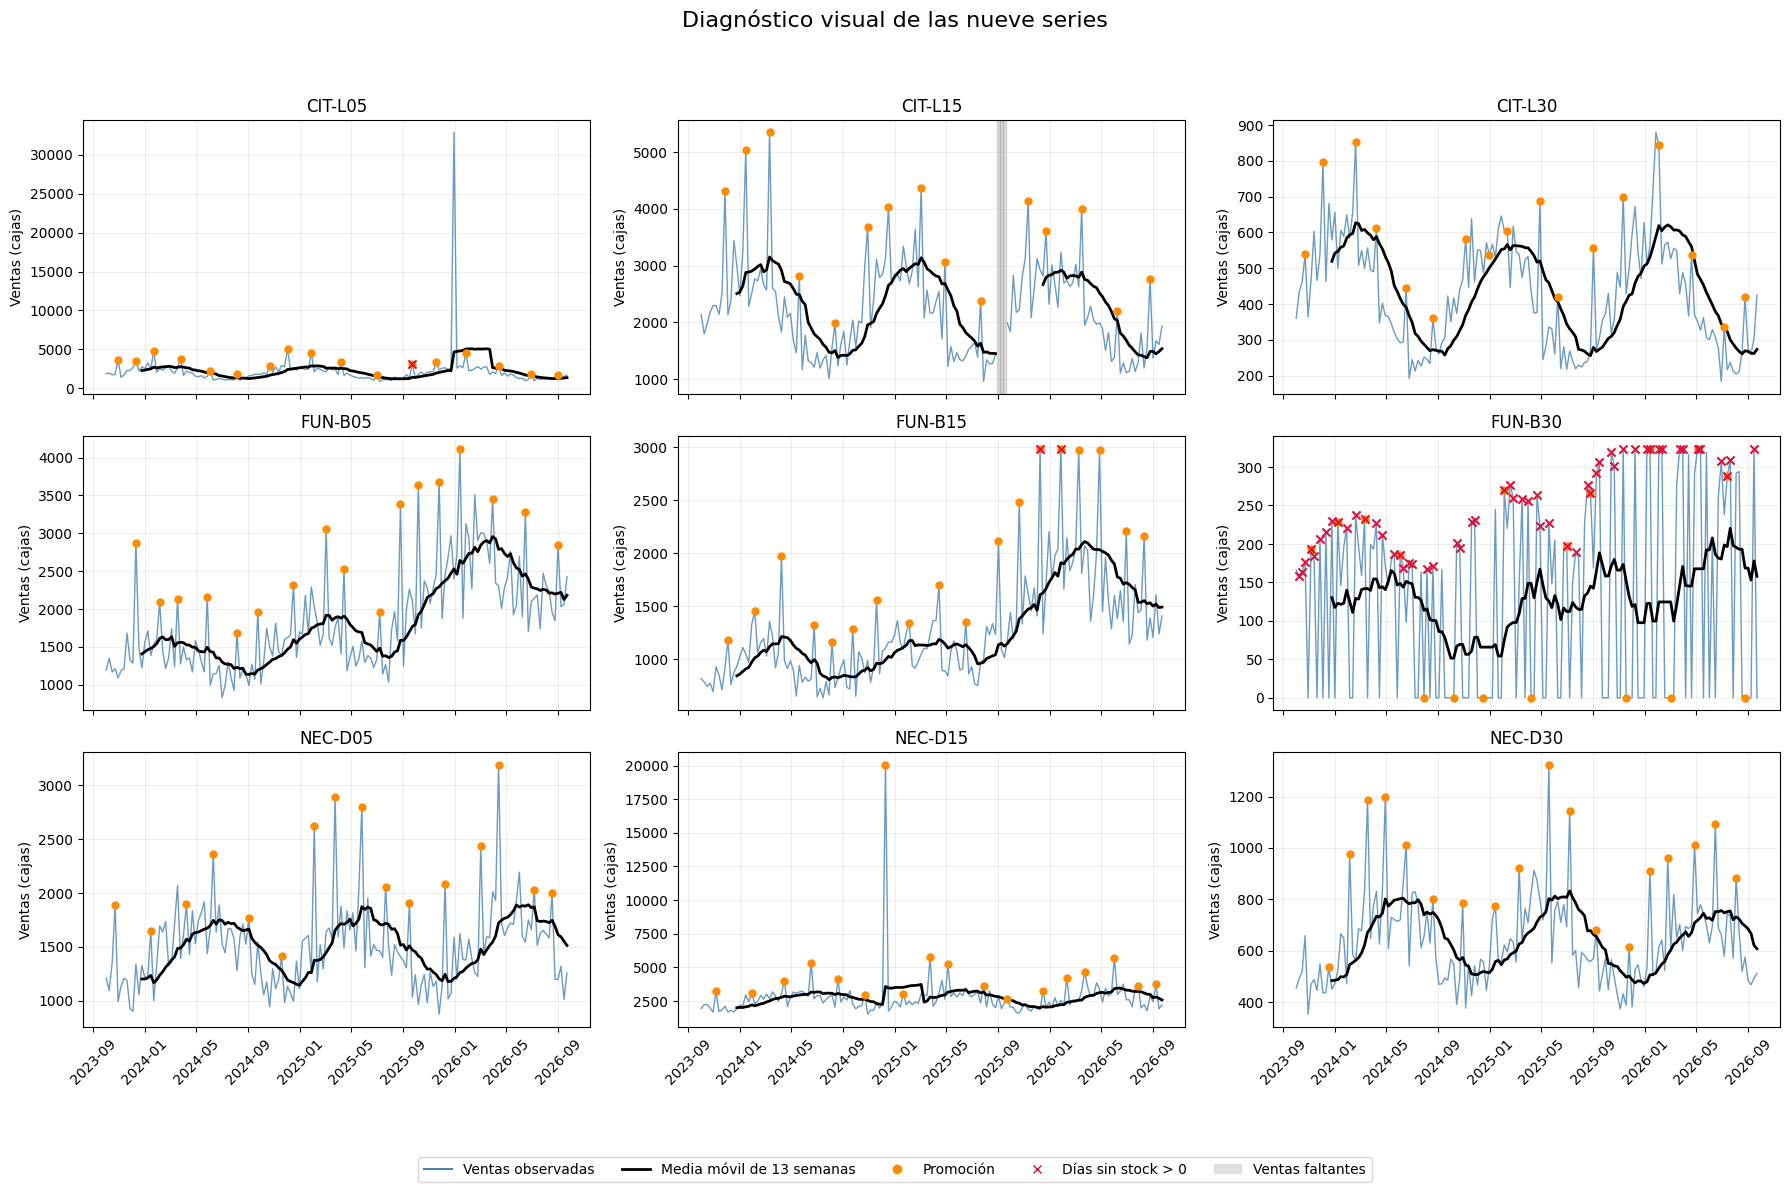

In [64]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

productos = sorted(demanda["sku"].unique())

fig, ejes = plt.subplots(
    3, 3, figsize=(18, 12), sharex=True
)

for eje, sku in zip(ejes.flat, productos):
    serie = demanda.loc[demanda["sku"] == sku].sort_values(
        "fecha_lunes"
    ).copy()

    # Ventana que usa la semana actual y las 12 anteriores.
    # Exigimos las 13 ventas para no suavizar a través de faltantes.
    media_movil = serie["ventas_cajas"].rolling(
        window=13, min_periods=13
    ).mean()

    eje.plot(
        serie["fecha_lunes"], serie["ventas_cajas"],
        color="steelblue", linewidth=1, alpha=0.8
    )

    eje.plot(
        serie["fecha_lunes"], media_movil,
        color="black", linewidth=2
    )

    promociones = serie["promocion"].eq(1)
    eje.scatter(
        serie.loc[promociones, "fecha_lunes"],
        serie.loc[promociones, "ventas_cajas"],
        color="darkorange", s=25, zorder=3
    )

    sin_stock = serie["dias_sin_stock"].gt(0)
    eje.scatter(
        serie.loc[sin_stock, "fecha_lunes"],
        serie.loc[sin_stock, "ventas_cajas"],
        color="crimson", marker="x", s=35, zorder=4
    )

    fechas_faltantes = serie.loc[
        serie["ventas_faltantes_original"], "fecha_lunes"
    ]

    for fecha in fechas_faltantes:
        eje.axvspan(
            fecha - pd.Timedelta(days=3),
            fecha + pd.Timedelta(days=4),
            color="gray", alpha=0.25
        )

    eje.set_title(sku)
    eje.set_ylabel("Ventas (cajas)")
    eje.grid(alpha=0.2)
    eje.tick_params(axis="x", rotation=45)

leyenda = [
    Line2D([0], [0], color="steelblue", label="Ventas observadas"),
    Line2D([0], [0], color="black", linewidth=2,
           label="Media móvil de 13 semanas"),
    Line2D([0], [0], marker="o", color="darkorange",
           linestyle="None", label="Promoción"),
    Line2D([0], [0], marker="x", color="crimson",
           linestyle="None", label="Días sin stock > 0"),
    Patch(facecolor="gray", alpha=0.25, label="Ventas faltantes")
]

fig.suptitle("Diagnóstico visual de las nueve series", fontsize=16)
fig.legend(handles=leyenda, loc="lower center", ncol=5)
fig.tight_layout(rect=[0, 0.07, 1, 0.95])

plt.show()

In [65]:
carpeta_salidas = Path("salidas")
carpeta_salidas.mkdir(exist_ok=True)
ruta_figura = carpeta_salidas / "diagnostico_nueve_series.png"
fig.savefig(ruta_figura, dpi=200, bbox_inches="tight")
print(f"Figura guardada en: {ruta_figura.resolve()}")


Figura guardada en: /content/salidas/diagnostico_nueve_series.png


### 1.4. Revisión de picos candidatos a valores atípicos

La inspección visual mostró picos aislados de gran magnitud en CIT-L05
y NEC-D15. Se localiza la venta máxima de cada serie y se compara con
las semanas cercanas, considerando promociones, precios y días sin stock.

La magnitud del pico constituye una señal para investigar; no demuestra
por sí sola un error de registro.

In [66]:
columnas = [
    "sku", "semana", "fecha_lunes", "ventas_cajas",
    "dias_sin_stock", "promocion",
    "precio_lista_clp", "precio_efectivo_clp"
]

resumen_picos = []

for sku in ["CIT-L05", "NEC-D15"]:
    serie = demanda.loc[demanda["sku"] == sku].sort_values(
        "semana"
    )

    pico = serie.loc[serie["ventas_cajas"].idxmax()]

    contexto = serie.loc[
        serie["semana"].between(
            pico["semana"] - 4,
            pico["semana"] + 4
        )
    ]

    # Referencia exploratoria: mediana de las semanas cercanas,
    # excluyendo el propio pico y los valores faltantes.
    vecinos = contexto.loc[
        contexto["semana"] != pico["semana"], "ventas_cajas"
    ].dropna()

    mediana_local = vecinos.median()

    razon = (
        pico["ventas_cajas"] / mediana_local
        if pd.notna(mediana_local) and mediana_local > 0
        else float("nan")
    )

    resumen_picos.append({
        "sku": sku,
        "semana_pico": pico["semana"],
        "fecha": pico["fecha_lunes"],
        "ventas_pico": pico["ventas_cajas"],
        "mediana_semanas_cercanas": mediana_local,
        "veces_la_mediana": razon,
        "promocion": pico["promocion"],
        "dias_sin_stock": pico["dias_sin_stock"]
    })

    print(f"\nCONTEXTO DEL PICO DE {sku}")
    display(contexto[columnas])

print("\nRESUMEN DE LOS PICOS")
display(pd.DataFrame(resumen_picos).round(2))


CONTEXTO DEL PICO DE CIT-L05


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
581,CIT-L05,114,2025-12-01,2579.0,0.0,0,5320,5320
582,CIT-L05,115,2025-12-08,2609.0,0.0,0,5320,5320
583,CIT-L05,116,2025-12-15,2435.0,0.0,0,5320,5320
584,CIT-L05,117,2025-12-22,2555.0,0.0,0,5320,5320
585,CIT-L05,118,2025-12-29,32916.0,0.0,0,5320,5320
586,CIT-L05,119,2026-01-05,2584.0,0.0,0,5320,5320
587,CIT-L05,120,2026-01-12,2866.0,0.0,0,5320,5320
588,CIT-L05,121,2026-01-19,2661.0,0.0,0,5320,5320
589,CIT-L05,122,2026-01-26,4470.0,0.0,1,5320,4392



CONTEXTO DEL PICO DE NEC-D15


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
214,NEC-D15,59,2024-11-11,1807.0,0.0,0,9930,9930
215,NEC-D15,60,2024-11-18,2370.0,0.0,0,9930,9930
216,NEC-D15,61,2024-11-25,1966.0,0.0,0,9930,9930
217,NEC-D15,62,2024-12-02,2368.0,0.0,0,9930,9930
218,NEC-D15,63,2024-12-09,20052.0,0.0,1,9930,8170
219,NEC-D15,64,2024-12-16,1752.0,0.0,0,9930,9930
220,NEC-D15,65,2024-12-23,2046.0,0.0,0,9930,9930
221,NEC-D15,66,2024-12-30,2485.0,0.0,0,9930,9930
222,NEC-D15,67,2025-01-06,2361.0,0.0,0,9930,9930



RESUMEN DE LOS PICOS


,sku,semana_pico,fecha,ventas_pico,mediana_semanas_cercanas,veces_la_mediana,promocion,dias_sin_stock
0,CIT-L05,118,2025-12-29,32916.0,2596.5,12.68,0,0.0
1,NEC-D15,63,2024-12-09,20052.0,2203.5,9.10,1,0.0


In [67]:
for sku in ["CIT-L05", "NEC-D15"]:
    serie = demanda.loc[demanda["sku"] == sku].copy()

    print(f"\n{sku}: LAS 10 MAYORES VENTAS")
    display(
        serie.nlargest(10, "ventas_cajas")[columnas]
    )

    print(f"{sku}: RESUMEN SEGÚN PROMOCIÓN")

    resumen_promociones = serie.groupby("promocion").agg(
        semanas_con_ventas=("ventas_cajas", "count"),
        mediana_ventas=("ventas_cajas", "median"),
        maxima_venta=("ventas_cajas", "max")
    )

    display(resumen_promociones.round(2))

    print(f"{sku}: MISMA ÉPOCA EN OTROS AÑOS")

    semana_pico = serie.loc[
        serie["ventas_cajas"].idxmax(), "semana"
    ]

    comparables = serie.loc[
        serie["semana"].between(semana_pico - 52 - 2,
                                semana_pico - 52 + 2)
        | serie["semana"].between(semana_pico + 52 - 2,
                                  semana_pico + 52 + 2)
    ]

    display(comparables[columnas].sort_values("semana"))


CIT-L05: LAS 10 MAYORES VENTAS


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
585,CIT-L05,118,2025-12-29,32916.0,0.0,0,5320,5320
529,CIT-L05,62,2024-12-02,5097.0,0.0,1,5320,4006
484,CIT-L05,17,2024-01-22,4738.0,0.0,1,5320,4263
537,CIT-L05,70,2025-01-27,4533.0,0.0,1,5320,4254
589,CIT-L05,122,2026-01-26,4470.0,0.0,1,5320,4392
493,CIT-L05,26,2024-03-25,3809.0,0.0,1,5320,4010
472,CIT-L05,5,2023-10-30,3572.0,0.0,1,5320,3877
478,CIT-L05,11,2023-12-11,3443.0,0.0,1,5320,4115
547,CIT-L05,80,2025-04-07,3403.0,0.0,1,5320,4130
579,CIT-L05,112,2025-11-17,3321.0,0.0,1,5320,4046


CIT-L05: RESUMEN SEGÚN PROMOCIÓN


,semanas_con_ventas,mediana_ventas,maxima_venta
promocion,,,
0,139,1761.0,32916.0
1,17,3321.0,5097.0


CIT-L05: MISMA ÉPOCA EN OTROS AÑOS


...

,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
218,NEC-D15,63,2024-12-09,20052.0,0.0,1,9930,8170
233,NEC-D15,78,2025-03-24,5750.0,0.0,1,9930,7936
295,NEC-D15,140,2026-06-01,5693.0,0.0,1,9930,7859
193,NEC-D15,38,2024-06-17,5295.0,0.0,1,9930,7047
239,NEC-D15,84,2025-05-05,5233.0,0.0,1,9930,8277
285,NEC-D15,130,2026-03-23,4677.0,0.0,1,9930,8127
279,NEC-D15,124,2026-02-09,4218.0,0.0,1,9930,7675
202,NEC-D15,47,2024-08-19,4110.0,0.0,1,9930,7173
237,NEC-D15,82,2025-04-21,4032.0,0.0,0,9930,9930
184,NEC-D15,29,2024-04-15,4016.0,0.0,1,9930,7646


NEC-D15: RESUMEN SEGÚN PROMOCIÓN


,semanas_con_ventas,mediana_ventas,maxima_venta
promocion,,,
0,138,2437.5,4032.0
1,18,3876.0,20052.0


NEC-D15: MISMA ÉPOCA EN OTROS AÑOS


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp
164,NEC-D15,9,2023-11-27,2109.0,0.0,0,9930,9930
165,NEC-D15,10,2023-12-04,1685.0,0.0,0,9930,9930
166,NEC-D15,11,2023-12-11,1804.0,0.0,0,9930,9930
167,NEC-D15,12,2023-12-18,1693.0,0.0,0,9930,9930
168,NEC-D15,13,2023-12-25,1931.0,0.0,0,9930,9930
268,NEC-D15,113,2025-11-24,2111.0,0.0,0,9930,9930
269,NEC-D15,114,2025-12-01,1960.0,0.0,0,9930,9930
270,NEC-D15,115,2025-12-08,1844.0,0.0,0,9930,9930
271,NEC-D15,116,2025-12-15,3259.0,0.0,1,9930,8431
272,NEC-D15,117,2025-12-22,2031.0,0.0,0,9930,9930


### Resultado de la revisión de los dos picos

Detección: inspección visual, comparación con la mediana de las ocho
semanas cercanas, revisión de las mayores ventas y contraste con
promociones y períodos equivalentes de otros años.

CIT-L05: en la semana 118 se registran 32.916 cajas, equivalentes a
12,68 veces la mediana local. No hay promoción, cambio de precio
respecto de las semanas cercanas ni días sin stock registrados.
El pico supera ampliamente las restantes ventas y los valores
observados en la misma época del año anterior.

NEC-D15: en la semana 63 se registran 20.052 cajas, equivalentes a
9,10 veces la mediana local. Hay promoción, pero la venta también
supera ampliamente las otras semanas promocionales.

Interpretación: ambos registros son candidatos a valores atípicos.
Podrían corresponder a errores de registro o eventos comerciales
extraordinarios; su causa no puede confirmarse con los datos disponibles.

Tratamiento adoptado en esta etapa: conservar las ventas originales
y marcar ambos registros para seguimiento. No se eliminan, imputan
ni convierten de unidades sin evidencia adicional. Antes de modelar
se evaluará la sensibilidad de los resultados a su tratamiento.

In [68]:
demanda["pico_candidato_revision"] = (
    ((demanda["sku"] == "CIT-L05") & (demanda["semana"] == 118))
    | ((demanda["sku"] == "NEC-D15") & (demanda["semana"] == 63))
)

display(
    demanda.loc[
        demanda["pico_candidato_revision"],
        columnas + ["pico_candidato_revision"]
    ]
)

,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp,pico_candidato_revision
218,NEC-D15,63,2024-12-09,20052.0,0.0,1,9930,8170,True
585,CIT-L05,118,2025-12-29,32916.0,0.0,0,5320,5320,True


### 1.5. Detección exploratoria de valores inusuales en las nueve series

Cada venta se compara con la mediana de las 13 semanas anteriores.
La dispersión se mide mediante la desviación absoluta mediana (MAD).

Se marca como candidato un registro cuya distancia respecto de la
mediana supere 4,5 veces la MAD escalada por 1,4826. Este umbral es
un criterio exploratorio, no una prueba de error.

Se requieren al menos ocho observaciones válidas en la ventana.
Si la MAD es cero, no se calcula el indicador. Las promociones,
la estacionalidad, los cambios de nivel y los quiebres de stock
pueden generar alertas que requieren interpretación.

In [69]:


def calcular_mad(valores):
    valores = np.asarray(valores)
    valores = valores[np.isfinite(valores)]

    if len(valores) == 0:
        return np.nan

    mediana = np.median(valores)
    return np.median(np.abs(valores - mediana))

resultados = []

for sku, grupo in demanda.groupby("sku"):
    grupo = grupo.sort_values("fecha_lunes").copy()

    # shift(1) excluye la venta actual de su propia referencia.
    anteriores = grupo["ventas_cajas"].shift(1)
    ventana = anteriores.rolling(window=13, min_periods=8)

    grupo["mediana_previa"] = ventana.median()
    grupo["mad_previa"] = ventana.apply(calcular_mad, raw=True)

    escala = (1.4826 * grupo["mad_previa"]).replace(0, np.nan)

    grupo["puntaje_robusto"] = (
        grupo["ventas_cajas"] - grupo["mediana_previa"]
    ) / escala

    grupo["evaluable_filtro"] = grupo["puntaje_robusto"].notna()
    grupo["alerta_filtro"] = grupo["puntaje_robusto"].abs().gt(4.5)

    resultados.append(grupo)

revision_atipicos = pd.concat(resultados, ignore_index=True)

print("RESUMEN POR PRODUCTO")
display(
    revision_atipicos.groupby("sku").agg(
        registros=("semana", "size"),
        registros_evaluables=("evaluable_filtro", "sum"),
        alertas=("alerta_filtro", "sum")
    )
)

print("REGISTROS MARCADOS PARA REVISIÓN")
display(
    revision_atipicos.loc[
        revision_atipicos["alerta_filtro"],
        columnas + [
            "mediana_previa", "mad_previa", "puntaje_robusto"
        ]
    ].sort_values(["sku", "semana"]).round(2)
)

RESUMEN POR PRODUCTO


,registros,registros_evaluables,alertas
sku,,,
CIT-L05,156,148,11
CIT-L15,156,145,9
CIT-L30,156,148,2
FUN-B05,156,148,8
FUN-B15,156,148,3
FUN-B30,156,100,11
NEC-D05,156,148,7
NEC-D15,156,148,8
NEC-D30,156,148,6


REGISTROS MARCADOS PARA REVISIÓN


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp,mediana_previa,mad_previa,puntaje_robusto
16,CIT-L05,17,2024-01-22,4738.0,0.0,1,5320,4263,2507.0,280.0,5.37
55,CIT-L05,56,2024-10-21,2890.0,0.0,1,5320,3987,1618.0,190.0,4.52
61,CIT-L05,62,2024-12-02,5097.0,0.0,1,5320,4006,1981.0,225.0,9.34
69,CIT-L05,70,2025-01-27,4533.0,0.0,1,5320,4254,2526.0,203.0,6.67
78,CIT-L05,79,2025-03-31,1746.0,0.0,0,5320,5320,2451.0,99.0,-4.80
...,...,...,...,...,...,...,...,...,...,...,...
1323,NEC-D30,76,2025-03-10,923.0,0.0,1,13240,9715,567.0,28.0,8.58
1367,NEC-D30,120,2026-01-12,911.0,0.0,1,13240,10279,485.0,54.0,5.32
1373,NEC-D30,126,2026-02-23,961.0,0.0,1,13240,10656,526.0,41.0,7.16
1382,NEC-D30,135,2026-04-27,1013.0,0.0,1,13240,9849,649.0,48.0,5.11


In [70]:
alertas = revision_atipicos.loc[
    revision_atipicos["alerta_filtro"]
].copy()

alertas["direccion"] = np.where(
    alertas["puntaje_robusto"] > 0, "Alta", "Baja"
)

alertas["contexto"] = np.select(
    [
        alertas["dias_sin_stock"].isna(),
        alertas["promocion"].eq(1)
        & alertas["dias_sin_stock"].gt(0),
        alertas["dias_sin_stock"].gt(0),
        alertas["promocion"].eq(1)
    ],
    [
        "Stock desconocido",
        "Promoción y días sin stock",
        "Días sin stock",
        "Promoción"
    ],
    default="Sin promoción ni días sin stock"
)

print("RESUMEN DE ALERTAS POR CONTEXTO")
display(
    alertas.groupby(["contexto", "direccion"])
    .size()
    .rename("cantidad")
    .reset_index()
)

print("ALERTAS SIN PROMOCIÓN NI DÍAS SIN STOCK")
seleccion = alertas.loc[
    alertas["contexto"] == "Sin promoción ni días sin stock"
].sort_values(["sku", "semana"])

with pd.option_context("display.max_rows", None):
    display(
        seleccion[
            columnas + ["mediana_previa", "puntaje_robusto", "direccion"]
        ].round(2)
    )

print("RESULTADO DEL FILTRO PARA LOS DOS PICOS YA INVESTIGADOS")
display(
    revision_atipicos.loc[
        revision_atipicos["pico_candidato_revision"],
        ["sku", "semana", "puntaje_robusto", "alerta_filtro"]
    ].round(2)
)

RESUMEN DE ALERTAS POR CONTEXTO


,contexto,direccion,cantidad
0,Promoción,Alta,44
1,Promoción,Baja,1
2,Promoción y días sin stock,Alta,2
3,Sin promoción ni días sin stock,Alta,5
4,Sin promoción ni días sin stock,Baja,13


ALERTAS SIN PROMOCIÓN NI DÍAS SIN STOCK


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion,precio_lista_clp,precio_efectivo_clp,mediana_previa,puntaje_robusto,direccion
78,CIT-L05,79,2025-03-31,1746.0,0.0,0,5320,5320,2451.0,-4.80,Baja
117,CIT-L05,118,2025-12-29,32916.0,0.0,0,5320,5320,2126.0,55.68,Alta
129,CIT-L05,130,2026-03-23,1760.0,0.0,0,5320,5320,2661.0,-5.06,Baja
167,CIT-L15,12,2023-12-18,3442.0,0.0,0,7980,7980,2178.0,7.10,Alta
261,CIT-L15,106,2025-10-06,2829.0,0.0,0,7980,7980,1407.5,5.06,Alta
363,CIT-L30,52,2024-09-23,423.0,0.0,0,10640,10640,246.0,6.28,Alta
565,FUN-B05,98,2025-08-11,1965.0,0.0,0,9920,9920,1332.0,4.85,Alta
789,FUN-B30,10,2023-12-04,0.0,0.0,0,19840,19840,166.0,-6.22,Baja
814,FUN-B30,35,2024-05-27,0.0,0.0,0,19840,19840,187.0,-5.05,Baja
820,FUN-B30,41,2024-07-08,0.0,0.0,0,19840,19840,174.0,-9.03,Baja


RESULTADO DEL FILTRO PARA LOS DOS PICOS YA INVESTIGADOS


,sku,semana,puntaje_robusto,alerta_filtro
117,CIT-L05,118,55.68,True
1154,NEC-D15,63,53.45,True


### 1.6. Diagnóstico de ventas cero y disponibilidad de stock

Se cuenta la frecuencia de ventas cero por SKU y se distingue si
coinciden con días sin stock, disponibilidad completa registrada
o información de stock faltante.

Los ceros no se reemplazan automáticamente. Su recurrencia puede
ser compatible con intermitencia, mientras que los días sin stock
pueden limitar las ventas observadas. Esta revisión no reconstruye
la demanda.

In [71]:
resumen_ceros = []

for sku, grupo in demanda.groupby("sku"):
    ventas = grupo["ventas_cajas"]
    stock = grupo["dias_sin_stock"]

    ceros = ventas.eq(0)
    observadas = ventas.notna()

    resumen_ceros.append({
        "sku": sku,
        "semanas_con_ventas_observadas": observadas.sum(),
        "semanas_ventas_cero": ceros.sum(),
        "porcentaje_ceros":
            100 * ceros.sum() / observadas.sum()
            if observadas.sum() > 0 else np.nan,
        "ceros_sin_quiebre_registrado":
            (ceros & stock.eq(0)).sum(),
        "ceros_con_dias_sin_stock":
            (ceros & stock.gt(0)).sum(),
        "ceros_con_stock_desconocido":
            (ceros & stock.isna()).sum(),
        "semanas_con_dias_sin_stock":
            stock.gt(0).sum(),
        "semanas_stock_desconocido":
            stock.isna().sum()
    })

display(
    pd.DataFrame(resumen_ceros).set_index("sku").round(2)
)

,semanas_con_ventas_observadas,semanas_ventas_cero,porcentaje_ceros,ceros_sin_quiebre_registrado,ceros_con_dias_sin_stock,ceros_con_stock_desconocido,semanas_con_dias_sin_stock,semanas_stock_desconocido
sku,,,,,,,,
CIT-L05,156,0,0.00,0,0,0,1,0
CIT-L15,153,0,0.00,0,0,0,0,3
CIT-L30,156,0,0.00,0,0,0,0,0
FUN-B05,156,0,0.00,0,0,0,0,0
FUN-B15,156,0,0.00,0,0,0,2,0
FUN-B30,156,69,44.23,69,0,0,55,0
NEC-D05,156,0,0.00,0,0,0,0,0
NEC-D15,156,0,0.00,0,0,0,0,0
NEC-D30,156,0,0.00,0,0,0,0,0


In [72]:
resumen_intermitencia = []

for sku, grupo in demanda.groupby("sku"):
    ventas = grupo["ventas_cajas"].dropna()
    positivas = ventas[ventas > 0]

    adi = (
        len(ventas) / len(positivas)
        if len(positivas) > 0 else np.nan
    )

    cv2 = (
        (positivas.std(ddof=1) / positivas.mean()) ** 2
        if len(positivas) >= 2 else np.nan
    )

    resumen_intermitencia.append({
        "sku": sku,
        "semanas_observadas": len(ventas),
        "semanas_ventas_positivas": len(positivas),
        "ADI": adi,
        "CV2_ventas_positivas": cv2
    })

display(
    pd.DataFrame(resumen_intermitencia).set_index("sku").round(3)
)

,semanas_observadas,semanas_ventas_positivas,ADI,CV2_ventas_positivas
sku,,,,
CIT-L05,156,156,1.000,1.387
CIT-L15,153,153,1.000,0.135
CIT-L30,156,156,1.000,0.126
FUN-B05,156,156,1.000,0.129
FUN-B15,156,156,1.000,0.148
FUN-B30,156,87,1.793,0.066
NEC-D05,156,156,1.000,0.065
NEC-D15,156,156,1.000,0.324
NEC-D30,156,156,1.000,0.074


### Resultado del diagnóstico de intermitencia

FUN-B30 presenta 69 semanas con ventas cero de un total de 156
(44,23 %), con ADI = 1,793 y CV² de las ventas positivas = 0,066.
Los ceros no coinciden con días sin stock registrados, por lo que
el patrón es compatible con intermitencia de ventas.

Tratamiento: se conservan los ceros como observaciones válidas.
No se sustituyen por promedios ni se consideran valores faltantes.
Las 55 semanas con días sin stock se analizarán por separado en
el punto 2. La variabilidad de las ventas positivas puede estar
limitada por esas restricciones de disponibilidad.

Los demás SKU presentan ventas positivas en todas las semanas
observadas. Los tres faltantes de CIT-L15 no se cuentan como ceros.

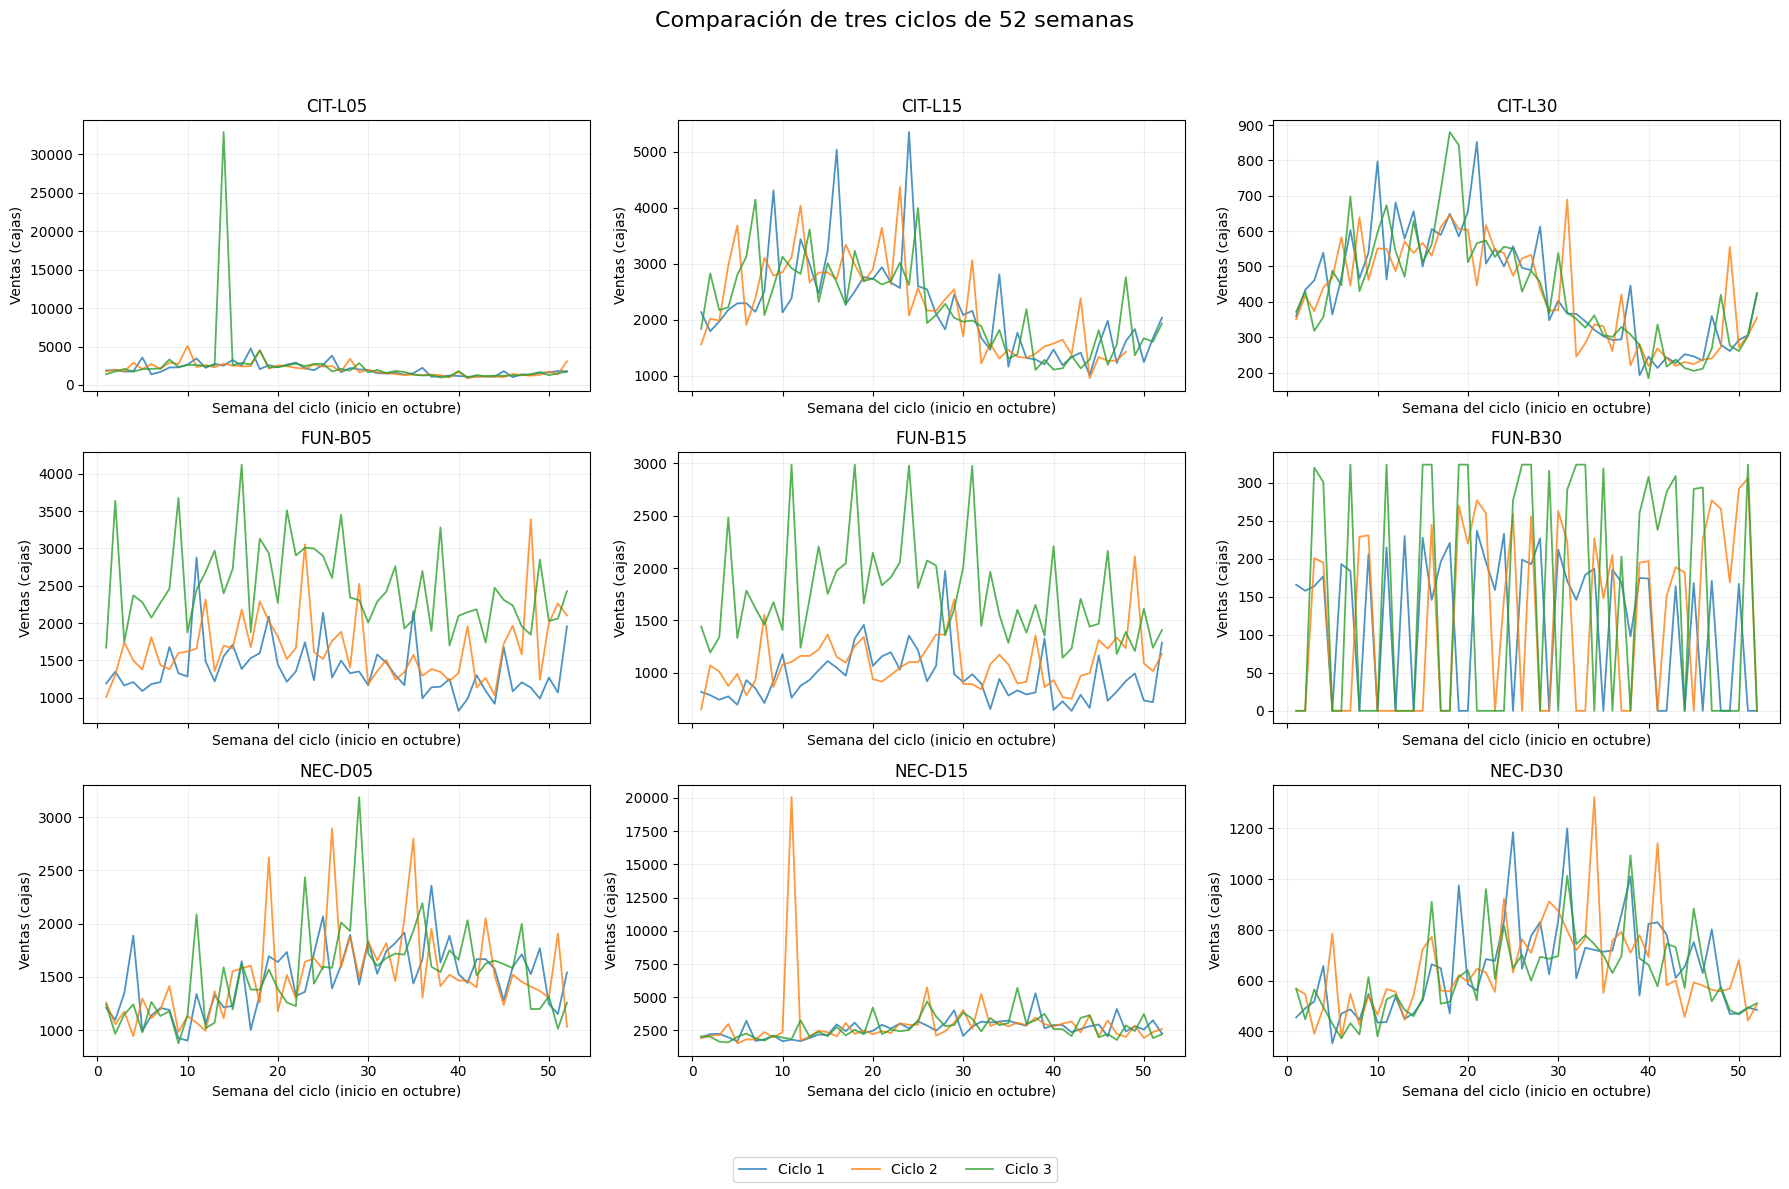

In [73]:
fig_estacional, ejes = plt.subplots(
    3, 3, figsize=(18, 12), sharex=True
)

for eje, sku in zip(ejes.flat, sorted(demanda["sku"].unique())):
    serie = demanda.loc[demanda["sku"] == sku].copy()

    # Tres bloques consecutivos de 52 semanas.
    serie["ciclo"] = ((serie["semana"] - 1) // 52) + 1
    serie["semana_del_ciclo"] = ((serie["semana"] - 1) % 52) + 1

    for ciclo, grupo in serie.groupby("ciclo"):
        grupo = grupo.sort_values("semana_del_ciclo")

        eje.plot(
            grupo["semana_del_ciclo"],
            grupo["ventas_cajas"],
            linewidth=1.3,
            alpha=0.8,
            label=f"Ciclo {int(ciclo)}"
        )

    eje.set_title(sku)
    eje.set_xlabel("Semana del ciclo (inicio en octubre)")
    eje.set_ylabel("Ventas (cajas)")
    eje.grid(alpha=0.2)

handles, labels = ejes.flat[0].get_legend_handles_labels()
fig_estacional.legend(
    handles, labels, loc="lower center", ncol=3
)

fig_estacional.suptitle(
    "Comparación de tres ciclos de 52 semanas", fontsize=16
)
fig_estacional.tight_layout(rect=[0, 0.06, 1, 0.95])
plt.show()

In [74]:
resumen_estacional = []

for sku, grupo in demanda.groupby("sku"):
    grupo = grupo.copy()

    grupo["ciclo"] = ((grupo["semana"] - 1) // 52) + 1
    grupo["semana_del_ciclo"] = ((grupo["semana"] - 1) % 52) + 1

    tabla = grupo.pivot(
        index="semana_del_ciclo",
        columns="ciclo",
        values="ventas_cajas"
    )

    for ciclo_a, ciclo_b in [(1, 2), (2, 3), (1, 3)]:
        pares = tabla[[ciclo_a, ciclo_b]].dropna()

        correlacion = (
            pares[ciclo_a].corr(pares[ciclo_b], method="spearman")
            if len(pares) >= 3
            and pares[ciclo_a].nunique() > 1
            and pares[ciclo_b].nunique() > 1
            else np.nan
        )

        resumen_estacional.append({
            "sku": sku,
            "comparacion": f"Ciclo {ciclo_a} vs {ciclo_b}",
            "semanas_comparables": len(pares),
            "correlacion_spearman": correlacion
        })

resultado_estacional = pd.DataFrame(resumen_estacional)

display(
    resultado_estacional.pivot(
        index="sku",
        columns="comparacion",
        values="correlacion_spearman"
    ).round(3)
)

print("NÚMERO DE SEMANAS COMPARABLES")
display(
    resultado_estacional.pivot(
        index="sku",
        columns="comparacion",
        values="semanas_comparables"
    )
)

comparacion,Ciclo 1 vs 2,Ciclo 1 vs 3,Ciclo 2 vs 3
sku,,,
CIT-L05,0.687,0.736,0.777
CIT-L15,0.681,0.699,0.655
CIT-L30,0.718,0.860,0.781
FUN-B05,0.355,0.361,0.132
FUN-B15,0.321,0.252,0.034
FUN-B30,-0.047,-0.072,0.045
NEC-D05,0.483,0.551,0.485
NEC-D15,0.298,0.382,0.274
NEC-D30,0.562,0.743,0.635


NÚMERO DE SEMANAS COMPARABLES


comparacion,Ciclo 1 vs 2,Ciclo 1 vs 3,Ciclo 2 vs 3
sku,,,
CIT-L05,52,52,52
CIT-L15,49,52,49
CIT-L30,52,52,52
FUN-B05,52,52,52
FUN-B15,52,52,52
FUN-B30,52,52,52
NEC-D05,52,52,52
NEC-D15,52,52,52
NEC-D30,52,52,52


### 1.7. Comparación del nivel de ventas entre ciclos

Se comparan semanas separadas por 52 períodos, con igual indicador
de promoción y sin días de quiebre registrados en ambas semanas.
Se excluyen de esta comparación los dos picos previamente investigados,
sin modificar sus valores originales.

Se calcula la mediana de las razones entre ventas de ambos ciclos.
Este análisis describe cambios de nivel; no identifica por sí solo
un quiebre estructural ni demuestra su causa.

In [75]:
resumen_nivel = []

for sku, grupo in demanda.groupby("sku"):
    grupo = grupo.sort_values("semana").set_index("semana")

    for ciclo_anterior, ciclo_actual in [(1, 2), (2, 3)]:
        razones = []

        inicio = (ciclo_actual - 1) * 52 + 1
        fin = ciclo_actual * 52

        for semana in range(inicio, fin + 1):
            actual = grupo.loc[semana]
            anterior = grupo.loc[semana - 52]

            comparables = (
                pd.notna(actual["ventas_cajas"])
                and pd.notna(anterior["ventas_cajas"])
                and anterior["ventas_cajas"] > 0
                and actual["dias_sin_stock"] == 0
                and anterior["dias_sin_stock"] == 0
                and actual["promocion"] == anterior["promocion"]
                and not actual["pico_candidato_revision"]
                and not anterior["pico_candidato_revision"]
            )

            if comparables:
                razones.append(
                    actual["ventas_cajas"] / anterior["ventas_cajas"]
                )

        razon_mediana = np.median(razones) if razones else np.nan

        resumen_nivel.append({
            "sku": sku,
            "comparacion": f"Ciclo {ciclo_actual} / {ciclo_anterior}",
            "pares_utilizados": len(razones),
            "razon_mediana": razon_mediana,
            "cambio_mediano_porcentaje": 100 * (razon_mediana - 1)
        })

display(pd.DataFrame(resumen_nivel).round(3))

,sku,comparacion,pares_utilizados,razon_mediana,cambio_mediano_porcentaje
0,CIT-L05,Ciclo 2 / 1,40,0.996,-0.363
1,CIT-L05,Ciclo 3 / 2,44,1.038,3.813
2,CIT-L15,Ciclo 2 / 1,39,1.037,3.740
3,CIT-L15,Ciclo 3 / 2,39,0.975,-2.469
4,CIT-L30,Ciclo 2 / 1,40,0.989,-1.102
5,CIT-L30,Ciclo 3 / 2,41,1.033,3.346
6,FUN-B05,Ciclo 2 / 1,41,1.214,21.404
7,FUN-B05,Ciclo 3 / 2,41,1.479,47.898
8,FUN-B15,Ciclo 2 / 1,43,1.181,18.053
9,FUN-B15,Ciclo 3 / 2,40,1.541,54.079


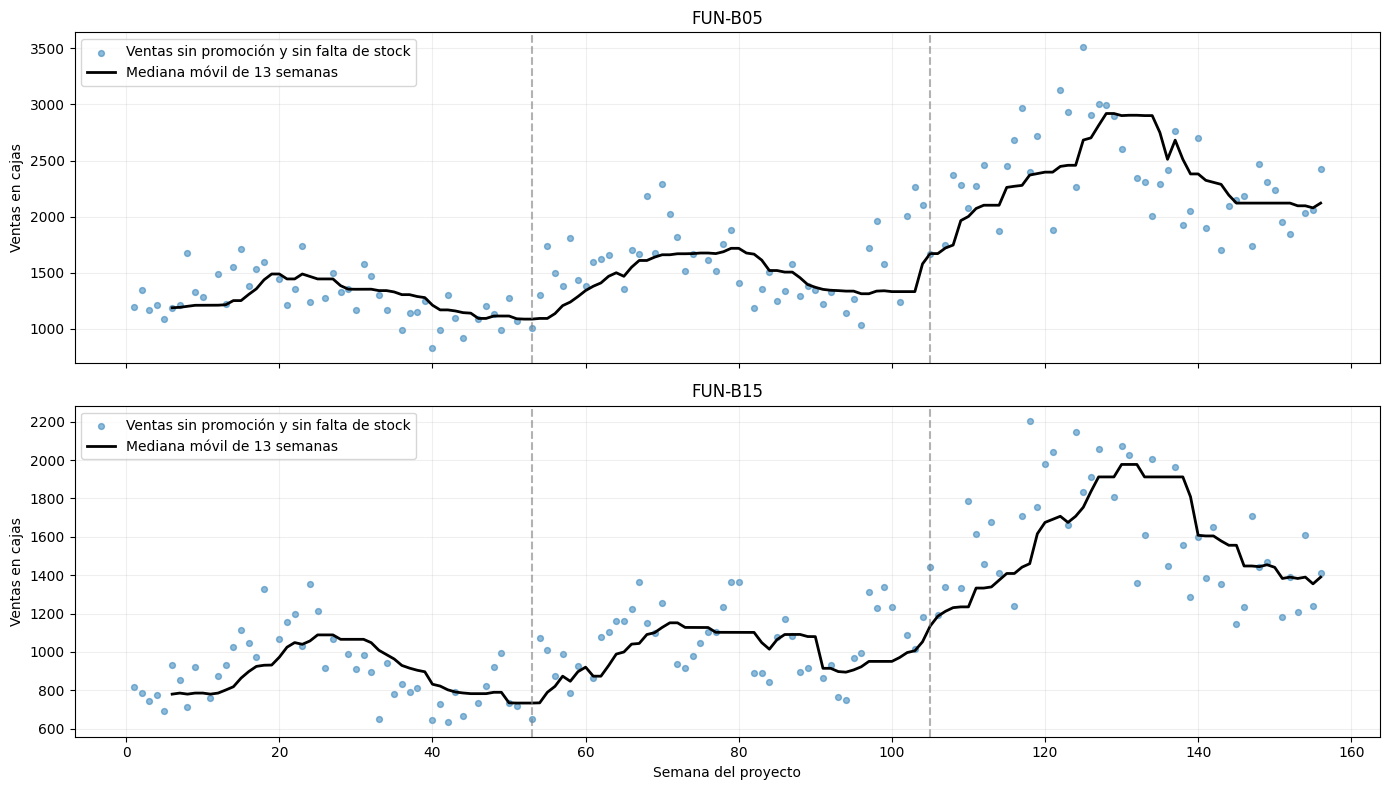

In [76]:
import matplotlib.pyplot as plt

fig_nivel, ejes = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True
)

for ax, sku in zip(ejes, ["FUN-B05", "FUN-B15"]):
    serie = (
        demanda.loc[demanda["sku"] == sku]
        .sort_values("semana")
        .copy()
    )

    # Para esta comparación utilizamos semanas sin promoción
    # y sin días registrados de falta de stock.
    ventas_comparables = serie["ventas_cajas"].where(
        (serie["promocion"] == 0)
        & (serie["dias_sin_stock"] == 0)
        & (~serie["pico_candidato_revision"])
    )

    # Mediana de las últimas 13 semanas.
    nivel_local = ventas_comparables.rolling(
        window=13, min_periods=6
    ).median()

    ax.scatter(
        serie["semana"],
        ventas_comparables,
        s=18, alpha=0.5,
        label="Ventas sin promoción y sin falta de stock"
    )

    ax.plot(
        serie["semana"],
        nivel_local,
        color="black", linewidth=2,
        label="Mediana móvil de 13 semanas"
    )

    for limite in [53, 105]:
        ax.axvline(
            limite, color="gray",
            linestyle="--", alpha=0.6
        )

    ax.set_title(sku)
    ax.set_ylabel("Ventas en cajas")
    ax.grid(alpha=0.2)
    ax.legend()

ejes[-1].set_xlabel("Semana del proyecto")
plt.tight_layout()
plt.show()

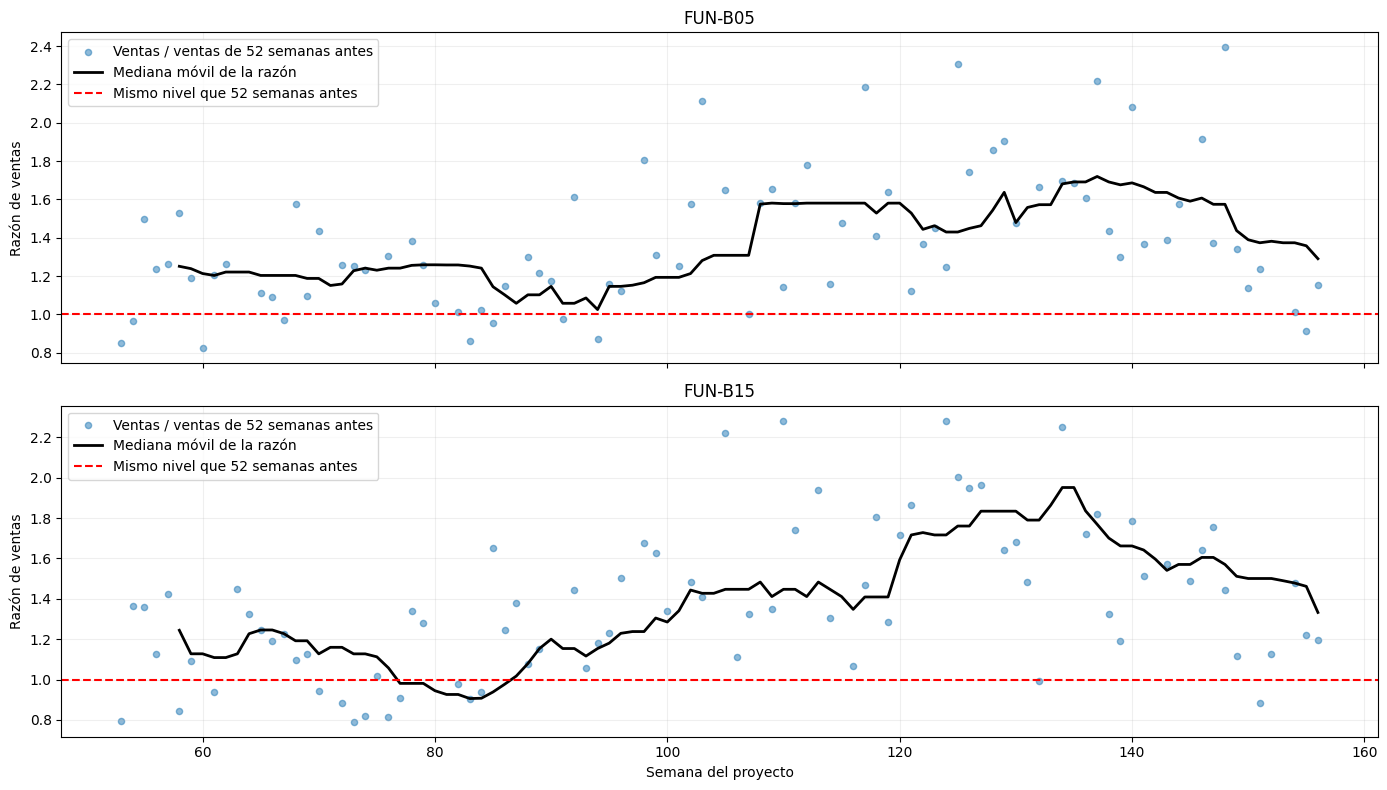

In [77]:
fig_comparacion, ejes = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True
)

for ax, sku in zip(ejes, ["FUN-B05", "FUN-B15"]):
    serie = (
        demanda.loc[demanda["sku"] == sku]
        .sort_values("semana")
        .set_index("semana")
    )

    ventas = serie["ventas_cajas"]

    semana_valida = (
        ventas.notna()
        & (serie["promocion"] == 0)
        & (serie["dias_sin_stock"] == 0)
        & (~serie["pico_candidato_revision"])
    )

    pares_validos = (
        semana_valida
        & semana_valida.shift(52, fill_value=False)
        & (ventas.shift(52) > 0)
    )

    razon = (ventas / ventas.shift(52)).where(pares_validos)

    razon_suavizada = razon.rolling(
        window=13, min_periods=6
    ).median()

    ax.scatter(
        serie.index, razon,
        s=20, alpha=0.5,
        label="Ventas / ventas de 52 semanas antes"
    )

    ax.plot(
        serie.index, razon_suavizada,
        color="black", linewidth=2,
        label="Mediana móvil de la razón"
    )

    ax.axhline(
        1, color="red", linestyle="--",
        label="Mismo nivel que 52 semanas antes"
    )

    ax.set_title(sku)
    ax.set_ylabel("Razón de ventas")
    ax.grid(alpha=0.2)
    ax.legend()

ejes[-1].set_xlabel("Semana del proyecto")
plt.tight_layout()
plt.show()

## Cambios de nivel en FUN-B05 y FUN-B15
Detección: se revisaron los gráficos de ventas, las medianas móviles de 13 semanas y las razones entre las ventas de cada semana y las de 52 semanas antes. Para estas últimas comparaciones se utilizaron pares de semanas sin promoción, sin días registrados de falta de stock y con ventas disponibles.
Hallazgo: ambas series presentan un aumento sostenido del nivel de ventas, especialmente durante el tercer ciclo. En los pares comparables, el aumento mediano respecto del segundo ciclo fue de 47,9 % para FUN-B05 y de 54,1 % para FUN-B15. Los resultados son compatibles con un cambio de nivel, aunque no permiten establecer una fecha exacta de quiebre.
Posible causa: crecimiento de la demanda, ampliación de la distribución o incorporación de clientes. Estas son hipótesis; los datos revisados no permiten confirmar una causa.
Tratamiento: se conservaron las observaciones sin reemplazarlas ni eliminarlas, porque el aumento sostenido no constituye por sí solo un error de registro. En la etapa de modelación se evaluará cómo representar este cambio y su efecto sobre los pronósticos.

In [78]:
base_promociones = demanda.loc[
    demanda["ventas_cajas"].notna()
    & (demanda["dias_sin_stock"] == 0)
    & (~demanda["pico_candidato_revision"])
].copy()

resumen_promociones = []

for sku, grupo in base_promociones.groupby("sku"):
    sin_promo = grupo.loc[grupo["promocion"] == 0]
    con_promo = grupo.loc[grupo["promocion"] == 1]

    mediana_sin = sin_promo["ventas_cajas"].median()
    mediana_con = con_promo["ventas_cajas"].median()

    razon = (
        mediana_con / mediana_sin
        if pd.notna(mediana_sin) and mediana_sin > 0
        else np.nan
    )

    precios_validos = con_promo.loc[
        (con_promo["precio_lista_clp"] > 0)
        & con_promo["precio_efectivo_clp"].notna()
    ]

    descuento = (
        100 * (
            1
            - precios_validos["precio_efectivo_clp"]
            / precios_validos["precio_lista_clp"]
        )
    ).median()

    resumen_promociones.append({
        "sku": sku,
        "semanas_sin_promo": len(sin_promo),
        "semanas_con_promo": len(con_promo),
        "mediana_sin_promo": mediana_sin,
        "mediana_con_promo": mediana_con,
        "razon_con_vs_sin": razon,
        "descuento_mediano_promo_pct": descuento
    })

tabla_promociones = pd.DataFrame(resumen_promociones)

display(tabla_promociones.round(2))

,sku,semanas_sin_promo,semanas_con_promo,mediana_sin_promo,mediana_con_promo,razon_con_vs_sin,descuento_mediano_promo_pct
0,CIT-L05,138,16,1760.5,3362.0,1.91,23.97
1,CIT-L15,138,15,2080.0,3684.0,1.77,19.41
2,CIT-L30,139,17,417.0,556.0,1.33,24.30
3,FUN-B05,139,17,1599.0,2850.0,1.78,23.18
4,FUN-B15,138,16,1099.5,1629.5,1.48,22.76
5,FUN-B30,94,7,0.0,0.0,NaN,23.63
6,NEC-D05,140,16,1432.0,2042.0,1.43,25.32
7,NEC-D15,138,17,2437.5,3736.0,1.53,22.60
8,NEC-D30,138,18,579.5,942.0,1.63,22.69


##Promociones y precios
Detección: se compararon las medianas de ventas de semanas con y sin promoción para cada SKU. Se excluyeron de esta comparación los registros con ventas faltantes, días de falta de stock y los dos picos candidatos previamente identificados. También se calculó el descuento porcentual entre el precio de lista y el precio efectivo.

Hallazgo: en ocho series, las ventas medianas durante promociones fueron mayores que en semanas sin promoción, con diferencias aproximadas entre 33 % y 91 %. Los descuentos medianos promocionales estuvieron entre 19,4 % y 25,3 %. Esta asociación no constituye una estimación causal, porque también pueden influir la estacionalidad y los cambios de nivel.
Caso FUN-B30: las medianas fueron cero en ambos grupos, por lo que no se pudo calcular la razón. La intermitencia y la exclusión de semanas con falta de stock limitan esta comparación.

Tratamiento: se conservaron las ventas promocionales y las variables de promoción y precio. Una venta elevada coincidente con una promoción no se consideró automáticamente un error; los casos extremos se revisaron por separado.

### Bitácora de anomalías y decisiones

| Caso | Cómo se detectó | Hallazgo y posible causa | Tratamiento realizado |
|---|---|---|---|
| Faltantes en CIT-L15, semanas 101, 102 y 103 | Recuento de valores nulos y revisión de las semanas cercanas. | Faltan ventas y días sin stock en tres semanas consecutivas. Posible falla de registro o extracción; causa no confirmada. | Se conservaron las filas y los valores faltantes, con indicadores que permiten identificarlos. No se reemplazaron por cero ni se supuso disponibilidad de stock. La imputación para modelar queda pendiente y deberá utilizar únicamente información disponible en cada entrenamiento. |
| Pico en CIT-L05, semana 118 | Gráfico, comparación con semanas cercanas, otras temporadas y filtro robusto de mediana y MAD. | Venta de 32.916 cajas, aproximadamente 12,68 veces la mediana de las ocho semanas vecinas. No registra promoción ni días sin stock. Posible error de registro o pedido extraordinario; causa no confirmada. | Se conservó el valor original y se marcó como pico candidato a revisión. Se excluyó únicamente de las comparaciones descriptivas de nivel y promociones. No se aplicó una corrección definitiva. |
| Pico en NEC-D15, semana 63 | Gráfico, comparación con semanas cercanas, otras promociones y filtro robusto de mediana y MAD. | Venta de 20.052 cajas, aproximadamente 9,10 veces la mediana de las ocho semanas vecinas. Coincide con una promoción, pero también supera ampliamente otras ventas promocionales. Posible evento extraordinario o error de registro; causa no confirmada. | Se conservó el valor original y se marcó como pico candidato a revisión. Se excluyó únicamente de las comparaciones descriptivas de nivel y promociones. No se aplicó una corrección definitiva. |
| Otras alertas del filtro robusto en las nueve series | Desviación respecto de la mediana de las 13 semanas anteriores, escalada mediante MAD; umbral absoluto de 4,5. | El filtro produjo 65 alertas en total, incluidos los dos picos anteriores. De ellas, 47 coinciden con promociones y 18 no registran promoción ni días sin stock. Las alertas pueden reflejar promociones, estacionalidad, cambios de nivel o intermitencia; no equivalen automáticamente a errores. | Se conservaron las observaciones y el registro de alertas con su contexto. No se reemplazaron ni eliminaron datos de forma automática. |
| Ceros e intermitencia en FUN-B30 | Recuento de ventas iguales a cero, revisión de días sin stock y cálculo de ADI y CV². | Se observaron 69 semanas con ventas cero de 156, equivalentes al 44,23 %. Todas registran cero días sin stock. El ADI observado fue aproximadamente 1,79. Patrón compatible con ventas intermitentes; la causa comercial no está confirmada. | Se conservaron los ceros como ventas observadas y se distinguieron de los datos faltantes. No se interpolaron ni se sustituyeron por ventas positivas. |
| Posible cambio de nivel en FUN-B05 y FUN-B15 | Gráficos, medianas móviles y comparación con ventas de 52 semanas antes, utilizando pares comparables. | Aumento sostenido, especialmente en el tercer ciclo. El cambio mediano entre los ciclos 2 y 3 fue de +47,9 % y +54,1 %, respectivamente. Posible crecimiento comercial; no se confirmó una causa ni una fecha exacta de quiebre. | Se conservaron las ventas, porque un aumento sostenido no constituye por sí solo un error. Se documentó el cambio para considerarlo posteriormente en la modelación. |
| Ventas elevadas durante promociones | Comparación de medianas con y sin promoción y cálculo de descuentos. | En ocho series, las medianas promocionales son mayores. La promoción es una explicación posible de parte del aumento, pero la comparación no demuestra causalidad. En FUN-B30, ambas medianas son cero y la razón no se puede calcular. | Se conservaron las ventas y las variables de promoción y precio. Las observaciones extremas se revisaron por separado. |
| Semanas con falta de stock | Identificación de registros con dias_sin_stock mayor que cero. | Se detectaron 55 semanas en FUN-B30, dos en FUN-B15 y una en CIT-L05. Las ventas de estas semanas pueden estar limitadas por falta de disponibilidad y no representar toda la demanda. | Se identificaron y conservaron los registros. Se excluyeron de algunas comparaciones descriptivas. La reconstrucción de demanda corresponde al punto 2 y todavía no se ha realizado. |

Los archivos originales permanecen sin modificaciones. Conservar una observación, marcarla o excluirla de una comparación descriptiva son decisiones distintas de reemplazar su valor para entrenar un modelo. Los tratamientos pendientes se documentan explícitamente.

### Resumen del diagnóstico de las nueve series

| Serie | Tendencia y cambios de nivel | Estacionalidad | Faltantes | Valores atípicos y promociones | Intermitencia y disponibilidad |
|---|---|---|---|---|---|
| CIT-L05 | Nivel relativamente estable entre ciclos, sin aumento sostenido importante en la comparación realizada. | Patrón anual visible y repetido, con mayores ventas en verano. | Sin faltantes. | Pico candidato en semana 118: 32.916 cajas. Ventas medianas mayores durante promociones. | Sin semanas con ventas cero. Una semana con falta de stock. |
| CIT-L15 | Cambios pequeños de nivel entre ciclos comparables. | Patrón anual visible y repetido, con mayores ventas en verano. | Ventas y días sin stock faltantes en semanas 101–103. | Alertas del filtro robusto que requieren interpretación contextual. Ventas medianas mayores durante promociones. | Sin ceros entre las ventas disponibles. Disponibilidad desconocida en las tres semanas faltantes. |
| CIT-L30 | Nivel relativamente estable entre ciclos. | Patrón anual visible y repetido, con mayores ventas en verano. | Sin faltantes. | Alertas puntuales del filtro robusto. Ventas medianas mayores durante promociones. | Sin ventas cero ni días registrados de falta de stock. |
| FUN-B05 | Aumento sostenido del nivel, especialmente en el tercer ciclo; posible cambio de nivel sin fecha exacta confirmada. | Oscilaciones dentro de los ciclos, con menor repetición que las series CIT. El cambio de nivel dificulta la comparación. | Sin faltantes. | Alertas que pueden coincidir con promociones y aumentos de nivel. Ventas medianas mayores durante promociones. | Sin ventas cero ni días registrados de falta de stock. |
| FUN-B15 | Aumento sostenido del nivel, especialmente en el tercer ciclo; posible cambio de nivel sin fecha exacta confirmada. | Oscilaciones dentro de los ciclos, con poca concordancia entre sus posiciones semanales. | Sin faltantes. | Alertas del filtro robusto. Ventas medianas mayores durante promociones. | Sin ventas cero. Dos semanas con falta de stock. |
| FUN-B30 | No se establece una tendencia clara mediante las comparaciones realizadas. | Sin patrón anual claro en los gráficos y comparaciones entre ciclos. | Sin faltantes. | Varias alertas corresponden a ceros. La razón de medianas promocionales no es calculable porque ambas medianas son cero. | Ventas intermitentes: 69 semanas con cero, equivalentes al 44,23 %. Además, 55 semanas con falta de stock. |
| NEC-D05 | Cambios pequeños de nivel entre ciclos comparables. | Patrón anual visible, con mayores ventas aproximadamente en otoño e invierno. | Sin faltantes. | Alertas puntuales del filtro robusto. Ventas medianas mayores durante promociones. | Sin ventas cero ni días registrados de falta de stock. |
| NEC-D15 | Cambios pequeños de nivel entre ciclos comparables. | Patrón anual sugerido por los gráficos, con menor concordancia entre ciclos que NEC-D05 y NEC-D30. | Sin faltantes. | Pico candidato en semana 63: 20.052 cajas, coincidente con promoción. Ventas medianas mayores durante promociones. | Sin ventas cero ni días registrados de falta de stock. |
| NEC-D30 | Cambios pequeños de nivel entre ciclos comparables. | Patrón anual visible y repetido, con mayores ventas aproximadamente en otoño e invierno. | Sin faltantes. | Alertas del filtro robusto. Ventas medianas mayores durante promociones. | Sin ventas cero ni días registrados de falta de stock. |

### Alcance y decisiones del diagnóstico

El diagnóstico se realizó sobre las ventas observadas. En las semanas con falta de stock, estas pueden ser inferiores a la demanda real.

La estacionalidad y los cambios de nivel se evaluaron mediante gráficos y comparaciones descriptivas. No se confirmó una causa comercial para los cambios ni una fecha exacta de quiebre. Una alerta estadística no se consideró automáticamente un error.

Se conservaron los datos originales, los ceros observados y las ventas promocionales. Se identificaron los faltantes, los picos candidatos y las semanas con falta de stock. La imputación de faltantes y la decisión definitiva sobre los dos picos permanecen pendientes antes de entrenar los modelos.

La reconstrucción de demanda por falta de stock se abordará en el punto 2. Cualquier transformación para evaluar pronósticos deberá utilizar únicamente la información disponible dentro de cada periodo de entrenamiento.

## 2. Tratamiento de censura por falta de stock

### 2.1. Identificación de semanas censuradas

Se identifican como potencialmente censuradas las semanas con días registrados de falta de stock. En ellas, las ventas observadas pueden ser inferiores a la demanda real.

Los registros sin información de disponibilidad se mantienen separados: no se supone que tuvieron stock ni que estuvieron censurados.

In [79]:
# Creamos una copia para trabajar el punto 2.
demanda_censura = demanda.copy()

demanda_censura["estado_stock"] = np.select(
    [
        demanda_censura["dias_sin_stock"].isna(),
        demanda_censura["dias_sin_stock"] > 0
    ],
    [
        "Disponibilidad desconocida",
        "Potencialmente censurada"
    ],
    default="Sin falta de stock registrada"
)

resumen_censura = (
    demanda_censura
    .groupby(["sku", "estado_stock"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=[
            "Sin falta de stock registrada",
            "Potencialmente censurada",
            "Disponibilidad desconocida"
        ],
        fill_value=0
    )
)

display(resumen_censura)

semanas_censuradas = demanda_censura.loc[
    demanda_censura["dias_sin_stock"] > 0,
    [
        "sku",
        "semana",
        "fecha_lunes",
        "ventas_cajas",
        "dias_sin_stock",
        "promocion"
    ]
].sort_values(["sku", "semana"])

print(
    "Total de semanas potencialmente censuradas:",
    len(semanas_censuradas)
)

display(semanas_censuradas.head(15))

display(
    semanas_censuradas
    .groupby(["sku", "dias_sin_stock"])
    .size()
    .rename("numero_semanas")
    .reset_index()
)

estado_stock,Sin falta de stock registrada,Potencialmente censurada,Disponibilidad desconocida
sku,,,
CIT-L05,155,1,0
CIT-L15,153,0,3
CIT-L30,156,0,0
FUN-B05,156,0,0
FUN-B15,154,2,0
FUN-B30,101,55,0
NEC-D05,156,0,0
NEC-D15,156,0,0
NEC-D30,156,0,0


Total de semanas potencialmente censuradas: 58


,sku,semana,fecha_lunes,ventas_cajas,dias_sin_stock,promocion
571,CIT-L05,104,2025-09-22,3078.0,1.0,1
1206,FUN-B15,115,2025-12-08,2988.0,1.0,1
1213,FUN-B15,122,2026-01-26,2988.0,1.0,1
1249,FUN-B30,2,2023-10-09,158.0,2.0,0
1250,FUN-B30,3,2023-10-16,164.0,1.0,0
1251,FUN-B30,4,2023-10-23,177.0,1.0,0
1253,FUN-B30,6,2023-11-06,193.0,4.0,1
1254,FUN-B30,7,2023-11-13,184.0,1.0,0
1256,FUN-B30,9,2023-11-27,206.0,4.0,0
1258,FUN-B30,11,2023-12-11,215.0,3.0,0


,sku,dias_sin_stock,numero_semanas
0,CIT-L05,1.0,1
1,FUN-B15,1.0,2
2,FUN-B30,1.0,10
3,FUN-B30,2.0,21
4,FUN-B30,3.0,12
5,FUN-B30,4.0,9
6,FUN-B30,5.0,3


### 2.2. Reconstrucción proporcional por disponibilidad

Se calcula una estimación inicial de demanda multiplicando las ventas observadas por 7 / (7 − días sin stock).

El método supone siete días de posible venta por semana y una demanda diaria aproximadamente constante dentro de cada semana. No permite conocer con certeza las ventas perdidas ni representar diferencias entre días.

Las ventas originales se conservan. Los registros con disponibilidad desconocida permanecen sin reconstruir. Los ceros sin falta de stock registrada se mantienen como ceros.

In [80]:
def reconstruir_por_disponibilidad(datos):
    resultado = datos.copy()

    dias = resultado["dias_sin_stock"]
    ventas = resultado["ventas_cajas"]

    sin_censura = dias.eq(0) & ventas.notna()
    censura_parcial = dias.gt(0) & dias.lt(7) & ventas.notna()

    resultado["dias_disponibles"] = 7 - dias

    resultado["factor_disponibilidad"] = np.nan
    resultado.loc[sin_censura, "factor_disponibilidad"] = 1.0
    resultado.loc[
        censura_parcial, "factor_disponibilidad"
    ] = 7 / resultado.loc[censura_parcial, "dias_disponibles"]

    resultado["demanda_estimada_disponibilidad"] = np.nan

    resultado.loc[
        sin_censura, "demanda_estimada_disponibilidad"
    ] = ventas.loc[sin_censura]

    resultado.loc[
        censura_parcial, "demanda_estimada_disponibilidad"
    ] = (
        ventas.loc[censura_parcial]
        * resultado.loc[censura_parcial, "factor_disponibilidad"]
    )

    resultado["cajas_adicionales_estimadas"] = (
        resultado["demanda_estimada_disponibilidad"] - ventas
    )

    resultado["tratamiento_censura"] = np.select(
        [
            ventas.isna(),
            dias.isna(),
            dias.eq(7),
            censura_parcial,
            sin_censura
        ],
        [
            "Ventas faltantes: pendiente",
            "Disponibilidad desconocida: pendiente",
            "Sin disponibilidad: requiere otro método",
            "Ajuste proporcional por disponibilidad",
            "Ventas conservadas sin ajuste"
        ],
        default="Registro a revisar"
    )

    return resultado


demanda_censura = reconstruir_por_disponibilidad(demanda_censura)

columnas_revision = [
    "sku",
    "semana",
    "ventas_cajas",
    "dias_sin_stock",
    "dias_disponibles",
    "factor_disponibilidad",
    "demanda_estimada_disponibilidad",
    "cajas_adicionales_estimadas"
]

ajustes_censura = demanda_censura.loc[
    demanda_censura["dias_sin_stock"] > 0,
    columnas_revision
].sort_values(["sku", "semana"])

display(ajustes_censura.head(15).round(2))

resumen_ajustes = (
    ajustes_censura.groupby("sku")
    .agg(
        semanas_ajustadas=("semana", "size"),
        ventas_observadas=("ventas_cajas", "sum"),
        demanda_estimada=("demanda_estimada_disponibilidad", "sum"),
        cajas_adicionales=("cajas_adicionales_estimadas", "sum"),
        factor_maximo=("factor_disponibilidad", "max")
    )
)

display(resumen_ajustes.round(2))

,sku,semana,ventas_cajas,dias_sin_stock,dias_disponibles,factor_disponibilidad,demanda_estimada_disponibilidad,cajas_adicionales_estimadas
571,CIT-L05,104,3078.0,1.0,6.0,1.17,3591.00,513.00
1206,FUN-B15,115,2988.0,1.0,6.0,1.17,3486.00,498.00
1213,FUN-B15,122,2988.0,1.0,6.0,1.17,3486.00,498.00
1249,FUN-B30,2,158.0,2.0,5.0,1.40,221.20,63.20
1250,FUN-B30,3,164.0,1.0,6.0,1.17,191.33,27.33
1251,FUN-B30,4,177.0,1.0,6.0,1.17,206.50,29.50
1253,FUN-B30,6,193.0,4.0,3.0,2.33,450.33,257.33
1254,FUN-B30,7,184.0,1.0,6.0,1.17,214.67,30.67
1256,FUN-B30,9,206.0,4.0,3.0,2.33,480.67,274.67
1258,FUN-B30,11,215.0,3.0,4.0,1.75,376.25,161.25


,semanas_ajustadas,ventas_observadas,demanda_estimada,cajas_adicionales,factor_maximo
sku,,,,,
CIT-L05,1,3078.0,3591.0,513.0,1.17
FUN-B15,2,5976.0,6972.0,996.0,1.17
FUN-B30,55,13623.0,23491.3,9868.3,3.50


,resultado
Semanas censuradas con estimación,58
Estimaciones inferiores a ventas observadas,0
Semanas sin censura modificadas,0
Ceros sin censura modificados,0
Estimaciones infinitas,0
Registros sin estimación,3


Diez casos con mayor factor de ajuste:


,sku,semana,ventas_cajas,dias_sin_stock,dias_disponibles,factor_disponibilidad,demanda_estimada_disponibilidad,cajas_adicionales_estimadas
1367,FUN-B30,120,324.0,5.0,2.0,3.50,1134.00,810.00
1377,FUN-B30,130,324.0,5.0,2.0,3.50,1134.00,810.00
1339,FUN-B30,92,197.0,5.0,2.0,3.50,689.50,492.50
1378,FUN-B30,131,324.0,4.0,3.0,2.33,756.00,432.00
1383,FUN-B30,136,324.0,4.0,3.0,2.33,756.00,432.00
1320,FUN-B30,73,277.0,4.0,3.0,2.33,646.33,369.33
1318,FUN-B30,71,270.0,4.0,3.0,2.33,630.00,360.00
1326,FUN-B30,79,256.0,4.0,3.0,2.33,597.33,341.33
1256,FUN-B30,9,206.0,4.0,3.0,2.33,480.67,274.67
1253,FUN-B30,6,193.0,4.0,3.0,2.33,450.33,257.33


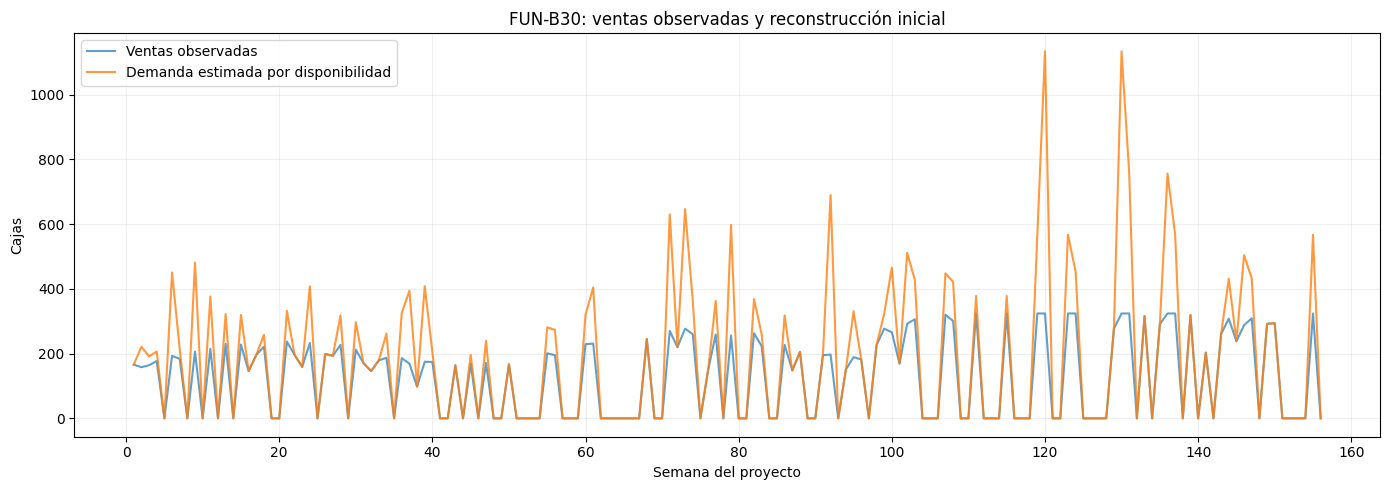

In [81]:
ventas = demanda_censura["ventas_cajas"]
estimacion = demanda_censura["demanda_estimada_disponibilidad"]
dias = demanda_censura["dias_sin_stock"]

sin_censura = dias.eq(0) & ventas.notna()
con_censura = dias.gt(0) & dias.lt(7) & ventas.notna()

ceros_sin_censura = sin_censura & ventas.eq(0)

comprobaciones = pd.Series({
    "Semanas censuradas con estimación":
        int((con_censura & estimacion.notna()).sum()),

    "Estimaciones inferiores a ventas observadas":
        int((con_censura & (estimacion < ventas)).sum()),

    "Semanas sin censura modificadas":
        int((
            sin_censura
            & ~np.isclose(estimacion, ventas, equal_nan=True)
        ).sum()),

    "Ceros sin censura modificados":
        int((
            ceros_sin_censura
            & ~estimacion.eq(0)
        ).sum()),

    "Estimaciones infinitas":
        int(np.isinf(estimacion).sum()),

    "Registros sin estimación":
        int(estimacion.isna().sum())
})

display(comprobaciones.to_frame("resultado"))

print("Diez casos con mayor factor de ajuste:")

display(
    ajustes_censura
    .sort_values(
        ["factor_disponibilidad", "cajas_adicionales_estimadas"],
        ascending=False
    )
    .head(10)
    .round(2)
)

serie = (
    demanda_censura.loc[demanda_censura["sku"] == "FUN-B30"]
    .sort_values("semana")
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    serie["semana"],
    serie["ventas_cajas"],
    label="Ventas observadas",
    alpha=0.7
)

ax.plot(
    serie["semana"],
    serie["demanda_estimada_disponibilidad"],
    label="Demanda estimada por disponibilidad",
    alpha=0.8
)

ax.set_title("FUN-B30: ventas observadas y reconstrucción inicial")
ax.set_xlabel("Semana del proyecto")
ax.set_ylabel("Cajas")
ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()
plt.show()

In [82]:
comparacion_sensibilidad = []

for sku, grupo in demanda_censura.groupby("sku"):
    censuradas = grupo.loc[
        grupo["dias_sin_stock"].gt(0)
        & grupo["dias_sin_stock"].lt(7)
        & grupo["ventas_cajas"].notna()
    ].copy()

    if censuradas.empty:
        continue

    ventas = censuradas["ventas_cajas"]
    factor = censuradas["factor_disponibilidad"]

    escenarios = {
        "Sin ajuste": ventas,
        "Factor limitado a 2": ventas * factor.clip(upper=2),
        "Proporcional completo": ventas * factor
    }

    for nombre, valores in escenarios.items():
        comparacion_sensibilidad.append({
            "sku": sku,
            "escenario": nombre,
            "semanas": len(censuradas),
            "total_cajas": valores.sum(),
            "cajas_adicionales": (valores - ventas).sum(),
            "maximo_semanal": valores.max()
        })

tabla_sensibilidad = pd.DataFrame(comparacion_sensibilidad)

display(tabla_sensibilidad.round(2))

,sku,escenario,semanas,total_cajas,cajas_adicionales,maximo_semanal
0,CIT-L05,Sin ajuste,1,3078.00,0.00,3078.0
1,CIT-L05,Factor limitado a 2,1,3591.00,513.00,3591.0
2,CIT-L05,Proporcional completo,1,3591.00,513.00,3591.0
3,FUN-B15,Sin ajuste,2,5976.00,0.00,2988.0
4,FUN-B15,Factor limitado a 2,2,6972.00,996.00,3486.0
5,FUN-B15,Proporcional completo,2,6972.00,996.00,3486.0
6,FUN-B30,Sin ajuste,55,13623.00,0.00,324.0
7,FUN-B30,Factor limitado a 2,55,21492.47,7869.47,648.0
8,FUN-B30,Proporcional completo,55,23491.30,9868.30,1134.0


In [83]:
def preparar_censura_entrenamiento(datos, semana_corte):
    entrenamiento = datos.loc[
        datos["semana"] <= semana_corte
    ].copy()

    resultado = reconstruir_por_disponibilidad(entrenamiento)

    ventas = resultado["ventas_cajas"]
    dias = resultado["dias_sin_stock"]

    datos_validos = (
        ventas.notna()
        & dias.ge(0)
        & dias.lt(7)
    )

    resultado["objetivo_sin_ajuste"] = ventas.where(datos_validos)

    resultado["objetivo_proporcional"] = (
        resultado["demanda_estimada_disponibilidad"]
    )

    resultado["objetivo_factor_maximo_2"] = (
        ventas
        * resultado["factor_disponibilidad"].clip(upper=2)
    )

    return resultado


# Ejemplo para comprobar el corte.
# Todavía no estamos entrenando modelos.
ejemplo_entrenamiento = preparar_censura_entrenamiento(
    demanda, semana_corte=104
)

print(
    "Última semana incluida:",
    ejemplo_entrenamiento["semana"].max()
)

print(
    "Registros posteriores al corte:",
    (ejemplo_entrenamiento["semana"] > 104).sum()
)

display(
    ejemplo_entrenamiento.loc[
        ejemplo_entrenamiento["dias_sin_stock"] > 0,
        [
            "sku",
            "semana",
            "ventas_cajas",
            "dias_sin_stock",
            "objetivo_sin_ajuste",
            "objetivo_factor_maximo_2",
            "objetivo_proporcional"
        ]
    ].head(10).round(2)
)

Última semana incluida: 104
Registros posteriores al corte: 0


,sku,semana,ventas_cajas,dias_sin_stock,objetivo_sin_ajuste,objetivo_factor_maximo_2,objetivo_proporcional
571,CIT-L05,104,3078.0,1.0,3078.0,3591.00,3591.00
1249,FUN-B30,2,158.0,2.0,158.0,221.20,221.20
1250,FUN-B30,3,164.0,1.0,164.0,191.33,191.33
1251,FUN-B30,4,177.0,1.0,177.0,206.50,206.50
1253,FUN-B30,6,193.0,4.0,193.0,386.00,450.33
1254,FUN-B30,7,184.0,1.0,184.0,214.67,214.67
1256,FUN-B30,9,206.0,4.0,206.0,412.00,480.67
1258,FUN-B30,11,215.0,3.0,215.0,376.25,376.25
1260,FUN-B30,13,230.0,2.0,230.0,322.00,322.00
1262,FUN-B30,15,228.0,2.0,228.0,319.20,319.20


### 2.3. Resultados, sensibilidad y aplicación en entrenamiento

Se identificaron 58 semanas potencialmente censuradas: una en CIT-L05, dos en FUN-B15 y 55 en FUN-B30. Todas registran entre uno y cinco días sin stock.

Se implementó una reconstrucción proporcional por disponibilidad, suponiendo siete días de posible venta y una demanda diaria aproximadamente constante. Las ventas originales y los ceros sin falta de stock registrada se conservaron.

En FUN-B30, la reconstrucción proporcional elevó el total de las semanas censuradas de 13.623 a 23.491,30 cajas. El escenario con factor máximo de 2 produjo 21.492,47 cajas. Sus máximos semanales fueron 1.134 y 648 cajas, respectivamente. El límite de 2 es un escenario de sensibilidad y no un parámetro validado.

La demanda real no está disponible para comprobar directamente la precisión de estas reconstrucciones. Los resultados representan estimaciones bajo supuestos, no ventas perdidas confirmadas.

Para evaluar pronósticos, primero se seleccionará cada periodo de entrenamiento y después se aplicará la reconstrucción. Los escenarios se compararán utilizando las mismas ventanas y un criterio de evaluación común. No se elegirá un escenario comparando errores calculados contra objetivos diferentes como si fueran equivalentes.

Las ventas de semanas de evaluación sin falta de stock registrada permiten una comparación observable. En semanas censuradas, cualquier evaluación contra demanda reconstruida deberá identificarse como evaluación contra una estimación.

Los tres registros de CIT-L15 con ventas y disponibilidad faltantes permanecen pendientes de un tratamiento separado. Tampoco se han resuelto todavía las correcciones definitivas de los dos picos candidatos del punto 1.

## 3. Partición temporal y modelos

Se comparan modelos mediante validación por origen deslizante. Los candidatos incluyen ingenuo simple, ingenuo estacional, deriva, suavizamiento exponencial simple (SES), Holt, suavizamiento con estacionalidad aditiva sin tendencia y SARIMA estacional.

El modelo denominado “HW aditivo” en las tablas está configurado con trend=None: incorpora estacionalidad aditiva, pero no tendencia. Holt incorpora tendencia sin estacionalidad.

También se evalúa un SARIMAX con promoción y descuento porcentual como regresores. El precio de lista es constante dentro de cada SKU; el descuento representa la variación del precio efectivo respecto de ese precio de lista.

Como no se dispone de un calendario promocional confirmado al origen, los regresores futuros se generan mediante un escenario hipotético basado exclusivamente en el entrenamiento. Sus resultados se interpretan como una evaluación exploratoria de ese escenario, no como evidencia concluyente del aporte de un calendario comercial conocido.

En cada ventana se separan primero entrenamiento y evaluación. Después se reconstruye la demanda del entrenamiento y se imputan sus faltantes con la mediana de hasta 13 valores anteriores disponibles. Los dos picos candidatos se conservan en esta comparación inicial; su sensibilidad se revisará por separado.

Se comprueba la convergencia de SARIMA y SARIMAX antes de utilizar sus pronósticos.

In [84]:

import warnings

from statsmodels.tsa.holtwinters import (
    SimpleExpSmoothing, Holt, ExponentialSmoothing
)
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("default")

H = 13
M = 52
N_VENTANAS = 8
PASO = 5
MIN_ENTRENAMIENTO = 2 * M
OBJETIVO = "demanda_estimada_disponibilidad"


def imputar_solo_entrenamiento(y, ventana=13):
    """Imputa NaN sin usar valores posteriores ni del bloque de prueba."""
    y = pd.Series(y, dtype=float).reset_index(drop=True).copy()
    for i in y.index[y.isna()]:
        historia = y.iloc[max(0, i - ventana):i].dropna()
        if not historia.empty:
            y.iloc[i] = historia.median()
        else:
            raise ValueError("No hay historia previa para imputar el primer faltante.")
    if not np.isfinite(y.to_numpy()).all():
        raise ValueError("Persisten faltantes o infinitos tras imputar el entrenamiento.")
    return y.to_numpy(dtype=float)


def pronosticar_candidatos(y_train, h=H, periodo=M):
    """Ajusta candidatos predefinidos usando exclusivamente y_train."""
    y_train = np.asarray(y_train, dtype=float)
    if len(y_train) < 2:
        raise ValueError("Entrenamiento insuficiente.")

    pred = {
        "Ingenuo simple": np.repeat(y_train[-1], h),
        "Deriva": y_train[-1] + np.arange(1, h + 1) *
                   (y_train[-1] - y_train[0]) / (len(y_train) - 1),
    }
    if len(y_train) >= periodo:
        pred["Ingenuo estacional"] = np.resize(y_train[-periodo:], h)

    pred["SES"] = SimpleExpSmoothing(
        y_train, initialization_method="estimated"
    ).fit(optimized=True).forecast(h)
    pred["Holt"] = Holt(
        y_train, initialization_method="estimated"
    ).fit(optimized=True).forecast(h)

    if len(y_train) >= 2 * periodo:
        pred["HW aditivo"] = ExponentialSmoothing(
            y_train, trend=None, seasonal="add", seasonal_periods=periodo,
            initialization_method="estimated"
        ).fit(optimized=True).forecast(h)

        modelo_sarima = SARIMAX(
            y_train,
            order=(1, 0, 0),
            seasonal_order=(0, 1, 0, periodo),
            trend="c",
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        ajuste_sarima = modelo_sarima.fit(
            disp=False, maxiter=200
        )

        if not ajuste_sarima.mle_retvals.get("converged", False):
            raise RuntimeError(
                "SARIMA no convergió. Revisar el ajuste "
                "antes de utilizar sus pronósticos."
            )

        pred["SARIMA(1,0,0)(0,1,0,52)"] = (
            ajuste_sarima.forecast(h)
        )

    # La demanda no puede ser negativa. El recorte se aplica igual a todos los folds.
    return {nombre: np.maximum(0.0, np.asarray(valores, dtype=float))
            for nombre, valores in pred.items()}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Se evaluará el uso de SARIMAX con regresores externos como promoción, precio de lista no cambia por que es cte en los períodos y precio efectivo es afectado por las promociones, para eso evaluaremos cada cuanto historícamente hubo promociones y de cuanto fue.

In [85]:

# Resumen de variabilidad comercial por SKU
diagnostico_comercial = (
    demanda.groupby("sku")
    .agg(
        Semanas=("fecha_lunes", "count"),
        Precios_lista_distintos=("precio_lista_clp", "nunique"),
        Precios_efectivos_distintos=("precio_efectivo_clp", "nunique"),
        Semanas_promocion=("promocion", "sum"),
        Valores_promocion_distintos=("promocion", "nunique"),
    )
    .reset_index()
)

diagnostico_comercial["Porcentaje_promocion"] = (
    100 * diagnostico_comercial["Semanas_promocion"]
    / diagnostico_comercial["Semanas"]
)

display(diagnostico_comercial.round(2))

,sku,Semanas,Precios_lista_distintos,Precios_efectivos_distintos,Semanas_promocion,Valores_promocion_distintos,Porcentaje_promocion
0,CIT-L05,156,1,18,17,2,10.90
1,CIT-L15,156,1,17,16,2,10.26
2,CIT-L30,156,1,18,17,2,10.90
3,FUN-B05,156,1,18,17,2,10.90
4,FUN-B15,156,1,19,18,2,11.54
5,FUN-B30,156,1,18,17,2,10.90
6,NEC-D05,156,1,17,16,2,10.26
7,NEC-D15,156,1,19,18,2,11.54
8,NEC-D30,156,1,19,18,2,11.54


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [86]:

from IPython.display import display

H = 13
rng = np.random.default_rng(123)

# Copia de los datos originales
datos = demanda.copy()

# Asegurar formato numérico
for col in [
    "promocion",
    "precio_lista_clp",
    "precio_efectivo_clp"
]:
    datos[col] = pd.to_numeric(datos[col], errors="coerce")

# Calcular descuento porcentual
datos["descuento_pct"] = (
    100 * (
        1 - datos["precio_efectivo_clp"]
        / datos["precio_lista_clp"]
    )
)

resumen = []
escenarios = []

for sku, grupo in datos.groupby("sku"):
    grupo = grupo.sort_values("fecha_lunes").copy()

    # Últimas 13 semanas como prueba:
    # solo usamos el entrenamiento para crear el escenario
    train = grupo.iloc[:-13].copy()

    promo = train["promocion"].fillna(0)
    frecuencia = (promo == 1).mean()
    n_promos = round(frecuencia * H)

    descuentos = train.loc[
        (promo == 1)
        & train["descuento_pct"].notna()
        & (train["descuento_pct"] > 0),
        "descuento_pct"
    ].to_numpy()

    # Seleccionar semanas futuras promocionales
    posiciones = np.zeros(H, dtype=int)

    if n_promos > 0:
        elegidas = rng.choice(
            H, size=n_promos, replace=False
        )
        posiciones[elegidas] = 1

    # Asignar descuentos históricos a esas semanas
    descuentos_futuros = np.zeros(H)

    if posiciones.sum() > 0 and len(descuentos) > 0:
        descuentos_futuros[posiciones == 1] = rng.choice(
            descuentos,
            size=posiciones.sum(),
            replace=True
        )

    # Fechas posteriores al entrenamiento
    fechas = grupo["fecha_lunes"].iloc[-H:].to_numpy()

    for i in range(H):
        escenarios.append({
            "sku": sku,
            "fecha": fechas[i],
            "promocion_escenario": posiciones[i],
            "descuento_escenario_pct": round(
                descuentos_futuros[i], 2
            )
        })

    resumen.append({
        "sku": sku,
        "semanas_entrenamiento": len(train),
        "promociones_entrenamiento": int((promo == 1).sum()),
        "frecuencia_promociones_pct": round(
            frecuencia * 100, 2
        ),
        "promociones_13_semanas": int(posiciones.sum()),
        "descuento_promedio_historico_pct": round(
            descuentos.mean(), 2
        ) if len(descuentos) else np.nan
    })

tabla_resumen = pd.DataFrame(resumen)
tabla_escenarios = pd.DataFrame(escenarios)

print("RESUMEN POR SKU")
display(tabla_resumen)

print("ESCENARIO PROMOCIONAL PARA LAS PRÓXIMAS 13 SEMANAS")
display(tabla_escenarios)

RESUMEN POR SKU


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,sku,semanas_entrenamiento,promociones_entrenamiento,frecuencia_promociones_pct,promociones_13_semanas,descuento_promedio_historico_pct
0,CIT-L05,143,15,10.49,1,22.26
1,CIT-L15,143,15,10.49,1,20.29
2,CIT-L30,143,15,10.49,1,22.98
3,FUN-B05,143,16,11.19,1,22.94
4,FUN-B15,143,16,11.19,1,21.91
5,FUN-B30,143,15,10.49,1,22.39
6,NEC-D05,143,14,9.79,1,24.97
7,NEC-D15,143,16,11.19,1,21.57
8,NEC-D30,143,17,11.89,2,23.34


ESCENARIO PROMOCIONAL PARA LAS PRÓXIMAS 13 SEMANAS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,sku,fecha,promocion_escenario,descuento_escenario_pct
0,CIT-L05,2026-06-29,1,23.98
1,CIT-L05,2026-07-06,0,0.00
2,CIT-L05,2026-07-13,0,0.00
3,CIT-L05,2026-07-20,0,0.00
4,CIT-L05,2026-07-27,0,0.00
...,...,...,...,...
112,NEC-D30,2026-08-24,0,0.00
113,NEC-D30,2026-08-31,1,25.61
114,NEC-D30,2026-09-07,1,21.12
115,NEC-D30,2026-09-14,0,0.00


Se decidió incorporar la variable promocion como regresor externo en el modelo SARIMAX, debido a que se identificó la presencia recurrente de promociones en las nueve series analizadas. Durante los períodos de entrenamiento, la frecuencia promocional se situó entre un 9,79 % y un 11,89 % de las semanas, con descuentos promedio históricos de entre un 20,29 % y un 24,97 % respecto al precio de lista.

Estos resultados sugieren que las promociones constituyen un factor comercial potencialmente relevante para explicar variaciones en la demanda, por lo que se evaluará su aporte predictivo mediante la comparación entre SARIMA y SARIMAX.

Dado que no se dispone de un calendario comercial confirmado para las próximas 13 semanas, se construirá un escenario hipotético a partir de la frecuencia de promociones y los descuentos observados durante cada período de entrenamiento. El escenario resultante se utilizará como variable exógena futura del SARIMAX, y su desempeño se evaluará mediante validación temporal, utilizando las mismas ventanas y métricas que los demás modelos.

In [87]:

def pronosticar_sarimax_promociones(
    train_raw, y_train, h=H, periodo=M, semilla=123
):
    promo = pd.to_numeric(
        train_raw["promocion"], errors="coerce"
    ).fillna(0).to_numpy(dtype=float)

    lista = pd.to_numeric(
        train_raw["precio_lista_clp"], errors="coerce"
    )
    efectivo = pd.to_numeric(
        train_raw["precio_efectivo_clp"], errors="coerce"
    )

    descuento = (100 * (1 - efectivo / lista)).replace(
        [np.inf, -np.inf], np.nan
    )

    descuento_array = descuento.to_numpy(dtype=float)

    mascara = (
        (promo == 1)
        & np.isfinite(descuento_array)
        & (descuento_array > 0)
    )
    descuentos_hist = descuento_array[mascara]

    # Crear escenario promocional futuro usando solo el entrenamiento
    frecuencia = np.mean(promo == 1)
    n_promos = min(
        h, int(np.floor(frecuencia * h + 0.5))
    )

    rng = np.random.default_rng(semilla)
    promo_future = np.zeros(h)

    if n_promos > 0:
        posiciones = rng.choice(
            h, size=n_promos, replace=False
        )
        promo_future[posiciones] = 1

    X_train = pd.DataFrame({"promocion": promo})
    X_future = pd.DataFrame({"promocion": promo_future})

    # Incorporar descuentos si hay descuentos históricos válidos
    if len(descuentos_hist) > 0:
        X_train["descuento_pct"] = descuento.fillna(0).to_numpy()

        descuento_future = np.zeros(h)
        n_futuras = int(promo_future.sum())

        if n_futuras > 0:
            descuento_future[promo_future == 1] = rng.choice(
                descuentos_hist,
                size=n_futuras,
                replace=True
            )

        X_future["descuento_pct"] = descuento_future

    modelo = SARIMAX(
        y_train,
        exog=X_train,
        order=(1, 0, 0),
        seasonal_order=(0, 1, 0, periodo),
        trend="c",
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    ajuste = modelo.fit(disp=False, maxiter=200)
    if not ajuste.mle_retvals.get("converged", False):
        raise RuntimeError(
            "SARIMAX con promociones no convergió. "
            "Revisar el ajuste antes de utilizar sus pronósticos."
        )

    pronostico = ajuste.forecast(
        steps=h,
        exog=X_future
    )

    return (
        np.maximum(0, np.asarray(pronostico, dtype=float)),
        X_future
    )



## 4. Validación por origen deslizante

Se usan ocho orígenes, horizonte `h=13` y paso de cinco semanas. La ventana es expansiva: cada fold usa todo el pasado disponible y vuelve a ajustar los modelos. La evaluación principal excluye semanas con falta de stock o ventas faltantes, porque allí la demanda real no es observable. Se reporta la cobertura para que esa exclusión sea explícita.

In [88]:
ESCENARIOS_CENSURA = [
    "Sin ajuste",
    "Factor limitado a 2",
    "Proporcional completo"
]


def preparar_objetivo_censura(train_raw, escenario):
    train = reconstruir_por_disponibilidad(train_raw)

    ventas = pd.to_numeric(
        train["ventas_cajas"], errors="coerce"
    )

    dias = pd.to_numeric(
        train["dias_sin_stock"], errors="coerce"
    )

    validos = ventas.notna() & dias.ge(0) & dias.lt(7)

    if escenario == "Sin ajuste":
        objetivo = ventas.where(validos)

    elif escenario == "Factor limitado a 2":
        objetivo = (
            ventas
            * train["factor_disponibilidad"].clip(upper=2)
        )

    elif escenario == "Proporcional completo":
        objetivo = train["demanda_estimada_disponibilidad"]

    else:
        raise ValueError(f"Escenario desconocido: {escenario}")

    return imputar_solo_entrenamiento(objetivo)


# Comprobación con un SKU y un corte.
ejemplo = (
    demanda.loc[
        (demanda["sku"] == "FUN-B30")
        & (demanda["semana"] <= 104)
    ]
    .sort_values("semana")
    .copy()
)

revision_escenarios = []

for escenario in ESCENARIOS_CENSURA:
    y = preparar_objetivo_censura(ejemplo, escenario)

    revision_escenarios.append({
        "Escenario": escenario,
        "Semanas_entrenamiento": len(y),
        "Total_cajas_entrenamiento": y.sum(),
        "Valores_no_finitos": int((~np.isfinite(y)).sum())
    })

display(pd.DataFrame(revision_escenarios).round(2))

,Escenario,Semanas_entrenamiento,Total_cajas_entrenamiento,Valores_no_finitos
0,Sin ajuste,104,12602.00,0
1,Factor limitado a 2,104,17254.67,0
2,Proporcional completo,104,18065.50,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

registros_rolling = []
errores_rolling = []
origenes_por_sku = []

for sku, datos_sku in demanda.groupby("sku"):
    datos_sku = (
        datos_sku.sort_values("fecha_lunes")
        .reset_index(drop=True)
    )

    posibles_cortes = list(range(
        MIN_ENTRENAMIENTO,
        len(datos_sku) - H + 1,
        PASO
    ))
    cortes = posibles_cortes[-N_VENTANAS:]

    if len(cortes) != N_VENTANAS:
        raise ValueError(f"{sku}: faltan ventanas de evaluación.")

    for ventana, corte in enumerate(cortes, start=1):
        train_raw = datos_sku.iloc[:corte].copy()
        test_raw = datos_sku.iloc[corte:corte + H].copy()

        assert (
            train_raw["fecha_lunes"].max()
            < test_raw["fecha_lunes"].min()
        )

        real = test_raw["ventas_cajas"].to_numpy(dtype=float)
        observable = (
            test_raw["dias_sin_stock"].eq(0).to_numpy()
            & np.isfinite(real)
        )

        # Referencia común para comparar MASE entre escenarios.
        referencia = preparar_objetivo_censura(
            train_raw, "Sin ajuste"
        )
        escala_mase = np.mean(np.abs(np.diff(referencia)))

        if not np.isfinite(escala_mase) or escala_mase <= 0:
            raise ValueError(
                f"{sku}, ventana {ventana}: escala MASE inválida."
            )

        origenes_por_sku.append({
            "SKU": sku,
            "Ventana": ventana,
            "Corte": test_raw["fecha_lunes"].iloc[0],
            "N_entrenamiento": len(train_raw),
            "H": len(test_raw),
            "N_observables": int(observable.sum())
        })

        for escenario in ESCENARIOS_CENSURA:
            print(
                f"{sku} — ventana {ventana}/{N_VENTANAS}"
                f" — {escenario}",
                flush=True
            )

            y_train = preparar_objetivo_censura(
                train_raw, escenario
            )

            try:
                candidatos = pronosticar_candidatos(
                    y_train, H, M
                )

                pred_sarimax, exog_futuro = (
                    pronosticar_sarimax_promociones(
                        train_raw=train_raw,
                        y_train=y_train,
                        h=H,
                        periodo=M,
                        semilla=123 + corte
                    )
                )

                candidatos["SARIMAX con promociones"] = pred_sarimax

            except Exception as exc:
                raise RuntimeError(
                    f"{sku}, ventana {ventana}, {escenario}: {exc}"
                ) from exc

            for i in range(H):
                errores_rolling.append({
                    "SKU": sku,
                    "Ventana": ventana,
                    "Escenario_censura": escenario,
                    "Fecha": test_raw["fecha_lunes"].iloc[i],
                    "Promocion_escenario":
                        exog_futuro["promocion"].iloc[i],
                    "Descuento_escenario_pct":
                        exog_futuro["descuento_pct"].iloc[i]
                        if "descuento_pct" in exog_futuro.columns
                        else 0
                })

            for modelo, pred in candidatos.items():
                pred = np.asarray(pred, dtype=float)

                if len(pred) != H or not np.isfinite(pred).all():
                    raise ValueError(
                        f"{sku}, {modelo}, {escenario}: "
                        "pronósticos inválidos."
                    )

                for i in range(H):
                    registros_rolling.append({
                        "SKU": sku,
                        "Ventana": ventana,
                        "Corte": test_raw["fecha_lunes"].iloc[0],
                        "Fecha": test_raw["fecha_lunes"].iloc[i],
                        "Horizonte": i + 1,
                        "Modelo": modelo,
                        "Escenario_censura": escenario,
                        "Real": real[i],
                        "Pronostico": pred[i],
                        "Observable": bool(observable[i]),
                        "Escala_MASE": escala_mase
                    })

resultados_rolling = pd.DataFrame(registros_rolling)
origenes_rolling = pd.DataFrame(origenes_por_sku)
escenarios_rolling = pd.DataFrame(errores_rolling)

assert origenes_rolling.groupby("SKU")["Ventana"].nunique().eq(
    N_VENTANAS
).all()

assert resultados_rolling.groupby(
    ["SKU", "Ventana", "Escenario_censura", "Modelo"]
).size().eq(H).all()

assert resultados_rolling.groupby(
    ["SKU", "Ventana", "Modelo"]
)["Escenario_censura"].nunique().eq(3).all()

print("\nCantidad de pronósticos por escenario y modelo:")

display(
    resultados_rolling.groupby(
        ["Escenario_censura", "Modelo"]
    ).agg(
        Pronosticos=("Pronostico", "size"),
        SKUs=("SKU", "nunique"),
        Ventanas=("Ventana", "nunique")
    )
)

print(
    f"Validación completada: {N_VENTANAS} ventanas, "
    f"horizonte de {H} semanas y 3 escenarios de censura."
)


CIT-L05 — ventana 1/8 — Sin ajuste


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CIT-L05 — ventana 1/8 — Factor limitado a 2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CIT-L05 — ventana 1/8 — Proporcional completo


...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FUN-B30 — ventana 2/8 — Proporcional completo


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

FUN-B30 — ventana 3/8 — Sin ajuste


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Evaluamos las mismas ventas observables en los tres escenarios.
r = resultados_rolling.loc[
    resultados_rolling["Observable"]
].copy()

r["Error"] = r["Pronostico"] - r["Real"]
r["Error_abs"] = r["Error"].abs()
r["Error_MASE"] = r["Error_abs"] / r["Escala_MASE"]


def resumir_metricas(grupo):
    denominador = grupo["Real"].abs().sum()

    return pd.Series({
        "WAPE_pct": (
            100 * grupo["Error_abs"].sum() / denominador
            if denominador > 0 else np.nan
        ),
        "MASE": grupo["Error_MASE"].mean(),
        "Sesgo_cajas": grupo["Error"].mean(),
        "N_observaciones": len(grupo),
        "N_ventanas_con_datos": grupo["Ventana"].nunique()
    })


claves = ["SKU", "Escenario_censura", "Modelo"]

metricas_horizonte = (
    r.groupby(claves + ["Horizonte"])
    .apply(resumir_metricas, include_groups=False)
    .reset_index()
    .sort_values(claves + ["Horizonte"])
)

resumen_modelos = (
    r.groupby(claves)
    .apply(resumir_metricas, include_groups=False)
    .reset_index()
    .sort_values(
        ["SKU", "Escenario_censura", "WAPE_pct", "Modelo"]
    )
)

cobertura_horizonte = (
    resultados_rolling
    .groupby(claves + ["Horizonte"])
    .agg(
        N_ventanas_programadas=("Ventana", "nunique"),
        N_observables=("Observable", "sum")
    )
    .reset_index()
)

# Verificamos igual cantidad de datos evaluados por escenario.
assert (
    resumen_modelos.groupby(["SKU", "Modelo"])
    ["N_observaciones"].nunique().eq(1).all()
)

assert (
    cobertura_horizonte.groupby(["SKU", "Modelo", "Horizonte"])
    ["N_observables"].nunique().eq(1).all()
)

print("Métricas calculadas por SKU, escenario, modelo y horizonte.")

# Mostramos primero FUN-B30, el caso más sensible a la censura.
print("\nComparación de escenarios para FUN-B30:")

display(
    resumen_modelos.loc[
        resumen_modelos["SKU"] == "FUN-B30"
    ].round(3)
)

La evaluación mediante validación de origen móvil, utilizando ocho ventanas temporales y un horizonte de pronóstico de 13 semanas, evidencia que el desempeño de los modelos depende del SKU analizado. El método Holt-Winters aditivo obtuvo el menor WAPE en cinco de los nueve productos, lo que sugiere que la incorporación de tendencia y estacionalidad puede resultar adecuada para varias de las series estudiadas. No obstante, para CIT-L05 destacó el método ingenuo estacional, para CIT-L15 el modelo SARIMAX con promociones y para NEC-D15 el suavizamiento exponencial simple.

El análisis del sesgo complementa esta comparación, ya que permite identificar tendencias de sobreestimación o subestimación que no se observan directamente en el WAPE. Algunos modelos presentan errores relativos competitivos, pero mantienen sesgos negativos, como Holt-Winters aditivo para FUN-B05 y NEC-D05. En cambio, SARIMAX con promociones para CIT-L15 presenta un sesgo promedio cercano a cero, aunque esto no demuestra por sí solo que sea superior en todos los aspectos.

El SKU FUN-B30 constituye el principal desafío de pronóstico, con WAPE superiores al 200% para todos los modelos evaluados. Este resultado debe analizarse considerando la intermitencia de la serie y los períodos sin disponibilidad de producto, que dificultan la observación de la demanda real. Por tanto, no sería adecuado seleccionar su modelo únicamente por el menor WAPE sin realizar un análisis adicional.

En conclusión, se propone seleccionar los modelos por SKU, considerando conjuntamente WAPE, MASE, sesgo y desempeño por horizonte. El MAPE puede incorporarse como métrica complementaria cuando los valores reales sean positivos y suficientemente distintos de cero. Finalmente, la elección debe considerar la estabilidad del desempeño entre ventanas y la disponibilidad de información futura, especialmente para los modelos que incorporan promociones como variables externas.

In [ ]:

for sku in sorted(resumen_modelos["SKU"].unique()):
    datos = resumen_modelos.loc[
        resumen_modelos["SKU"] == sku
    ]

    tabla = datos.pivot(
        index="Modelo",
        columns="Escenario_censura",
        values="WAPE_pct"
    ).reindex(columns=ESCENARIOS_CENSURA)

    ax = tabla.plot.bar(figsize=(12, 5))

    ax.set_title(f"Comparación de modelos y censura — {sku}")
    ax.set_xlabel("Modelo")
    ax.set_ylabel("WAPE (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="Escenario de censura")

    plt.tight_layout()
    plt.show()

In [ ]:
cobertura = (
    cobertura_horizonte
    .groupby(
        ["SKU", "Escenario_censura", "Modelo"],
        as_index=False
    )
    .agg(
        Ventanas_programadas=("N_ventanas_programadas", "max"),
        Observaciones_validas=("N_observables", "sum")
    )
)

display(
    cobertura.loc[
        cobertura["SKU"] == "FUN-B30"
    ].sort_values(["Escenario_censura", "Modelo"])
)

In [ ]:

VENTANA_ELEGIDA = 8

# Escenario mostrado; todavía no es una selección definitiva.
ESCENARIO_GRAFICO = "Proporcional completo"

for sku in sorted(resultados_rolling["SKU"].unique()):
    pred = resultados_rolling.loc[
        (resultados_rolling["SKU"] == sku)
        & (resultados_rolling["Ventana"] == VENTANA_ELEGIDA)
        & (
            resultados_rolling["Escenario_censura"]
            == ESCENARIO_GRAFICO
        )
    ].copy()

    if pred.empty:
        continue

    pred["Fecha"] = pd.to_datetime(pred["Fecha"])
    fecha_corte = pred["Fecha"].min()

    train_raw = (
        demanda.loc[
            (demanda["sku"] == sku)
            & (demanda["fecha_lunes"] < fecha_corte)
        ]
        .sort_values("fecha_lunes")
        .copy()
    )

    # Historia preparada con el mismo escenario de los pronósticos.
    y_hist = preparar_objetivo_censura(
        train_raw, ESCENARIO_GRAFICO
    )

    historia = pd.DataFrame({
        "Fecha": train_raw["fecha_lunes"].to_numpy(),
        "Objetivo": y_hist
    }).tail(52)

    reales = (
        pred[["Fecha", "Real", "Observable"]]
        .drop_duplicates("Fecha")
        .sort_values("Fecha")
    )

    # NaN interrumpe la línea donde no hay demanda observable.
    reales["Real_visible"] = reales["Real"].where(
        reales["Observable"]
    )

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        historia["Fecha"], historia["Objetivo"],
        color="0.4",
        label="Serie utilizada en entrenamiento"
    )

    ax.plot(
        reales["Fecha"], reales["Real_visible"],
        color="black", marker="o",
        label="Ventas observables de evaluación"
    )

    for modelo, grupo in pred.groupby("Modelo"):
        grupo = grupo.sort_values("Fecha")

        ax.plot(
            grupo["Fecha"], grupo["Pronostico"],
            linewidth=1.3,
            label=modelo
        )

    ax.axvline(
        fecha_corte, color="dodgerblue",
        linestyle=":", label="Inicio de evaluación"
    )

    ax.set_title(
        f"{sku} — ventana {VENTANA_ELEGIDA}"
        f" — {ESCENARIO_GRAFICO}"
    )
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Cajas")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8, ncol=2)

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import pandas as pd

r = resultados_rolling.loc[
    resultados_rolling["Observable"]
].copy()

r["Error"] = r["Pronostico"] - r["Real"]
r["Error_abs"] = r["Error"].abs()

r["Error_MASE"] = (
    r["Error_abs"] / r["Escala_MASE"]
)

In [ ]:
# Las métricas ya se calcularon separando los escenarios.
# Aquí únicamente mostramos el detalle por horizonte.
display(
    metricas_horizonte.loc[
        (metricas_horizonte["SKU"] == "FUN-B30")
        & (metricas_horizonte["Modelo"] == "Ingenuo estacional")
    ].sort_values(
        ["Escenario_censura", "Horizonte"]
    ).round(3)
)

Además de evaluar la magnitud de los errores mediante WAPE y MASE, se analiza el sesgo de los modelos para identificar posibles tendencias de sobreestimación o subestimación de la demanda. Para ello, se calcula el error promedio con signo para cada horizonte de pronóstico, desde la semana 1 hasta la semana 13, considerando las ocho ventanas de validación temporal.
El siguiente gráfico presenta la evolución del sesgo para los nueve SKU y permite comparar el comportamiento de los distintos modelos a medida que aumenta el horizonte de pronóstico. Los valores positivos indican sobreestimación, mientras que los negativos reflejan subestimación. Una mayor cercanía a cero representa un menor sesgo promedio, aunque no implica necesariamente una mayor precisión del modelo.

In [ ]:


# Mostramos cada escenario por separado.
for escenario in ESCENARIOS_CENSURA:
    fig, axes = plt.subplots(
        3, 3, figsize=(18, 13), sharex=True
    )

    skus = sorted(metricas_horizonte["SKU"].unique())

    for ax, sku in zip(axes.flat, skus):
        datos = metricas_horizonte.loc[
            (metricas_horizonte["SKU"] == sku)
            & (
                metricas_horizonte["Escenario_censura"]
                == escenario
            )
        ]

        for modelo, grupo in datos.groupby("Modelo"):
            grupo = grupo.sort_values("Horizonte")

            ax.plot(
                grupo["Horizonte"],
                grupo["Sesgo_cajas"],
                marker="o",
                markersize=3,
                label=modelo
            )

        ax.axhline(0, color="black", linestyle="--")
        ax.set_title(sku)
        ax.set_xlabel("Horizonte (semanas)")
        ax.set_ylabel("Sesgo medio (cajas)")
        ax.set_xticks(range(1, H + 1))
        ax.grid(alpha=0.2)

    handles, labels = axes.flat[0].get_legend_handles_labels()

    fig.legend(
        handles, labels,
        loc="lower center", ncol=4, fontsize=9
    )

    fig.suptitle(
        f"Sesgo por horizonte y SKU — {escenario}",
        fontsize=16
    )

    fig.tight_layout(rect=[0, 0.09, 1, 0.95])
    plt.show()

In [ ]:
def revisar_picos_entrenamiento(train_raw):
    resultado = (
        train_raw.sort_values("semana")
        .reset_index(drop=True)
        .copy()
    )

    cambios = []

    for i in range(len(resultado)):
        fila = resultado.iloc[i]
        venta = fila["ventas_cajas"]

        if pd.isna(venta) or fila["dias_sin_stock"] != 0:
            continue

        anteriores = resultado.iloc[max(0, i - 26):i]

        # Preferimos antecedentes con la misma condición promocional.
        comparables = anteriores.loc[
            anteriores["ventas_cajas"].notna()
            & anteriores["dias_sin_stock"].eq(0)
            & anteriores["promocion"].eq(fila["promocion"])
        ]

        if len(comparables) < 5:
            comparables = anteriores.loc[
                anteriores["ventas_cajas"].notna()
                & anteriores["dias_sin_stock"].eq(0)
            ]

        if len(comparables) < 8:
            continue

        valores = comparables["ventas_cajas"].to_numpy()
        mediana = np.median(valores)
        mad = np.median(np.abs(valores - mediana))
        escala = 1.4826 * mad

        if mediana <= 0 or escala <= 0:
            continue

        puntaje = (venta - mediana) / escala
        razon = venta / mediana

        # Regla exploratoria para picos positivos muy extremos.
        if puntaje > 8 and razon > 5:
            cambios.append({
                "sku": fila["sku"],
                "semana": fila["semana"],
                "venta_original": venta,
                "referencia_previa": mediana,
                "puntaje_robusto": puntaje,
                "razon": razon
            })

            resultado.loc[i, "ventas_cajas"] = mediana

    return resultado, pd.DataFrame(cambios)


revisiones = []

for sku, grupo in demanda.groupby("sku"):
    _, cambios = revisar_picos_entrenamiento(grupo)

    if not cambios.empty:
        revisiones.append(cambios)

revision_picos_sensibilidad = (
    pd.concat(revisiones, ignore_index=True)
    if revisiones else pd.DataFrame()
)

display(revision_picos_sensibilidad.round(2))

In [ ]:
registros_picos = []

for sku in ["CIT-L05", "NEC-D15"]:
    datos_sku = (
        demanda.loc[demanda["sku"] == sku]
        .sort_values("fecha_lunes")
        .reset_index(drop=True)
    )

    cortes = list(range(
        MIN_ENTRENAMIENTO,
        len(datos_sku) - H + 1,
        PASO
    ))[-N_VENTANAS:]

    for ventana, corte in enumerate(cortes, start=1):
        train_raw = datos_sku.iloc[:corte].copy()
        test_raw = datos_sku.iloc[corte:corte + H].copy()

        train_sustituido, cambios = (
            revisar_picos_entrenamiento(train_raw)
        )

        real = test_raw["ventas_cajas"].to_numpy(dtype=float)
        observable = (
            test_raw["dias_sin_stock"].eq(0).to_numpy()
            & np.isfinite(real)
        )

        referencia = preparar_objetivo_censura(
            train_raw, "Sin ajuste"
        )
        escala = np.mean(np.abs(np.diff(referencia)))

        if not np.isfinite(escala) or escala <= 0:
            raise ValueError("Escala MASE inválida.")

        # Referencia y evaluación comunes a ambos tratamientos.
        for tratamiento, datos_train in [
            ("Conservar picos", train_raw),
            ("Sustituir picos", train_sustituido)
        ]:
            print(
                f"{sku} — ventana {ventana}/{N_VENTANAS}"
                f" — {tratamiento}",
                flush=True
            )

            y_train = preparar_objetivo_censura(
                datos_train, "Proporcional completo"
            )

            candidatos = pronosticar_candidatos(y_train, H, M)

            # SARIMAX queda fuera de esta sensibilidad:
            # aquí comparamos los modelos sin regresores externos.
            for modelo, pred in candidatos.items():
                pred = np.asarray(pred, dtype=float)

                assert len(pred) == H
                assert np.isfinite(pred).all()

                for i in range(H):
                    registros_picos.append({
                        "SKU": sku,
                        "Ventana": ventana,
                        "Horizonte": i + 1,
                        "Fecha": test_raw["fecha_lunes"].iloc[i],
                        "Modelo": modelo,
                        "Tratamiento_picos": tratamiento,
                        "Real": real[i],
                        "Pronostico": pred[i],
                        "Observable": bool(observable[i]),
                        "Escala_MASE": escala,
                        "Picos_sustituidos_entrenamiento":
                            len(cambios)
                            if tratamiento == "Sustituir picos"
                            else 0
                    })

resultados_picos = pd.DataFrame(registros_picos)

assert resultados_picos.groupby(
    ["SKU", "Ventana", "Tratamiento_picos", "Modelo"]
).size().eq(H).all()

r_picos = resultados_picos.loc[
    resultados_picos["Observable"]
].copy()

r_picos["Error"] = r_picos["Pronostico"] - r_picos["Real"]
r_picos["Error_abs"] = r_picos["Error"].abs()
r_picos["Error_MASE"] = (
    r_picos["Error_abs"] / r_picos["Escala_MASE"]
)

resumen_picos_modelos = (
    r_picos.groupby(
        ["SKU", "Tratamiento_picos", "Modelo"]
    )
    .apply(resumir_metricas, include_groups=False)
    .reset_index()
)

comparacion_picos = resumen_picos_modelos.pivot(
    index=["SKU", "Modelo"],
    columns="Tratamiento_picos",
    values=["WAPE_pct", "MASE", "Sesgo_cajas"]
)

display(comparacion_picos.round(3))

print("Sensibilidad a picos completada.")

### Sensibilidad al tratamiento de picos extremos

Se compararon dos tratamientos: conservar las ventas originales y sustituir, únicamente dentro del entrenamiento, los picos detectados mediante una regla basada en observaciones anteriores.

La regla identificó CIT-L05 en la semana 118 y NEC-D15 en la semana 63. La sustitución utiliza una mediana histórica calculada sin observaciones posteriores al registro. Los umbrales son exploratorios y no demuestran que los registros sean errores.

La comparación mantuvo el ajuste proporcional completo de censura, las mismas ventanas y una referencia MASE común. Las ventas de evaluación permanecieron intactas. SARIMAX con promociones no se incluyó en esta sensibilidad.

En CIT-L05, la sustitución redujo el WAPE de Holt, SES, el modelo estacional aditivo y SARIMA. Sin embargo, el ingenuo estacional mantuvo un WAPE de 34,43 %, inferior al de los restantes candidatos de esta comparación.

En NEC-D15, el modelo estacional aditivo pasó de un WAPE de 30,73 % a 20,10 % al sustituir el pico. También mejoraron SES, SARIMA y el ingenuo estacional, mientras que Holt empeoró.

Los resultados muestran sensibilidad al tratamiento de observaciones extremas. Una mejora predictiva no confirma un error de registro. Las sustituciones se conservan como una alternativa de preparación del entrenamiento y los datos originales permanecen intactos.

Estas métricas se utilizaron para comparar alternativas; no constituyen una evaluación independiente posterior a la selección.

In [ ]:
# SARIMAX con calendario hipotético se mantiene como análisis separado.
candidatos_principales = resumen_modelos.loc[
    resumen_modelos["Modelo"] != "SARIMAX con promociones"
].copy()

mejores_por_escenario = (
    candidatos_principales
    .sort_values(
        ["SKU", "Escenario_censura", "WAPE_pct", "MASE", "Modelo"]
    )
    .drop_duplicates(["SKU", "Escenario_censura"])
)

display(
    mejores_por_escenario[
        [
            "SKU",
            "Escenario_censura",
            "Modelo",
            "WAPE_pct",
            "MASE",
            "Sesgo_cajas",
            "N_observaciones"
        ]
    ].round(3)
)

In [ ]:
# Candidatos de la comparación principal.
base_seleccion = candidatos_principales.copy()
base_seleccion["Tratamiento_picos"] = "Conservar picos"

# Incorporamos la alternativa con picos sustituidos.
# Esa sensibilidad se evaluó con censura proporcional completa.
alternativa_picos = resumen_picos_modelos.loc[
    resumen_picos_modelos["Tratamiento_picos"]
    == "Sustituir picos"
].copy()

alternativa_picos["Escenario_censura"] = (
    "Proporcional completo"
)

columnas_seleccion = [
    "SKU",
    "Modelo",
    "Escenario_censura",
    "Tratamiento_picos",
    "WAPE_pct",
    "MASE",
    "Sesgo_cajas",
    "N_observaciones"
]

candidatos_seleccion = pd.concat(
    [
        base_seleccion[columnas_seleccion],
        alternativa_picos[columnas_seleccion]
    ],
    ignore_index=True
)

# Desempate cuando las métricas coinciden:
# preferimos la reconstrucción proporcional completa
# y conservar los registros originales.
candidatos_seleccion["prioridad_censura"] = (
    candidatos_seleccion["Escenario_censura"].map({
        "Proporcional completo": 0,
        "Factor limitado a 2": 1,
        "Sin ajuste": 2
    })
)

candidatos_seleccion["prioridad_picos"] = (
    candidatos_seleccion["Tratamiento_picos"].map({
        "Conservar picos": 0,
        "Sustituir picos": 1
    })
)

seleccion_provisional = (
    candidatos_seleccion
    .sort_values([
        "SKU",
        "WAPE_pct",
        "MASE",
        "prioridad_censura",
        "prioridad_picos",
        "Modelo"
    ])
    .drop_duplicates("SKU")
    .reset_index(drop=True)
)

display(
    seleccion_provisional[columnas_seleccion].round(3)
)

In [ ]:
partes_seleccionadas = []

for _, fila in seleccion_provisional.iterrows():
    if fila["Tratamiento_picos"] == "Sustituir picos":
        seleccion = resultados_picos.loc[
            (resultados_picos["SKU"] == fila["SKU"])
            & (resultados_picos["Modelo"] == fila["Modelo"])
            & (
                resultados_picos["Tratamiento_picos"]
                == "Sustituir picos"
            )
        ].copy()

    else:
        seleccion = resultados_rolling.loc[
            (resultados_rolling["SKU"] == fila["SKU"])
            & (resultados_rolling["Modelo"] == fila["Modelo"])
            & (
                resultados_rolling["Escenario_censura"]
                == fila["Escenario_censura"]
            )
        ].copy()

    seleccion["Escenario_censura"] = fila["Escenario_censura"]
    seleccion["Tratamiento_picos"] = fila["Tratamiento_picos"]

    partes_seleccionadas.append(seleccion)

resultados_seleccionados = pd.concat(
    partes_seleccionadas,
    ignore_index=True
)

assert resultados_seleccionados.groupby(
    ["SKU", "Ventana"]
).size().eq(H).all(), (
    "Alguna combinación de SKU y ventana no tiene "
    "la cantidad esperada de pronósticos."
)

r_seleccion = resultados_seleccionados.loc[
    resultados_seleccionados["Observable"]
].copy()

r_seleccion["Error"] = (
    r_seleccion["Pronostico"] - r_seleccion["Real"]
)

r_seleccion["Error_abs"] = r_seleccion["Error"].abs()

r_seleccion["Error_MASE"] = (
    r_seleccion["Error_abs"] / r_seleccion["Escala_MASE"]
)

# Calculamos las métricas por grupo sin quitar
# la columna Ventana ni depender de groupby.apply.
filas_metricas = []

for (sku, ventana), grupo in r_seleccion.groupby(
    ["SKU", "Ventana"]
):
    denominador = grupo["Real"].abs().sum()

    filas_metricas.append({
        "SKU": sku,
        "Ventana": ventana,
        "WAPE_pct": (
            100 * grupo["Error_abs"].sum() / denominador
            if denominador > 0 else np.nan
        ),
        "MASE": grupo["Error_MASE"].mean(),
        "Sesgo_cajas": grupo["Error"].mean(),
        "N_observaciones": len(grupo),
        "N_ventanas_con_datos": grupo["Ventana"].nunique()
    })

metricas_seleccion_ventana = (
    pd.DataFrame(filas_metricas)
    .sort_values(["SKU", "Ventana"])
    .reset_index(drop=True)
)

print("WAPE por ventana de los candidatos seleccionados:")

display(
    metricas_seleccion_ventana.pivot(
        index="SKU",
        columns="Ventana",
        values="WAPE_pct"
    ).round(2)
)

print("\nResumen de variación entre ventanas:")

estabilidad_seleccion = (
    metricas_seleccion_ventana.groupby("SKU")
    .agg(
        Ventanas_evaluadas=("Ventana", "nunique"),
        WAPE_minimo=("WAPE_pct", "min"),
        WAPE_mediano=("WAPE_pct", "median"),
        WAPE_maximo=("WAPE_pct", "max"),
        Sesgo_minimo=("Sesgo_cajas", "min"),
        Sesgo_maximo=("Sesgo_cajas", "max"),
        Min_observaciones_por_ventana=(
            "N_observaciones", "min"
        )
    )
)

display(estabilidad_seleccion.round(2))

print("\nEvaluación de estabilidad completada.")

### Conclusiones de la validación temporal

Se compararon los modelos mediante ocho ventanas de origen móvil, con un horizonte de 13 semanas por ventana. Se calcularon WAPE, MASE y sesgo, tanto de forma global como por horizonte. La evaluación utilizó únicamente ventas observables, excluyendo los registros con falta de stock o información insuficiente.

La reconstrucción por censura, la imputación de valores faltantes y el tratamiento de picos se aplicaron dentro del entrenamiento de cada ventana. Las ventas utilizadas para evaluar los pronósticos conservaron sus valores originales.

### Selección provisional de modelos

La selección priorizó el menor WAPE global y utilizó MASE como segundo criterio. Los resultados fueron:

| SKU | Modelo | Tratamiento de censura | Tratamiento de picos | WAPE (%) | MASE |
|---|---|---|---|---:|---:|
| CIT-L05 | Ingenuo estacional | Proporcional completo | Conservar | 34,43 | 1,523 |
| CIT-L15 | HW aditivo | Proporcional completo | Conservar | 20,92 | 0,850 |
| CIT-L30 | HW aditivo | Proporcional completo | Conservar | 14,68 | 0,773 |
| FUN-B05 | HW aditivo | Proporcional completo | Conservar | 18,36 | 1,053 |
| FUN-B15 | HW aditivo | Proporcional completo | Conservar | 20,26 | 1,383 |
| FUN-B30 | Ingenuo estacional | Sin ajuste | Conservar | 162,36 | 0,949 |
| NEC-D05 | HW aditivo | Proporcional completo | Conservar | 17,37 | 0,826 |
| NEC-D15 | HW aditivo | Proporcional completo | Sustituir en entrenamiento | 20,70 | 0,639 |
| NEC-D30 | HW aditivo | Proporcional completo | Conservar | 15,44 | 0,717 |

El modelo denominado “HW aditivo” corresponde a suavizamiento exponencial con estacionalidad aditiva de 52 semanas y sin componente de tendencia.

### Sensibilidad al tratamiento de picos

Se comparó conservar los picos con sustituirlos por una referencia histórica calculada usando únicamente datos anteriores dentro del entrenamiento.

Para NEC-D15, la sustitución del pico redujo el WAPE del modelo HW aditivo de 30,73 % a 20,70 %. Por ello, esta combinación quedó seleccionada provisionalmente.

Para CIT-L05, la sustitución mejoró algunos modelos, pero el ingenuo estacional conservando los datos obtuvo un WAPE de 34,43 %, inferior al de las alternativas evaluadas con sustitución. Por lo tanto, se mantuvo el pico en la combinación seleccionada.

Estas sustituciones constituyen un análisis de sensibilidad: no demuestran que los picos sean errores de registro.

### Estabilidad entre ventanas

CIT-L30 y NEC-D30 mostraron menor variación del WAPE entre ventanas, con rangos de 12,00 % a 17,23 % y de 12,21 % a 18,39 %, respectivamente.

CIT-L05 presentó mayor variación: su WAPE osciló entre 10,25 % y 54,26 %. Esto indica que su desempeño depende más del período evaluado.

FUN-B30 fue el caso más difícil. En las ventanas con WAPE definido, los valores oscilaron entre 89,78 % y 253,79 %. En las primeras tres ventanas, el WAPE quedó indefinido porque la suma de ventas observables fue cero. Estos valores se conservaron como NaN y no se interpretaron como ausencia de error.

Los mínimos, medianas y máximos del resumen de estabilidad consideran únicamente los WAPE definidos.

### Alcance y limitaciones

La combinación seleccionada para FUN-B30 fue la de menor error sobre las ventas observables. Esto no demuestra que el escenario sin ajuste estime mejor la demanda durante los períodos con falta de stock, ya que esa demanda no se observa directamente. La reconstrucción proporcional se mantiene como un escenario alternativo basado en un supuesto explícito de disponibilidad.

SARIMAX con promociones se mantuvo como análisis exploratorio y se excluyó de la selección principal, porque sus promociones futuras fueron simuladas y no corresponden a un calendario confirmado.

La selección y las métricas reportadas proceden de las mismas ventanas de validación. Por ello, representan desempeño de validación y no una evaluación independiente posterior a la selección. Además, las ventanas se superponen, por lo que sus resultados no son independientes.

Los modelos seleccionados son candidatos provisionales para continuar con la comparación jerárquica del punto 5.

## Punto 5. Comparación de métodos de pronóstico jerárquico

Se compararán Bottom-Up, Top-Down y Middle-Out para la jerarquía Planta → Familia → SKU, mediante validación temporal y evaluación de errores en cada nivel.

### Paso 1. Identificación de la jerarquía

In [ ]:
print("Columnas del maestro de productos:")
print(maestro_original.columns.tolist())

print("\nMaestro de productos:")
display(maestro_original)

print("\nSKU presentes en los resultados de validación:")
skus_validacion = sorted(resultados_rolling["SKU"].unique())
print(skus_validacion)

print(f"\nCantidad de SKU: {len(skus_validacion)}")

In [ ]:
import numpy as np
import pandas as pd

# Identificar la familia de cada SKU.
jerarquia = (
    maestro_original[["sku", "familia", "nombre_familia"]]
    .copy()
    .sort_values(["familia", "sku"])
    .reset_index(drop=True)
)

assert jerarquia["sku"].is_unique, "Hay SKU duplicados en el maestro."
assert set(jerarquia["sku"]) == set(skus_validacion), (
    "Los SKU del maestro no coinciden con los de la validación."
)
assert jerarquia["familia"].notna().all(), "Hay SKU sin familia."

jerarquia.insert(0, "planta", "Planta")

print("Jerarquía del proyecto:")
display(jerarquia)

# Matriz de suma:
# cada columna representa un SKU;
# cada fila indica cuáles SKU integran ese nivel.
skus_jerarquia = sorted(jerarquia["sku"].tolist())
familias_jerarquia = sorted(jerarquia["familia"].unique().tolist())

familia_por_sku = jerarquia.set_index("sku")["familia"].to_dict()

nodos_jerarquia = (
    ["Planta"]
    + [f"Familia_{familia}" for familia in familias_jerarquia]
    + skus_jerarquia
)

S_jerarquia = pd.DataFrame(
    0,
    index=nodos_jerarquia,
    columns=skus_jerarquia,
    dtype=int
)

# La planta reúne los nueve SKU.
S_jerarquia.loc["Planta", :] = 1

# Cada familia reúne sus tres SKU.
for sku in skus_jerarquia:
    familia = familia_por_sku[sku]
    S_jerarquia.loc[f"Familia_{familia}", sku] = 1

# Cada SKU mantiene su propio valor.
for sku in skus_jerarquia:
    S_jerarquia.loc[sku, sku] = 1

assert S_jerarquia.shape == (13, 9)
assert (S_jerarquia.loc[
    [f"Familia_{f}" for f in familias_jerarquia]
].sum(axis=0) == 1).all()

print("\nMatriz de suma de la jerarquía:")
display(S_jerarquia)

print("\nValidación completada: 1 planta, 3 familias y 9 SKU.")

In [ ]:
# Copia de los datos originales para el trabajo jerárquico.
datos_jerarquia = demanda_original.copy()
datos_jerarquia["fecha_lunes"] = pd.to_datetime(
    datos_jerarquia["fecha_lunes"]
)

datos_jerarquia = datos_jerarquia.sort_values(
    ["sku", "fecha_lunes"]
).reset_index(drop=True)

assert not datos_jerarquia.duplicated(
    ["sku", "fecha_lunes"]
).any(), "Hay registros duplicados por SKU y fecha."

assert set(datos_jerarquia["sku"]) == set(skus_jerarquia), (
    "Los SKU de los datos no coinciden con la jerarquía."
)

politicas_jerarquia = seleccion_provisional.set_index("SKU")

assert politicas_jerarquia.index.is_unique
assert set(politicas_jerarquia.index) == set(skus_jerarquia)

# Comprobar que todos los SKU tienen las mismas fechas.
fechas_por_sku = {
    sku: pd.DatetimeIndex(
        datos_jerarquia.loc[
            datos_jerarquia["sku"] == sku, "fecha_lunes"
        ].sort_values()
    )
    for sku in skus_jerarquia
}

fechas_jerarquia = fechas_por_sku[skus_jerarquia[0]]

for sku in skus_jerarquia:
    assert fechas_por_sku[sku].equals(fechas_jerarquia), (
        f"Las fechas de {sku} no coinciden con las demás series."
    )


def preparar_entrenamiento_jerarquico(n_semanas):
    """
    Prepara los SKU usando solamente las primeras n_semanas.
    Luego suma sus valores hacia familias y planta.
    """
    assert 0 < n_semanas <= len(fechas_jerarquia)

    entrenamiento_sku = pd.DataFrame(
        index=fechas_jerarquia[:n_semanas],
        columns=skus_jerarquia,
        dtype=float
    )

    for sku in skus_jerarquia:
        train_raw = (
            datos_jerarquia.loc[datos_jerarquia["sku"] == sku]
            .sort_values("fecha_lunes")
            .iloc[:n_semanas]
            .copy()
        )

        politica = politicas_jerarquia.loc[sku]

        # Revisar picos únicamente dentro de este entrenamiento.
        if "Sustituir" in str(politica["Tratamiento_picos"]):
            train_raw, _ = revisar_picos_entrenamiento(train_raw)

        # Reconstrucción e imputación dentro del entrenamiento.
        y_train = preparar_objetivo_censura(
            train_raw,
            politica["Escenario_censura"]
        )

        entrenamiento_sku[sku] = np.asarray(
            y_train, dtype=float
        )

    assert np.isfinite(entrenamiento_sku.to_numpy()).all()
    assert (entrenamiento_sku.to_numpy() >= 0).all()

    # Sumar los nueve SKU hacia los 13 nodos de la jerarquía.
    entrenamiento_nodos = entrenamiento_sku.dot(S_jerarquia.T)
    entrenamiento_nodos.index.name = "Fecha"

    columnas_familias = [
        f"Familia_{familia}" for familia in familias_jerarquia
    ]

    assert np.allclose(
        entrenamiento_nodos["Planta"],
        entrenamiento_nodos[columnas_familias].sum(axis=1)
    )

    assert np.allclose(
        entrenamiento_nodos["Planta"],
        entrenamiento_sku.sum(axis=1)
    )

    return entrenamiento_sku, entrenamiento_nodos


# Comprobación con las primeras 104 semanas.
train_sku_ejemplo, train_nodos_ejemplo = (
    preparar_entrenamiento_jerarquico(104)
)

print("Primeras cinco semanas de entrenamiento:")
display(train_nodos_ejemplo.head().round(2))

print("\nTamaño de la tabla:", train_nodos_ejemplo.shape)
print("Inicio:", train_nodos_ejemplo.index.min().date())
print("Fin:", train_nodos_ejemplo.index.max().date())

print(
    "\nPreparación completada: 104 semanas y 13 nodos, "
    "con sumas coherentes entre SKU, familias y planta."
)

### Paso 2. Método Bottom-Up

Se pronostica cada SKU con el modelo seleccionado en el punto 4. Los pronósticos se suman para obtener los resultados por familia y planta, garantizando coherencia entre los tres niveles.

In [ ]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing


def pronosticar_modelo_jerarquia(y, modelo, h=13, periodo=52):
    y = np.asarray(y, dtype=float)

    assert np.isfinite(y).all(), (
        "El entrenamiento contiene valores no finitos."
    )
    assert len(y) >= periodo, (
        "No hay suficientes semanas para el período estacional."
    )

    if modelo == "Ingenuo estacional":
        pred = np.resize(y[-periodo:], h)

    elif modelo == "HW aditivo":
        ajuste = ExponentialSmoothing(
            y,
            trend=None,
            seasonal="add",
            seasonal_periods=periodo,
            initialization_method="estimated"
        ).fit(optimized=True)

        convergencia = getattr(ajuste, "mle_retvals", None)
        if (
            convergencia is not None
            and convergencia.get("success") is False
        ):
            raise RuntimeError(
                "El modelo HW aditivo no convergió."
            )

        pred = np.asarray(ajuste.forecast(h), dtype=float)

    else:
        raise ValueError(
            f"Modelo no implementado en esta función: {modelo}"
        )

    pred = np.maximum(np.asarray(pred, dtype=float), 0)

    assert len(pred) == h
    assert np.isfinite(pred).all()

    return pred


def pronosticar_bottom_up(train_sku, h=13):
    fechas_pronostico = pd.date_range(
        start=train_sku.index[-1] + pd.Timedelta(weeks=1),
        periods=h,
        freq="7D"
    )

    pred_sku = pd.DataFrame(
        index=fechas_pronostico,
        columns=skus_jerarquia,
        dtype=float
    )

    for sku in skus_jerarquia:
        modelo = politicas_jerarquia.loc[sku, "Modelo"]

        pred_sku[sku] = pronosticar_modelo_jerarquia(
            train_sku[sku].to_numpy(),
            modelo=modelo,
            h=h,
            periodo=52
        )

    # Agregar los pronósticos hacia familias y planta.
    pred_nodos = pred_sku.dot(S_jerarquia.T)
    pred_nodos.index.name = "Fecha"

    columnas_familias = [
        f"Familia_{familia}" for familia in familias_jerarquia
    ]

    assert np.isfinite(pred_nodos.to_numpy()).all()
    assert (pred_nodos.to_numpy() >= 0).all()

    assert np.allclose(
        pred_nodos["Planta"],
        pred_nodos[columnas_familias].sum(axis=1)
    )

    assert np.allclose(
        pred_nodos["Planta"],
        pred_nodos[skus_jerarquia].sum(axis=1)
    )

    return pred_nodos


# Comprobación sobre la primera ventana de entrenamiento.
pred_bottom_up_ejemplo = pronosticar_bottom_up(
    train_sku_ejemplo,
    h=13
)

print("Pronósticos Bottom-Up: primeras cinco semanas")
display(pred_bottom_up_ejemplo.head().round(2))

print("\nModelos utilizados por SKU:")
display(politicas_jerarquia[["Modelo"]])

print("\nTamaño de los pronósticos:", pred_bottom_up_ejemplo.shape)

print(
    "\nBottom-Up completado: 13 semanas y 13 nodos, "
    "con pronósticos coherentes."
)

### Paso 3. Método Top-Down

Se pronostica el total de la planta mediante suavizamiento exponencial con estacionalidad aditiva de 52 semanas y sin tendencia.

El pronóstico se distribuye entre los SKU utilizando sus proporciones históricas: la suma de cajas de cada SKU dividida por la suma total de cajas en las últimas 52 semanas del entrenamiento. Las familias se obtienen sumando sus SKU.

Las proporciones permanecen constantes durante las 13 semanas pronosticadas y se recalculan en cada ventana usando únicamente el entrenamiento. Esta distribución puede limitar la representación de las distintas estacionalidades de las familias.

In [ ]:
def pronosticar_top_down(train_sku, h=13):
    # Participaciones calculadas únicamente con el entrenamiento.
    historia_proporciones = train_sku.tail(52)
    totales_sku = historia_proporciones.sum(axis=0)
    total_planta = float(totales_sku.sum())

    if not np.isfinite(total_planta) or total_planta <= 0:
        raise ValueError(
            "No se pueden calcular proporciones: "
            "el total histórico de la planta no es positivo."
        )

    proporciones_sku = totales_sku / total_planta

    assert np.isfinite(proporciones_sku.to_numpy()).all()
    assert (proporciones_sku >= 0).all()
    assert np.isclose(proporciones_sku.sum(), 1)

    # Serie total de la planta.
    y_planta = train_sku.sum(axis=1).to_numpy()

    pred_planta = pronosticar_modelo_jerarquia(
        y_planta,
        modelo="HW aditivo",
        h=h,
        periodo=52
    )

    fechas_pronostico = pd.date_range(
        start=train_sku.index[-1] + pd.Timedelta(weeks=1),
        periods=h,
        freq="7D"
    )

    # Distribuir el pronóstico de planta entre los nueve SKU.
    pred_sku = pd.DataFrame(
        np.outer(
            pred_planta,
            proporciones_sku.reindex(skus_jerarquia).to_numpy()
        ),
        index=fechas_pronostico,
        columns=skus_jerarquia
    )

    # Obtener todos los niveles de la jerarquía.
    pred_nodos = pred_sku.dot(S_jerarquia.T)
    pred_nodos.index.name = "Fecha"

    columnas_familias = [
        f"Familia_{familia}" for familia in familias_jerarquia
    ]

    assert np.isfinite(pred_nodos.to_numpy()).all()
    assert (pred_nodos.to_numpy() >= 0).all()

    assert np.allclose(
        pred_nodos["Planta"].to_numpy(),
        pred_planta
    )

    assert np.allclose(
        pred_nodos["Planta"],
        pred_nodos[columnas_familias].sum(axis=1)
    )

    tabla_proporciones = pd.DataFrame({
        "SKU": skus_jerarquia,
        "Familia": [
            familia_por_sku[sku] for sku in skus_jerarquia
        ],
        "Participacion_pct": (
            proporciones_sku.reindex(skus_jerarquia).to_numpy()
            * 100
        )
    })

    return pred_nodos, tabla_proporciones


# Comprobación sobre la misma primera ventana que Bottom-Up.
pred_top_down_ejemplo, proporciones_top_down_ejemplo = (
    pronosticar_top_down(train_sku_ejemplo, h=13)
)

print("Participaciones históricas utilizadas:")
display(proporciones_top_down_ejemplo.round(2))

print(
    "\nSuma de participaciones (%):",
    round(
        proporciones_top_down_ejemplo["Participacion_pct"].sum(),
        2
    )
)

print("\nPronósticos Top-Down: primeras cinco semanas")
display(pred_top_down_ejemplo.head().round(2))

print("\nTamaño de los pronósticos:", pred_top_down_ejemplo.shape)

print(
    "\nTop-Down completado: 13 semanas y 13 nodos, "
    "con pronósticos coherentes."
)

### Paso 4. Método Middle-Out

Se pronostica cada familia mediante suavizamiento exponencial con estacionalidad aditiva de 52 semanas y sin tendencia.

El pronóstico de cada familia se distribuye entre sus SKU según sus participaciones en las últimas 52 semanas del entrenamiento. Las participaciones permanecen constantes durante el horizonte y se recalculan en cada ventana.

El pronóstico de planta se obtiene sumando los pronósticos de las familias. Este método permite representar un patrón estacional diferente para cada familia, aunque mantiene proporciones fijas entre los SKU de una misma familia.

In [ ]:
def pronosticar_middle_out(train_sku, h=13):
    fechas_pronostico = pd.date_range(
        start=train_sku.index[-1] + pd.Timedelta(weeks=1),
        periods=h,
        freq="7D"
    )

    pred_sku = pd.DataFrame(
        0.0,
        index=fechas_pronostico,
        columns=skus_jerarquia
    )

    registros_proporciones = []
    pronosticos_familias = {}

    for familia in familias_jerarquia:
        skus_familia = [
            sku for sku in skus_jerarquia
            if familia_por_sku[sku] == familia
        ]

        # Pronosticar la familia con todo su entrenamiento.
        y_familia = (
            train_sku[skus_familia].sum(axis=1).to_numpy()
        )

        pred_familia = pronosticar_modelo_jerarquia(
            y_familia,
            modelo="HW aditivo",
            h=h,
            periodo=52
        )

        pronosticos_familias[familia] = pred_familia

        # Calcular participaciones dentro de esta familia.
        totales_sku = (
            train_sku[skus_familia].tail(52).sum(axis=0)
        )
        total_familia = float(totales_sku.sum())

        if not np.isfinite(total_familia) or total_familia <= 0:
            raise ValueError(
                f"No se pueden calcular proporciones para {familia}: "
                "su total histórico no es positivo."
            )

        proporciones = totales_sku / total_familia

        assert np.isfinite(proporciones.to_numpy()).all()
        assert (proporciones >= 0).all()
        assert np.isclose(proporciones.sum(), 1)

        # Distribuir el pronóstico de familia entre sus SKU.
        for sku in skus_familia:
            pred_sku[sku] = pred_familia * proporciones[sku]

            registros_proporciones.append({
                "Familia": familia,
                "SKU": sku,
                "Participacion_en_familia_pct": (
                    proporciones[sku] * 100
                )
            })

    # Sumar los SKU hacia familias y planta.
    pred_nodos = pred_sku.dot(S_jerarquia.T)
    pred_nodos.index.name = "Fecha"

    columnas_familias = [
        f"Familia_{familia}" for familia in familias_jerarquia
    ]

    assert np.isfinite(pred_nodos.to_numpy()).all()
    assert (pred_nodos.to_numpy() >= 0).all()

    for familia in familias_jerarquia:
        assert np.allclose(
            pred_nodos[f"Familia_{familia}"].to_numpy(),
            pronosticos_familias[familia]
        )

    assert np.allclose(
        pred_nodos["Planta"],
        pred_nodos[columnas_familias].sum(axis=1)
    )

    assert np.allclose(
        pred_nodos["Planta"],
        pred_nodos[skus_jerarquia].sum(axis=1)
    )

    tabla_proporciones = pd.DataFrame(registros_proporciones)

    return pred_nodos, tabla_proporciones


# Comprobación sobre la misma primera ventana.
pred_middle_out_ejemplo, proporciones_middle_out_ejemplo = (
    pronosticar_middle_out(train_sku_ejemplo, h=13)
)

print("Participaciones dentro de cada familia:")
display(proporciones_middle_out_ejemplo.round(2))

print("\nSuma de participaciones por familia (%):")
display(
    proporciones_middle_out_ejemplo.groupby("Familia")[
        "Participacion_en_familia_pct"
    ].sum().round(2).to_frame()
)

print("\nPronósticos Middle-Out: primeras cinco semanas")
display(pred_middle_out_ejemplo.head().round(2))

print("\nTamaño de los pronósticos:", pred_middle_out_ejemplo.shape)

print(
    "\nMiddle-Out completado: 13 semanas y 13 nodos, "
    "con pronósticos coherentes."
)

### Paso 5. Comparación mediante validación temporal

Los tres métodos se evalúan en las mismas ocho ventanas del punto 4, con un horizonte de 13 semanas.

En cada ventana se preparan nuevamente los datos de entrenamiento. Top-Down y Middle-Out recalculan sus proporciones únicamente con ese entrenamiento.

Las ventas de evaluación conservan sus valores originales. Un SKU es observable cuando tiene ventas válidas y cero días sin stock. Una familia o la planta es observable únicamente cuando todos sus SKU integrantes son observables.

La escala de MASE se calcula con diferencias de una semana sobre una referencia de entrenamiento sin ajuste por censura, imputada únicamente dentro de la ventana y sin sustitución de picos. Esta escala es común a los tres métodos para cada nodo y ventana.

Los resultados corresponden a una comparación de validación condicionada a la selección provisional del punto 4; no constituyen una prueba independiente posterior a esa selección.

In [ ]:
# Recuperar exactamente las ventanas utilizadas en el punto 4.
ventanas_jerarquia = (
    resultados_rolling[["Ventana", "Corte"]]
    .drop_duplicates()
    .sort_values("Ventana")
    .reset_index(drop=True)
)

ventanas_jerarquia["Corte"] = pd.to_datetime(
    ventanas_jerarquia["Corte"]
)

assert ventanas_jerarquia["Ventana"].is_unique
assert len(ventanas_jerarquia) == 8

H_JERARQUIA = 13
METODOS_JERARQUIA = ["Bottom-Up", "Top-Down", "Middle-Out"]

# Ventas originales para evaluar: no se reconstruyen ni se imputan.
ventas_sku_originales = (
    datos_jerarquia.pivot(
        index="fecha_lunes",
        columns="sku",
        values="ventas_cajas"
    )
    .reindex(index=fechas_jerarquia, columns=skus_jerarquia)
    .apply(pd.to_numeric, errors="coerce")
)

stock_sku_original = (
    datos_jerarquia.pivot(
        index="fecha_lunes",
        columns="sku",
        values="dias_sin_stock"
    )
    .reindex(index=fechas_jerarquia, columns=skus_jerarquia)
    .apply(pd.to_numeric, errors="coerce")
)

observable_sku = (
    stock_sku_original.eq(0)
    & ventas_sku_originales.notna()
    & np.isfinite(ventas_sku_originales)
    & ventas_sku_originales.ge(0)
)

registros_jerarquia = []

for _, ventana in ventanas_jerarquia.iterrows():
    numero_ventana = int(ventana["Ventana"])
    corte = ventana["Corte"]

    posicion_corte = fechas_jerarquia.get_indexer([corte])[0]
    assert posicion_corte >= 0, (
        f"No se encontró la fecha de corte {corte}."
    )

    fechas_test = fechas_jerarquia[
        posicion_corte:posicion_corte + H_JERARQUIA
    ]

    assert len(fechas_test) == H_JERARQUIA

    print(
        f"Ventana {numero_ventana}/8: "
        f"{posicion_corte} semanas de entrenamiento.",
        flush=True
    )

    # Mismos datos preparados para los tres métodos.
    train_sku, train_nodos = preparar_entrenamiento_jerarquico(
        posicion_corte
    )

    assert train_sku.index.max() < fechas_test.min()

    pred_bu = pronosticar_bottom_up(train_sku, h=H_JERARQUIA)
    pred_td, _ = pronosticar_top_down(train_sku, h=H_JERARQUIA)
    pred_mo, _ = pronosticar_middle_out(train_sku, h=H_JERARQUIA)

    predicciones = {
        "Bottom-Up": pred_bu,
        "Top-Down": pred_td,
        "Middle-Out": pred_mo
    }

    for pred in predicciones.values():
        assert pred.index.equals(fechas_test)

    # Referencia común para calcular la escala de MASE.
    referencia_sku = pd.DataFrame(
        index=train_sku.index,
        columns=skus_jerarquia,
        dtype=float
    )

    for sku in skus_jerarquia:
        train_raw = (
            datos_jerarquia.loc[datos_jerarquia["sku"] == sku]
            .sort_values("fecha_lunes")
            .iloc[:posicion_corte]
            .copy()
        )

        referencia_sku[sku] = preparar_objetivo_censura(
            train_raw,
            "Sin ajuste"
        )

    referencia_nodos = referencia_sku.dot(S_jerarquia.T)
    escalas_mase = referencia_nodos.diff().abs().mean()

    # Evaluar cada nodo con todos sus SKU integrantes.
    for nodo in nodos_jerarquia:
        integrantes = S_jerarquia.columns[
            S_jerarquia.loc[nodo].eq(1)
        ].tolist()

        reales = ventas_sku_originales.loc[
            fechas_test, integrantes
        ].sum(axis=1, min_count=len(integrantes))

        observables = observable_sku.loc[
            fechas_test, integrantes
        ].all(axis=1)

        if nodo == "Planta":
            nivel = "Planta"
        elif nodo.startswith("Familia_"):
            nivel = "Familia"
        else:
            nivel = "SKU"

        escala = float(escalas_mase[nodo])

        for metodo, pred in predicciones.items():
            for horizonte, fecha in enumerate(fechas_test, start=1):
                registros_jerarquia.append({
                    "Ventana": numero_ventana,
                    "Corte": corte,
                    "Fecha": fecha,
                    "Horizonte": horizonte,
                    "Metodo": metodo,
                    "Nivel": nivel,
                    "Nodo": nodo,
                    "Real": reales.loc[fecha],
                    "Pronostico": pred.loc[fecha, nodo],
                    "Observable": bool(observables.loc[fecha]),
                    "Escala_MASE": escala
                })

resultados_jerarquia = pd.DataFrame(registros_jerarquia)

# Comprobar que todos los pronósticos están completos.
cantidad_por_grupo = resultados_jerarquia.groupby(
    ["Metodo", "Nodo", "Ventana"]
).size()

assert (cantidad_por_grupo == H_JERARQUIA).all()
assert len(resultados_jerarquia) == 3 * 13 * 8 * 13
assert np.isfinite(resultados_jerarquia["Pronostico"]).all()

cobertura_jerarquia = (
    resultados_jerarquia.groupby(
        ["Nivel", "Nodo", "Metodo"]
    )
    .agg(
        Ventanas=("Ventana", "nunique"),
        Pronosticos=("Pronostico", "size"),
        Observaciones_evaluables=("Observable", "sum")
    )
    .reset_index()
)

# Cada método debe evaluarse sobre la misma cantidad de observaciones.
assert (
    cobertura_jerarquia.groupby("Nodo")[
        "Observaciones_evaluables"
    ].nunique() == 1
).all()

print("\nCobertura de evaluación:")
display(cobertura_jerarquia)

print(
    f"\nValidación jerárquica completada: "
    f"{len(resultados_jerarquia)} pronósticos."
)

In [ ]:
# Evaluar únicamente los registros observables.
evaluacion_jerarquia = resultados_jerarquia.loc[
    resultados_jerarquia["Observable"]
].copy()

assert np.isfinite(evaluacion_jerarquia["Real"]).all()

evaluacion_jerarquia["Error"] = (
    evaluacion_jerarquia["Pronostico"]
    - evaluacion_jerarquia["Real"]
)

evaluacion_jerarquia["Error_abs"] = (
    evaluacion_jerarquia["Error"].abs()
)

escala_valida = (
    np.isfinite(evaluacion_jerarquia["Escala_MASE"])
    & evaluacion_jerarquia["Escala_MASE"].gt(0)
)

evaluacion_jerarquia["Error_MASE"] = (
    evaluacion_jerarquia["Error_abs"]
    / evaluacion_jerarquia["Escala_MASE"].where(escala_valida)
)


def calcular_metricas_jerarquia(datos, columnas_grupo):
    registros = []

    for claves, grupo in datos.groupby(columnas_grupo):
        if not isinstance(claves, tuple):
            claves = (claves,)

        registro = dict(zip(columnas_grupo, claves))
        denominador = grupo["Real"].abs().sum()

        registro.update({
            "WAPE_pct": (
                100 * grupo["Error_abs"].sum() / denominador
                if denominador > 0 else np.nan
            ),
            "MASE": grupo["Error_MASE"].mean(),
            "Sesgo_cajas": grupo["Error"].mean(),
            "N_observaciones": len(grupo),
            "N_MASE_validos": grupo["Error_MASE"].notna().sum()
        })

        registros.append(registro)

    return pd.DataFrame(registros)


# Métricas por cada nodo: planta, familias y SKU.
metricas_jerarquia_nodo = calcular_metricas_jerarquia(
    evaluacion_jerarquia,
    ["Nivel", "Nodo", "Metodo"]
)

# Resumen por nivel:
# WAPE calculado sobre todos los errores de ese nivel,
# sin mezclar planta, familias y SKU entre sí.
metricas_jerarquia_nivel = calcular_metricas_jerarquia(
    evaluacion_jerarquia,
    ["Nivel", "Metodo"]
)

# Conservar también el detalle por horizonte.
metricas_jerarquia_horizonte = calcular_metricas_jerarquia(
    evaluacion_jerarquia,
    ["Nivel", "Nodo", "Metodo", "Horizonte"]
)

orden_metodos = ["Bottom-Up", "Top-Down", "Middle-Out"]

print("1. Comparación global por nivel:")
display(
    metricas_jerarquia_nivel.sort_values(
        ["Nivel", "WAPE_pct"]
    ).round(3)
)

print("\n2. WAPE (%) por nodo y método:")
tabla_wape_jerarquia = (
    metricas_jerarquia_nodo.pivot(
        index=["Nivel", "Nodo"],
        columns="Metodo",
        values="WAPE_pct"
    )
    .reindex(columns=orden_metodos)
)
display(tabla_wape_jerarquia.round(2))

print("\n3. MASE por nodo y método:")
tabla_mase_jerarquia = (
    metricas_jerarquia_nodo.pivot(
        index=["Nivel", "Nodo"],
        columns="Metodo",
        values="MASE"
    )
    .reindex(columns=orden_metodos)
)
display(tabla_mase_jerarquia.round(3))

print("\n4. Sesgo medio en cajas por nodo y método:")
tabla_sesgo_jerarquia = (
    metricas_jerarquia_nodo.pivot(
        index=["Nivel", "Nodo"],
        columns="Metodo",
        values="Sesgo_cajas"
    )
    .reindex(columns=orden_metodos)
)
display(tabla_sesgo_jerarquia.round(2))

print("\nCálculo de métricas jerárquicas completado.")

### Paso 6. Estacionalidad de las familias y efecto de la agregación

Se comparan los perfiles mensuales de las familias utilizando las primeras 104 semanas de entrenamiento. Cada ciclo de 52 semanas se normaliza por su propia media para reducir el efecto de los cambios de nivel.

Este análisis es descriptivo: permite observar si las familias presentan aumentos y disminuciones en distintos meses, sin atribuirles una causa.

También se mide la compensación de errores al agregar los SKU hacia la planta. Este cálculo utiliza exclusivamente las mismas semanas observables para los nueve SKU.

In [ ]:
import matplotlib.pyplot as plt

# Perfiles estacionales usando las primeras 104 semanas.
columnas_perfil = [
    "Familia_CIT", "Familia_FUN", "Familia_NEC", "Planta"
]

historia_perfil = train_nodos_ejemplo[columnas_perfil].copy()
ciclos = np.arange(len(historia_perfil)) // 52

medias_por_ciclo = historia_perfil.groupby(ciclos).transform("mean")
assert (medias_por_ciclo > 0).all().all()

historia_normalizada = historia_perfil / medias_por_ciclo
historia_normalizada["Mes"] = historia_normalizada.index.month

perfiles_mensuales = (
    historia_normalizada.groupby("Mes")[columnas_perfil]
    .mean()
    .reindex(range(1, 13))
)

print("Perfiles mensuales normalizados:")
display(perfiles_mensuales.round(3))

print("\nCorrelación entre los perfiles mensuales de las familias:")
display(
    perfiles_mensuales[
        ["Familia_CIT", "Familia_FUN", "Familia_NEC"]
    ].corr().round(3)
)

meses = [
    "Ene", "Feb", "Mar", "Abr", "May", "Jun",
    "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"
]

fig, ax = plt.subplots(figsize=(11, 5))

for columna in columnas_perfil:
    ax.plot(
        range(1, 13),
        perfiles_mensuales[columna],
        marker="o",
        label=columna,
        linewidth=2
    )

ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(meses)
ax.set_ylabel("Cajas / media del ciclo de entrenamiento")
ax.set_title("Perfiles mensuales por familia y planta")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

# Compensación de errores sobre fechas comunes y observables.
filas_compensacion = []

for metodo in METODOS_JERARQUIA:
    resultados_metodo = resultados_jerarquia.loc[
        resultados_jerarquia["Metodo"] == metodo
    ]

    planta_observable = resultados_metodo.loc[
        (resultados_metodo["Nodo"] == "Planta")
        & resultados_metodo["Observable"]
    ].copy()

    claves_comunes = planta_observable[["Ventana", "Fecha"]]

    sku_comunes = resultados_metodo.loc[
        resultados_metodo["Nivel"] == "SKU"
    ].merge(
        claves_comunes,
        on=["Ventana", "Fecha"],
        how="inner",
        validate="many_to_one"
    )

    assert sku_comunes["Observable"].all()
    assert len(sku_comunes) == 9 * len(planta_observable)

    error_sku = sku_comunes["Pronostico"] - sku_comunes["Real"]
    error_planta = (
        planta_observable["Pronostico"] - planta_observable["Real"]
    )

    suma_error_abs_sku = error_sku.abs().sum()
    suma_error_abs_planta = error_planta.abs().sum()

    compensacion = (
        100 * (1 - suma_error_abs_planta / suma_error_abs_sku)
        if suma_error_abs_sku > 0 else np.nan
    )

    filas_compensacion.append({
        "Metodo": metodo,
        "Observaciones_comunes_planta": len(planta_observable),
        "Suma_error_abs_SKU": suma_error_abs_sku,
        "Suma_error_abs_planta": suma_error_abs_planta,
        "Compensacion_error_pct": compensacion
    })

compensacion_jerarquia = pd.DataFrame(filas_compensacion)

print("\nCompensación de errores al sumar hacia la planta:")
display(compensacion_jerarquia.round(2))

print("\nAnálisis de estacionalidad y compensación completado.")

### Conclusiones del punto 5

Se compararon Bottom-Up, Top-Down y Middle-Out en ocho ventanas temporales con un horizonte de 13 semanas, manteniendo coherencia entre planta, familias y SKU.

#### Comparación de métodos

Bottom-Up obtuvo el menor WAPE global en los tres niveles:

| Nivel | Bottom-Up | Middle-Out | Top-Down |
|---|---:|---:|---:|
| Planta | 12,94 % | 13,41 % | 14,76 % |
| Familias | 17,43 % | 19,18 % | 26,75 % |
| SKU | 22,44 % | 22,75 % | 29,64 % |

También obtuvo el menor MASE global: 1,130 en planta, 1,023 en familias y 0,966 en SKU. Por estos resultados, se selecciona Bottom-Up como método para continuar con el pronóstico final.

Middle-Out fue una alternativa cercana: mejoró el WAPE de CIT-L15, FUN-B05, FUN-B15, NEC-D05 y NEC-D15. Además, obtuvo el menor WAPE para la familia FUN: 15,69 %, frente a 15,86 % de Bottom-Up. Sin embargo, no superó su desempeño global.

Top-Down presentó el mayor WAPE global en los tres niveles. Su distribución mediante proporciones fijas obliga a todos los SKU a seguir la misma trayectoria relativa del pronóstico de planta, lo que limita la representación de patrones estacionales diferentes.

La selección corresponde a las implementaciones evaluadas: Bottom-Up utiliza los modelos seleccionados por SKU, mientras que Top-Down y Middle-Out utilizan HW aditivo en sus respectivos niveles de origen. Por tanto, el resultado no demuestra que Bottom-Up sea superior bajo cualquier configuración de modelos.

#### Estacionalidad y agregación

Los perfiles mensuales de las primeras 104 semanas de entrenamiento muestran diferencias entre familias. CIT presenta valores elevados en verano, especialmente en diciembre y enero, y menores valores en invierno. NEC presenta mayores valores entre marzo y junio, con su máximo en mayo.

La correlación entre los perfiles mensuales de CIT y NEC fue −0,467. Esto muestra una oposición parcial entre sus patrones, compatible con una compensación estacional al sumarlos. El patrón de NEC es compatible con el período escolar, pero este análisis descriptivo no demuestra que el calendario escolar cause ese comportamiento.

El perfil normalizado de planta varió aproximadamente entre 0,819 y 1,200, mientras que CIT varió entre 0,585 y 1,422. La agregación atenúa parte de las fluctuaciones visibles en CIT, aunque la planta mantiene estacionalidad.

FUN presentó una correlación de 0,618 con CIT y de −0,014 con NEC. Estas correlaciones describen doce valores mensuales de dos ciclos de entrenamiento; no constituyen una prueba causal.

#### Compensación de errores

Sobre las mismas 67 observaciones de ventana y fecha con los nueve SKU observables, la agregación redujo la suma de errores absolutos respecto de la suma de errores absolutos individuales:

| Método | Compensación de errores |
|---|---:|
| Bottom-Up | 49,20 % |
| Top-Down | 52,87 % |
| Middle-Out | 47,06 % |

Esta reducción ocurre porque las sobreestimaciones de algunos SKU compensan las subestimaciones de otros. La compensación de errores es distinta de la compensación estacional.

Top-Down obtuvo el mayor porcentaje de compensación, pero también mayores errores absolutos individuales y de planta que Bottom-Up. Por ello, una mayor compensación no implica un mejor pronóstico.

#### Sesgo y limitaciones

Los tres métodos subestimaron en promedio el total de planta. El sesgo medio fue de −1.061,08 cajas para Bottom-Up, −577,38 para Top-Down y −552,15 para Middle-Out. Así, Bottom-Up obtuvo menor error global, pero Middle-Out presentó menor sesgo absoluto en planta.

FUN-B30 continuó siendo el SKU más difícil, con un WAPE de 162,36 % en Bottom-Up. El buen resultado agregado no elimina esta dificultad individual.

Las métricas se calcularon únicamente sobre ventas observables. La planta tuvo 67 observaciones evaluables de las 104 previstas por método; las ventanas se superponen, por lo que estas observaciones no equivalen a 67 semanas independientes.

Los resultados corresponden a validación y están condicionados a la selección provisional del punto 4. No permiten verificar directamente la demanda no observada durante las faltas de stock ni constituyen una evaluación independiente posterior a la selección.

## Punto 6. Pronóstico final e intervalos de predicción

Se generan pronósticos para las próximas 13 semanas mediante Bottom-Up, seleccionado en el punto 5. Se mantienen los modelos y tratamientos por SKU definidos previamente y se utiliza toda la historia disponible para el entrenamiento final.

### Parte 1. Pronóstico final coherente

In [ ]:
# Entrenar con toda la historia disponible.
n_semanas_final = len(fechas_jerarquia)

train_sku_final, train_nodos_final = (
    preparar_entrenamiento_jerarquico(n_semanas_final)
)

# Generar las próximas 13 semanas.
pronostico_final_nodos = pronosticar_bottom_up(
    train_sku_final,
    h=13
)

pronostico_final_sku = pronostico_final_nodos[
    skus_jerarquia
].copy()

# Comprobar que todas las fechas son posteriores a la historia.
ultima_fecha_historica = fechas_jerarquia.max()

assert pronostico_final_nodos.index.min() == (
    ultima_fecha_historica + pd.Timedelta(weeks=1)
)
assert (pronostico_final_nodos.index > ultima_fecha_historica).all()
assert pronostico_final_nodos.shape == (13, 13)

print("Semanas utilizadas para entrenar:", n_semanas_final)
print("Última fecha histórica:", ultima_fecha_historica.date())
print(
    "Inicio del pronóstico:",
    pronostico_final_nodos.index.min().date()
)
print(
    "Fin del pronóstico:",
    pronostico_final_nodos.index.max().date()
)

print("\nPronóstico final por SKU, en cajas:")
display(pronostico_final_sku.round(2))

print("\nPronóstico final por familia y planta, en cajas:")
display(
    pronostico_final_nodos[
        ["Planta", "Familia_CIT", "Familia_FUN", "Familia_NEC"]
    ].round(2)
)

print(
    "\nParte 1 completada: pronósticos de 13 semanas "
    "coherentes entre SKU, familias y planta."
)

### Parte 2. Intervalos de predicción del 80 % y 95 %

Se construyen intervalos empíricos alrededor del pronóstico puntual utilizando los errores absolutos de Bottom-Up sobre ventas observables de la validación temporal.

Para cada nodo, los márgenes corresponden a los cuantiles 0,80 y 0,95 de sus errores absolutos. Se utiliza el método de cuantil “higher”, que toma un valor observado igual o superior al cuantil solicitado. Los límites inferiores se restringen a cero.

Se agrupan los errores de los 13 horizontes para disponer de una mayor muestra. Por ello, el margen de cada nodo es constante entre horizontes. El método supone que la magnitud de los errores históricos es representativa del período futuro.

Los niveles del 80 % y 95 % son nominales: no garantizan esa cobertura futura. Las ventanas superpuestas producen errores dependientes y la selección de modelos utilizó esta misma validación.

Los pronósticos puntuales mantienen coherencia jerárquica. Los límites son marginales para cada nodo y no se suman entre niveles; tampoco representan cobertura simultánea de todos los SKU y semanas.

La calibración utiliza únicamente ventas observables y no incorpora de forma completa la incertidumbre de la demanda no observada durante faltas de stock.

In [ ]:
# Errores de Bottom-Up sobre observaciones evaluables.
errores_intervalos = resultados_jerarquia.loc[
    (resultados_jerarquia["Metodo"] == "Bottom-Up")
    & resultados_jerarquia["Observable"]
].copy()

errores_intervalos["Error_abs"] = (
    errores_intervalos["Real"]
    - errores_intervalos["Pronostico"]
).abs()

assert np.isfinite(errores_intervalos["Error_abs"]).all()
assert errores_intervalos["Fecha"].max() < (
    pronostico_final_nodos.index.min()
)


def calcular_margenes_intervalos(errores):
    registros = []

    for nodo, grupo in errores.groupby("Nodo"):
        valores = grupo["Error_abs"].to_numpy(dtype=float)

        if len(valores) == 0:
            raise ValueError(f"No hay errores disponibles para {nodo}.")

        registros.append({
            "Nodo": nodo,
            "Margen_80": np.quantile(
                valores, 0.80, method="higher"
            ),
            "Margen_95": np.quantile(
                valores, 0.95, method="higher"
            ),
            "N_errores": len(valores),
            "N_fechas_distintas": grupo["Fecha"].nunique()
        })

    return pd.DataFrame(registros).set_index("Nodo")


margenes_intervalos = calcular_margenes_intervalos(
    errores_intervalos
).reindex(nodos_jerarquia)

assert margenes_intervalos.notna().all().all()
assert (
    margenes_intervalos["Margen_95"]
    >= margenes_intervalos["Margen_80"]
).all()

registros_intervalos_finales = []

for horizonte, fecha in enumerate(
    pronostico_final_nodos.index, start=1
):
    for nodo in nodos_jerarquia:
        puntual = float(pronostico_final_nodos.loc[fecha, nodo])
        margen_80 = float(margenes_intervalos.loc[nodo, "Margen_80"])
        margen_95 = float(margenes_intervalos.loc[nodo, "Margen_95"])

        nivel = (
            "Planta" if nodo == "Planta"
            else "Familia" if nodo.startswith("Familia_")
            else "SKU"
        )

        registros_intervalos_finales.append({
            "Fecha": fecha,
            "Horizonte": horizonte,
            "Nivel": nivel,
            "Nodo": nodo,
            "Pronostico": puntual,
            "LI_80": max(0.0, puntual - margen_80),
            "LS_80": puntual + margen_80,
            "LI_95": max(0.0, puntual - margen_95),
            "LS_95": puntual + margen_95
        })

intervalos_finales = pd.DataFrame(registros_intervalos_finales)

# Comprobar límites y anidamiento de los intervalos.
assert len(intervalos_finales) == 13 * 13

assert (
    intervalos_finales["LI_95"] <= intervalos_finales["LI_80"]
).all()
assert (
    intervalos_finales["LI_80"] <= intervalos_finales["Pronostico"]
).all()
assert (
    intervalos_finales["Pronostico"] <= intervalos_finales["LS_80"]
).all()
assert (
    intervalos_finales["LS_80"] <= intervalos_finales["LS_95"]
).all()

print("Márgenes y cantidad de errores utilizados por nodo:")
display(margenes_intervalos.round(2))

print("\nEjemplo: intervalos de la primera semana para los nueve SKU:")
display(
    intervalos_finales.loc[
        (intervalos_finales["Nivel"] == "SKU")
        & (intervalos_finales["Horizonte"] == 1)
    ].round(2)
)

print(
    "\nParte 2 completada: intervalos del 80 % y 95 % "
    "para 13 semanas y 13 nodos."
)

### Parte 3. Revisión temporal de la cobertura

Se evalúa la cobertura de los intervalos mediante una calibración temporal progresiva. Para cada nodo y ventana, se utilizan únicamente errores de ventanas anteriores con fechas de observación anteriores al corte actual.

Se exige un mínimo de 20 registros de error para calcular los márgenes. Las ventanas sin suficientes errores previos se excluyen de esta revisión y se informa cuántas observaciones pudieron evaluarse.

La cobertura corresponde al porcentaje de ventas observables que quedó dentro de cada intervalo. También se informa su ancho medio.

Esta revisión evita utilizar resultados futuros para calibrar los márgenes, pero continúa condicionada a los modelos y tratamientos seleccionados en el punto 4. Los errores se encuentran relacionados por la superposición de ventanas; 20 registros no equivalen a 20 observaciones independientes.

In [ ]:
MIN_ERRORES_CALIBRACION = 20
registros_cobertura_intervalos = []

for _, ventana in ventanas_jerarquia.iterrows():
    numero_ventana = int(ventana["Ventana"])
    corte = pd.Timestamp(ventana["Corte"])

    # Solo errores anteriores y conocidos antes del corte.
    errores_previos = errores_intervalos.loc[
        (errores_intervalos["Ventana"] < numero_ventana)
        & (errores_intervalos["Fecha"] < corte)
    ].copy()

    evaluacion_actual = errores_intervalos.loc[
        errores_intervalos["Ventana"] == numero_ventana
    ].copy()

    for nodo, grupo_actual in evaluacion_actual.groupby("Nodo"):
        calibracion = errores_previos.loc[
            errores_previos["Nodo"] == nodo
        ]

        if len(calibracion) < MIN_ERRORES_CALIBRACION:
            continue

        assert calibracion["Fecha"].max() < corte

        errores = calibracion["Error_abs"].to_numpy()
        margen_80 = np.quantile(errores, 0.80, method="higher")
        margen_95 = np.quantile(errores, 0.95, method="higher")

        for _, fila in grupo_actual.iterrows():
            puntual = float(fila["Pronostico"])
            real = float(fila["Real"])

            li_80 = max(0.0, puntual - margen_80)
            ls_80 = puntual + margen_80
            li_95 = max(0.0, puntual - margen_95)
            ls_95 = puntual + margen_95

            registros_cobertura_intervalos.append({
                "Ventana": numero_ventana,
                "Fecha": fila["Fecha"],
                "Horizonte": fila["Horizonte"],
                "Nivel": fila["Nivel"],
                "Nodo": nodo,
                "N_errores_calibracion": len(calibracion),
                "Dentro_80": li_80 <= real <= ls_80,
                "Dentro_95": li_95 <= real <= ls_95,
                "Ancho_80": ls_80 - li_80,
                "Ancho_95": ls_95 - li_95
            })

evaluacion_intervalos = pd.DataFrame(
    registros_cobertura_intervalos
)

if evaluacion_intervalos.empty:
    raise ValueError(
        "No hay suficientes errores previos para revisar la cobertura."
    )

assert (
    ~evaluacion_intervalos["Dentro_80"]
    | evaluacion_intervalos["Dentro_95"]
).all()

cobertura_intervalos_nodo = (
    evaluacion_intervalos.groupby(["Nivel", "Nodo"])
    .agg(
        Ventanas_evaluadas=("Ventana", "nunique"),
        N_evaluados=("Dentro_80", "size"),
        Fechas_distintas=("Fecha", "nunique"),
        Cobertura_80_pct=("Dentro_80", "mean"),
        Cobertura_95_pct=("Dentro_95", "mean"),
        Ancho_medio_80=("Ancho_80", "mean"),
        Ancho_medio_95=("Ancho_95", "mean")
    )
    .reset_index()
)

for columna in ["Cobertura_80_pct", "Cobertura_95_pct"]:
    cobertura_intervalos_nodo[columna] *= 100

# Informar las observaciones que no pudieron evaluarse
# por insuficiencia de errores previos.
disponibles_por_nodo = errores_intervalos.groupby("Nodo").size()

cobertura_intervalos_nodo["N_observables_disponibles"] = (
    cobertura_intervalos_nodo["Nodo"].map(disponibles_por_nodo)
)

cobertura_intervalos_nodo["N_sin_calibracion_suficiente"] = (
    cobertura_intervalos_nodo["N_observables_disponibles"]
    - cobertura_intervalos_nodo["N_evaluados"]
)

# Conservar el detalle de cobertura por horizonte.
cobertura_intervalos_horizonte = (
    evaluacion_intervalos.groupby(["Nivel", "Nodo", "Horizonte"])
    .agg(
        N_evaluados=("Dentro_80", "size"),
        Cobertura_80_pct=("Dentro_80", "mean"),
        Cobertura_95_pct=("Dentro_95", "mean")
    )
    .reset_index()
)

for columna in ["Cobertura_80_pct", "Cobertura_95_pct"]:
    cobertura_intervalos_horizonte[columna] *= 100

# Revisar nuevamente la coherencia de los pronósticos finales.
columnas_familias = [
    f"Familia_{familia}" for familia in familias_jerarquia
]

assert np.allclose(
    pronostico_final_nodos["Planta"],
    pronostico_final_nodos[columnas_familias].sum(axis=1)
)

assert np.allclose(
    pronostico_final_nodos["Planta"],
    pronostico_final_nodos[skus_jerarquia].sum(axis=1)
)

columnas_numericas = [
    "Pronostico", "LI_80", "LS_80", "LI_95", "LS_95"
]

assert np.isfinite(
    intervalos_finales[columnas_numericas].to_numpy()
).all()

print("Cobertura histórica por nodo:")
display(cobertura_intervalos_nodo.round(2))

print(
    "\nParte 3 completada: cobertura histórica calculada "
    "y coherencia de los pronósticos finales verificada."
)

In [ ]:
from pathlib import Path
import shutil


carpeta_resultados = carpeta_salidas_integradas / "resultados_Entrega1_ParteB"
carpeta_resultados.mkdir(parents=True, exist_ok=True)

tabla_final_sku = (
    intervalos_finales.loc[intervalos_finales["Nivel"] == "SKU"]
    .rename(columns={"Nodo": "SKU"})
    .sort_values(["SKU", "Horizonte"])
    .reset_index(drop=True)
)

tabla_final_agregados = (
    intervalos_finales.loc[intervalos_finales["Nivel"] != "SKU"]
    .sort_values(["Nivel", "Nodo", "Horizonte"])
    .reset_index(drop=True)
)

assert len(tabla_final_sku) == 117
assert len(tabla_final_agregados) == 52
assert (tabla_final_sku.groupby("SKU").size() == 13).all()

tablas_exportar = {
    "pronosticos_SKU_intervalos": tabla_final_sku,
    "pronosticos_familias_planta_intervalos": tabla_final_agregados,
    "cobertura_intervalos_por_nodo": cobertura_intervalos_nodo,
    "cobertura_intervalos_por_horizonte": cobertura_intervalos_horizonte,
    "comparacion_jerarquica_por_nodo": metricas_jerarquia_nodo,
    "comparacion_jerarquica_por_nivel": metricas_jerarquia_nivel,
    "modelos_y_tratamientos_seleccionados": seleccion_provisional
}

for nombre, tabla in tablas_exportar.items():
    tabla.to_csv(
        carpeta_resultados / f"{nombre}.csv",
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d"
    )

print("Resumen de pronósticos por SKU:")
display(
    tabla_final_sku.groupby("SKU").agg(
        Semanas=("Horizonte", "size"),
        Total_cajas_13_semanas=("Pronostico", "sum"),
        Promedio_semanal_cajas=("Pronostico", "mean")
    ).round(2)
)

ruta_zip = shutil.make_archive(
    str(carpeta_salidas_integradas / "resultados_Entrega1_ParteB"),
    "zip",
    root_dir=carpeta_resultados
)

print("\nTablas finales preparadas:")
print("- 117 pronósticos por SKU con intervalos.")
print("- 52 pronósticos por familia y planta con intervalos.")
print("- Cobertura histórica, comparación y selección de modelos.")
print("\nDescargando resultados...")

print("ZIP guardado en:", ruta_zip)

### Conclusiones del punto 6

Se generaron pronósticos para los nueve SKU durante las 13 semanas comprendidas entre el 28 de septiembre y el 21 de diciembre de 2026. El entrenamiento final utilizó las 156 semanas disponibles, conservando los modelos y tratamientos seleccionados previamente.

Se aplicó Bottom-Up, seleccionado por su menor WAPE global en el punto 5. Los pronósticos de las familias y la planta corresponden a la suma de sus SKU, y se verificó su coherencia antes del redondeo de presentación.

#### Intervalos de predicción

Se construyeron intervalos empíricos con niveles nominales del 80 % y 95 %, utilizando cuantiles de los errores absolutos de validación de Bottom-Up. Los límites inferiores se restringieron a cero.

Los intervalos son marginales para cada nodo. Sus límites no se suman entre niveles y no ofrecen cobertura simultánea de los nueve SKU y las 13 semanas.

#### Cobertura histórica

La cobertura se revisó de forma temporal progresiva, calibrando cada ventana únicamente con errores anteriores ya observados. Se exigieron al menos 20 registros de error previos.

| Nodo | Observaciones evaluadas | Cobertura del intervalo 80 % | Cobertura del intervalo 95 % |
|---|---:|---:|---:|
| Planta | 36 | 83,33 % | 94,44 % |
| Familia CIT | 65 | 93,85 % | 100,00 % |
| Familia FUN | 36 | 83,33 % | 100,00 % |
| Familia NEC | 65 | 69,23 % | 89,23 % |
| CIT-L05 | 65 | 86,15 % | 100,00 % |
| CIT-L15 | 65 | 92,31 % | 98,46 % |
| CIT-L30 | 65 | 90,77 % | 96,92 % |
| FUN-B05 | 65 | 84,62 % | 100,00 % |
| FUN-B15 | 64 | 78,12 % | 87,50 % |
| FUN-B30 | 36 | 63,89 % | 83,33 % |
| NEC-D05 | 65 | 66,15 % | 93,85 % |
| NEC-D15 | 65 | 53,85 % | 89,23 % |
| NEC-D30 | 65 | 64,62 % | 83,08 % |

La cobertura de planta se aproximó a los niveles nominales. Sin embargo, FUN-B30 y los SKU de NEC mostraron coberturas inferiores, especialmente para el intervalo del 80 %. Por lo tanto, el método no quedó adecuadamente calibrado para todos los productos.

Una cobertura elevada tampoco implica por sí sola un intervalo útil: CIT-L05 presentó un ancho medio histórico de 9.800,25 cajas para el intervalo del 95 %. Los errores extremos presentes en la calibración pueden producir intervalos muy amplios.

#### Limitaciones e interpretación

Los márgenes finales se estimaron con todos los errores de validación disponibles, mientras que la revisión histórica utilizó muestras progresivas más pequeñas. Su cobertura histórica no garantiza la cobertura de los intervalos finales.

Se agruparon errores de distintos horizontes y se mantuvo un margen constante por nodo. Esto simplifica la estimación, pero no representa diferencias de incertidumbre entre semanas cercanas y lejanas.

Las ventanas se superponen, por lo que las observaciones evaluadas no son independientes. Además, los modelos y tratamientos se seleccionaron utilizando la misma validación; la cobertura reportada no constituye una prueba independiente posterior a la selección.

La evaluación se limitó a ventas observables. Los intervalos no incorporan completamente la incertidumbre de la reconstrucción de demanda durante faltas de stock, ni posibles promociones futuras o cambios de comportamiento.

En FUN-B30, un pronóstico puntual de cero reproduce el patrón del ingenuo estacional y no implica certeza de demanda nula. Sus intervalos positivos reflejan parte de la incertidumbre histórica.

Se entregan los pronósticos puntuales coherentes, los intervalos nominales y su cobertura histórica, manteniendo explícitas las dificultades de calibración identificadas.

In [ ]:
# ============================================================
# EXPORTACIÓN TEMPORAL PARA PARTE C
# NO MODIFICA EL REPOSITORIO
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import shutil


# ------------------------------------------------------------
# 0. Verificar que Parte B ya fue ejecutada
# ------------------------------------------------------------

variables_requeridas_c = [
    "pronostico_final_sku",
    "resultados_jerarquia"
]

variables_faltantes_c = [
    nombre
    for nombre in variables_requeridas_c
    if nombre not in globals()
]

if variables_faltantes_c:
    raise RuntimeError(
        "Primero debes ejecutar completamente la Parte B. "
        "Faltan estas variables: "
        + ", ".join(variables_faltantes_c)
    )

# ------------------------------------------------------------
# 1. Carpeta TEMPORAL
# ------------------------------------------------------------

carpeta_temporal_c = carpeta_salidas_integradas / "salidas_temporales_parte_c"
carpeta_temporal_c.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Pronóstico final de 13 semanas por SKU
# ------------------------------------------------------------

pronosticos_para_c = (
    pronostico_final_sku
    .copy()
    .rename_axis("Fecha")
    .reset_index()
    .melt(
        id_vars="Fecha",
        var_name="SKU",
        value_name="Pronostico"
    )
)

mapa_horizonte_c = {
    fecha: horizonte
    for horizonte, fecha in enumerate(
        pronostico_final_sku.index,
        start=1
    )
}

pronosticos_para_c["Horizonte"] = (
    pronosticos_para_c["Fecha"].map(mapa_horizonte_c)
)

pronosticos_para_c = (
    pronosticos_para_c[
        ["Fecha", "Horizonte", "SKU", "Pronostico"]
    ]
    .sort_values(["SKU", "Horizonte"])
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. Sigma del error por SKU y horizonte
# ------------------------------------------------------------

errores_para_c = resultados_jerarquia.loc[
    (resultados_jerarquia["Metodo"] == "Bottom-Up")
    & (resultados_jerarquia["Nivel"] == "SKU")
    & (resultados_jerarquia["Observable"])
].copy()

errores_para_c["Error_C"] = (
    errores_para_c["Pronostico"]
    - errores_para_c["Real"]
)

sigma_para_c = (
    errores_para_c
    .groupby(["Nodo", "Horizonte"])
    .agg(
        sigma_error_cajas=("Error_C", "std"),
        n_errores=("Error_C", "size")
    )
    .reset_index()
    .rename(columns={"Nodo": "SKU"})
)

# ------------------------------------------------------------
# 4. Comprobaciones ANTES de guardar
# ------------------------------------------------------------

print("COMPROBACIONES")

print("Pronósticos esperados: 117")
print("Pronósticos obtenidos:", len(pronosticos_para_c))

print("SKU en pronósticos:", pronosticos_para_c["SKU"].nunique())
print(
    "Horizontes en pronósticos:",
    pronosticos_para_c["Horizonte"].nunique()
)

print("\nCombinaciones sigma esperadas: 117")
print("Combinaciones sigma obtenidas:", len(sigma_para_c))

print(
    "Sigmas faltantes:",
    sigma_para_c["sigma_error_cajas"].isna().sum()
)

# No guardar nada si la estructura no es correcta
assert len(pronosticos_para_c) == 117
assert pronosticos_para_c["SKU"].nunique() == 9
assert pronosticos_para_c["Horizonte"].nunique() == 13
assert len(sigma_para_c) == 117

# ------------------------------------------------------------
# 5. Guardar SOLO en /content/
# ------------------------------------------------------------

pronosticos_para_c.to_csv(
    carpeta_temporal_c / "pronosticos_13_semanas.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

sigma_para_c.to_csv(
    carpeta_temporal_c / "sigma_error_SKU_horizonte.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 6. Mostrar resultados
# ------------------------------------------------------------

print("\nPRONÓSTICOS PARA PARTE C")
display(pronosticos_para_c.head(15).round(2))

print("\nSIGMA PARA PARTE C")
display(sigma_para_c.head(15).round(2))

# ------------------------------------------------------------
# 7. Crear ZIP TEMPORAL y descargar
# ------------------------------------------------------------

ruta_zip_c = shutil.make_archive(
    str(carpeta_salidas_integradas / "salidas_parte_c"),
    "zip",
    root_dir=carpeta_temporal_c
)

print("\nArchivos creados temporalmente.")
print("El repositorio NO fue modificado.")

print("Archivos de Parte B para C guardados en:", carpeta_temporal_c)

# PARTE C — Traspaso a Entrega 2

In [ ]:
# Usar directamente las tablas calculadas en la Parte B (sin subir ZIP)
carpeta_b = carpeta_salidas_integradas / 'salidas_temporales_parte_c'
assert (carpeta_b/'pronosticos_13_semanas.csv').exists(), 'No se generó el pronóstico de Parte B'
assert (carpeta_b/'sigma_error_SKU_horizonte.csv').exists(), 'No se generó sigma de Parte B'
print('Resultados de B disponibles en:', carpeta_b)

**Resultado esperado.**

El archivo comprimido proveniente de la Parte B debe contener dos resultados principales:

- `pronosticos_13_semanas.csv`: contiene el pronóstico puntual de cada SKU para las próximas 13 semanas.
- `sigma_error_SKU_horizonte.csv`: contiene la desviación estándar del error histórico para cada combinación SKU-horizonte.

Estos archivos constituyen los parámetros de pronóstico que serán incorporados posteriormente a la tabla final de traspaso.

### 1. Resultados heredados de Pronóstico

La Parte B seleccionó el método **Bottom-Up** para generar el pronóstico final, debido a que presentó el mejor desempeño global en la comparación jerárquica.

Para la Parte C se necesitan dos resultados provenientes de dicho análisis.

El primero corresponde al pronóstico puntual:

$$
\hat{d}_{i,t}
$$

donde \(i\) representa el SKU y \(t\) corresponde a cada una de las 13 semanas futuras.

El segundo corresponde a:

$$
\hat{\sigma}_{i,h}
$$

que representa la desviación estándar del error histórico del pronóstico para cada SKU \(i\) y horizonte \(h\).

Mientras el pronóstico indica cuántas cajas se espera vender, la desviación estándar entrega una medida de la incertidumbre asociada a dicha estimación.

In [ ]:
# ============================================================
# CARGAR PRONÓSTICOS Y SIGMA
# ============================================================

pronosticos_b = pd.read_csv(
    carpeta_b / "pronosticos_13_semanas.csv",
    parse_dates=["Fecha"]
)

sigma_error = pd.read_csv(
    carpeta_b / "sigma_error_SKU_horizonte.csv"
)

print("PRONÓSTICOS RECIBIDOS DESDE PARTE B")
display(pronosticos_b.head(15).round(2))

print("\nSIGMA DEL ERROR POR SKU Y HORIZONTE")
display(sigma_error.head(15).round(2))

print("\nCOMPROBACIÓN")

print("Pronósticos:", len(pronosticos_b))

print(
    "SKU:",
    pronosticos_b["SKU"].nunique()
)

print(
    "Horizontes:",
    pronosticos_b["Horizonte"].nunique()
)

print(
    "Combinaciones sigma:",
    len(sigma_error)
)

print(
    "Sigmas faltantes:",
    sigma_error["sigma_error_cajas"].isna().sum()
)

La Parte C tiene como objetivo reunir los resultados obtenidos en Calidad y Pronóstico y convertirlos en parámetros que posteriormente serán utilizados en la planificación de producción e inventario.
Desde la Parte A se utilizarán la tasa de merma efectiva por línea y el sobrellenado medio por formato. Desde la Parte B se utilizarán los pronósticos finales de demanda para las próximas 13 semanas y la incertidumbre asociada a dichos pronósticos.
El resultado final será una tabla de traspaso con una fila para cada combinación SKU–semana del horizonte, de manera que la Entrega 2 pueda utilizar directamente estos parámetros.

**Verificación de los resultados recibidos.**

La base debe contener 9 SKU y 13 semanas de pronóstico. Por lo tanto, se esperan:

$$
9 \times 13 = 117
$$

combinaciones SKU-semana.

De forma equivalente, deben existir 117 valores de desviación estándar del error, uno para cada combinación SKU-horizonte.

También se verifica que no existan valores faltantes de $$
\hat{\sigma}_{i,h}
$$, ya que este parámetro será utilizado posteriormente para definir el stock de seguridad en la planificación.

Si los resultados muestran 117 pronósticos, 9 SKU, 13 horizontes, 117 combinaciones de sigma y 0 valores faltantes, el traspaso desde la Parte B se considera completo.

### 2. Parámetros heredados de Calidad

Desde la Parte A se incorporan dos resultados principales: la tasa de merma efectiva por línea y el sobrellenado medio por formato.

La tasa de merma se obtuvo a partir de la carta **p**:

$$
\rho_{L1}=0.0192
$$

$$
\rho_{L2}=0.0311
$$

Esto significa que aproximadamente el 1,92 % de la producción de L1 y el 3,11 % de la producción de L2 no termina como producto vendible.

Por esta razón, si se necesitan \(x\) cajas vendibles, la producción bruta deberá ajustarse mediante:

$$
x^{bruto}=\frac{x}{1-\rho_\ell}
$$

También se incorporan los valores de sobrellenado obtenidos en Calidad. Este exceso representa bebida adicional contenida en cada botella y, por lo tanto, aumenta el consumo efectivo de mezcla por caja.

In [ ]:
# Parámetros derivados de la Parte A ejecutada en este mismo notebook
# Merma: proporción ponderada de defectuosos por línea
merma_a = (atributos.groupby('linea')[['n_defectuosas','n_inspeccionadas']].sum().assign(rho_merma=lambda d:d.n_defectuosas/d.n_inspeccionadas)['rho_merma'])
# Sobrellenado: medias del período reciente, calculadas en Parte A
parametros_calidad = comparacion_sobrellenado[['Linea','Formato_L','Sobrellenado_reciente_mL']].rename(columns={'Linea':'linea_envasado','Formato_L':'formato_L','Sobrellenado_reciente_mL':'sobrellenado_mL_botella'}).copy()
parametros_calidad['rho_merma'] = parametros_calidad['linea_envasado'].map(merma_a)
botellas_formato = maestro[['formato_L','botellas_por_caja']].drop_duplicates()
assert not botellas_formato.duplicated('formato_L').any(), 'Botellas por caja inconsistentes por formato'
parametros_calidad = parametros_calidad.merge(botellas_formato,on='formato_L',validate='one_to_one')
parametros_calidad['sobrellenado_L_caja'] = parametros_calidad['sobrellenado_mL_botella'] * parametros_calidad['botellas_por_caja']/1000
parametros_calidad['factor_produccion_bruta'] = 1/(1-parametros_calidad['rho_merma'])
parametros_calidad = parametros_calidad.drop(columns='botellas_por_caja')
assert len(parametros_calidad)==3
print('PARÁMETROS CALCULADOS AUTOMÁTICAMENTE DESDE PARTE A')
display(parametros_calidad.round(6))

**Interpretación**

L2 presenta una merma mayor que L1, por lo que deberá producir una cantidad bruta ligeramente superior para obtener una misma cantidad de cajas vendibles.

El factor de producción de L1 es aproximadamente:

$$
\frac{1}{1-0.0192}=1.0196
$$

mientras que para L2 es:

$$
\frac{1}{1-0.0311}=1.0321
$$

Esto significa que, por cada 1.000 cajas vendibles requeridas, L1 deberá producir aproximadamente 1.020 cajas y L2 cerca de 1.032 cajas.

En cuanto al sobrellenado, los valores obtenidos fueron:

- Formato 0,5 L: **0,06864 L adicionales por caja**.
- Formato 1,5 L: **0,02780 L adicionales por caja**.
- Formato 3,0 L: **0,03372 L adicionales por caja**.

Estos valores deberán considerarse posteriormente al calcular el consumo efectivo de mezcla.

### 3. Integración de Pronóstico, incertidumbre y Calidad

El siguiente paso consiste en reunir los parámetros provenientes de las Partes A y B en una única estructura.

Para cada combinación SKU-semana se incorporará:

- el pronóstico puntual de demanda;
- la desviación estándar histórica del error de pronóstico;
- la línea de envasado;
- el formato;
- la tasa de merma de la línea;
- el sobrellenado correspondiente al formato;
- los litros nominales y efectivos consumidos por caja.

De esta forma, cada SKU queda asociado tanto a su demanda futura esperada como a los parámetros operacionales que afectarán la planificación de producción.

In [ ]:
# ============================================================
# UNIÓN DE PRONÓSTICO + SIGMA
# ============================================================

tabla_traspaso = pronosticos_b[
    ["Fecha", "Horizonte", "SKU", "Pronostico"]
].copy()

tabla_traspaso = tabla_traspaso.rename(
    columns={"Pronostico": "pronostico_cajas"}
)

tabla_traspaso = tabla_traspaso.merge(
    sigma_error,
    on=["SKU", "Horizonte"],
    how="left",
    validate="one_to_one"
)

print("PRONÓSTICO + INCERTIDUMBRE")
display(tabla_traspaso.head(15).round(2))

print("\nFilas:", len(tabla_traspaso))
print(
    "Sigmas faltantes:",
    tabla_traspaso["sigma_error_cajas"].isna().sum()
)

**Interpretación.**

Cada pronóstico puntual queda ahora acompañado por una medida de su incertidumbre.

Por ejemplo, si un SKU presenta un pronóstico de 1.000 cajas y una desviación estándar del error elevada, significa que históricamente los pronósticos realizados a ese horizonte han presentado una mayor variabilidad.

El pronóstico y la desviación estándar cumplen funciones diferentes: el primero representa la demanda esperada, mientras que la segunda será utilizada posteriormente para determinar el stock de seguridad.

### 4. Incorporación de información productiva

Los parámetros de Calidad no se asignan directamente por SKU.

La tasa de merma depende de la **línea de envasado**, mientras que el sobrellenado depende del **formato de la botella**.

Por esta razón, se utiliza el maestro de SKU para relacionar cada producto con su línea, formato, cantidad de botellas por caja y litros nominales por caja.

In [ ]:
# Maestro cargado en la Parte A desde la misma carpeta de datos
maestro = pd.read_csv(ruta_datos/'maestro_sku.csv')
print('MAESTRO DE SKU')
display(maestro.head())
print('SKU disponibles:', maestro['sku'].nunique())

In [ ]:
# ============================================================
# AGREGAR INFORMACIÓN PRODUCTIVA
# ============================================================

tabla_traspaso = tabla_traspaso.merge(
    maestro[
        [
            "sku",
            "linea_envasado",
            "formato_L",
            "botellas_por_caja",
            "litros_por_caja"
        ]
    ],
    left_on="SKU",
    right_on="sku",
    how="left",
    validate="many_to_one"
)

tabla_traspaso = tabla_traspaso.drop(columns="sku")

print("PRONÓSTICO + INFORMACIÓN PRODUCTIVA")
display(tabla_traspaso.head(15).round(2))

**Interpretación.**

Cada pronóstico de demanda se encuentra ahora asociado a las características físicas del producto.

Esto permite saber, por ejemplo, si un SKU se produce en L1 o L2 y si corresponde al formato de 0,5 L, 1,5 L o 3,0 L.

Esta relación es necesaria porque los parámetros de merma y sobrellenado son diferentes según la línea y el formato.


### 5. Incorporación de merma y sobrellenado

A continuación se incorporan los resultados obtenidos en la Parte A.

La tasa de merma afecta la cantidad que debe producirse para obtener una determinada cantidad de producto vendible.

El sobrellenado afecta una dimensión diferente: aumenta la cantidad de litros de mezcla utilizados por cada caja producida.

Por lo tanto:

- la **merma** corrige el rendimiento de la producción;
- el **sobrellenado** corrige el consumo de mezcla.

In [ ]:
# ============================================================
# INCORPORAR PARÁMETROS DE CALIDAD
# ============================================================

tabla_traspaso = tabla_traspaso.merge(
    parametros_calidad,
    on=["linea_envasado", "formato_L"],
    how="left",
    validate="many_to_one"
)

print("TABLA CON PARÁMETROS DE CALIDAD")
display(tabla_traspaso.head(15).round(4))

### 6. Consumo efectivo de mezcla

El contenido nominal de una caja no representa exactamente la cantidad de mezcla que utiliza el proceso, debido al sobrellenado observado.

Por ello, el consumo efectivo por caja se calcula como:

$$
L_i^{efectivo}
=
L_i^{nominal}
+
L_i^{sobrellenado}
$$

Este parámetro será utilizado en la Entrega 2 al formular la restricción de capacidad de mezcla.

In [ ]:
# ============================================================
# CONSUMO EFECTIVO DE MEZCLA
# ============================================================

tabla_traspaso["litros_efectivos_caja"] = (
    tabla_traspaso["litros_por_caja"]
    + tabla_traspaso["sobrellenado_L_caja"]
)

# Comprobación del sobrellenado
tabla_traspaso["sobrellenado_calculado_L_caja"] = (
    tabla_traspaso["sobrellenado_mL_botella"]
    * tabla_traspaso["botellas_por_caja"]
    / 1000
)

assert np.allclose(
    tabla_traspaso["sobrellenado_L_caja"],
    tabla_traspaso["sobrellenado_calculado_L_caja"]
)

print("CONSUMO EFECTIVO POR CAJA")

display(
    tabla_traspaso[
        [
            "SKU",
            "formato_L",
            "litros_por_caja",
            "sobrellenado_L_caja",
            "litros_efectivos_caja"
        ]
    ]
    .drop_duplicates()
    .round(5)
)

### 7. Tabla final de traspaso hacia la Entrega 2

Finalmente se consolidan los cuatro parámetros exigidos para el traspaso:

1. tasa de merma efectiva por línea;
2. sobrellenado medio por formato;
3. pronóstico puntual de demanda para las próximas 13 semanas;
4. desviación estándar del error de pronóstico por SKU y horizonte.

Cada fila representa una combinación SKU-semana.

La tasa de merma se mantiene como parámetro y no se transforma todavía en una cantidad fija de producción, ya que en la Entrega 2 la producción será una variable de decisión del modelo de planificación.

In [ ]:
# ============================================================
# TABLA FINAL DE TRASPASO
# ============================================================

tabla_final_c = tabla_traspaso[
    [
        "Fecha",
        "Horizonte",
        "SKU",
        "linea_envasado",
        "formato_L",

        "pronostico_cajas",
        "sigma_error_cajas",
        "n_errores",

        "rho_merma",
        "factor_produccion_bruta",

        "sobrellenado_mL_botella",
        "sobrellenado_L_caja",

        "litros_por_caja",
        "litros_efectivos_caja"
    ]
].copy()

tabla_final_c = (
    tabla_final_c
    .sort_values(["SKU", "Horizonte"])
    .reset_index(drop=True)
)

print("TABLA FINAL DE TRASPASO")
display(tabla_final_c.round(4))

### 8. Verificación de consistencia

Antes de utilizar la tabla en la Entrega 2 se verifica que la integración entre Calidad y Pronóstico se haya realizado correctamente.

Deben existir 9 SKU y 13 horizontes, equivalentes a:

$$
9 \times 13 = 117
$$

filas en la tabla final.

También se verifica que no existan valores faltantes en los parámetros esenciales de planificación.

In [ ]:
# ============================================================
# COMPROBACIONES FINALES
# ============================================================

columnas_clave = [
    "pronostico_cajas",
    "sigma_error_cajas",
    "rho_merma",
    "sobrellenado_L_caja",
    "litros_efectivos_caja"
]

print("COMPROBACIONES FINALES")

print("Filas esperadas:", 117)
print("Filas obtenidas:", len(tabla_final_c))

print(
    "SKU:",
    tabla_final_c["SKU"].nunique()
)

print(
    "Horizontes:",
    tabla_final_c["Horizonte"].nunique()
)

print(
    "Valores faltantes en parámetros clave:",
    tabla_final_c[columnas_clave].isna().sum().sum()
)

print(
    "Sigma faltantes:",
    tabla_final_c["sigma_error_cajas"].isna().sum()
)

assert len(tabla_final_c) == 117
assert tabla_final_c["SKU"].nunique() == 9
assert tabla_final_c["Horizonte"].nunique() == 13
assert tabla_final_c[columnas_clave].isna().sum().sum() == 0

print("\nIntegración completada correctamente.")
# Verificaciones adicionales
assert not tabla_final_c.duplicated(['SKU','Horizonte']).any(), 'Duplicados SKU-Horizonte'
assert (tabla_final_c.groupby('SKU')['Horizonte'].nunique()==13).all(), 'SKU sin 13 horizontes'
assert set(tabla_final_c['Horizonte'])==set(range(1,14)), 'Horizontes incorrectos'
tabla_final_c['Fecha']=pd.to_datetime(tabla_final_c['Fecha'])
fechas_esperadas=pd.Timestamp('2026-09-28')+pd.to_timedelta((tabla_final_c['Horizonte']-1)*7,unit='D')
assert (tabla_final_c['Fecha']==fechas_esperadas).all(), 'Fechas incorrectas'
assert np.isfinite(tabla_final_c[columnas_clave].to_numpy(dtype=float)).all(), 'Valores no finitos'
assert (tabla_final_c['pronostico_cajas']>=0).all()
assert (tabla_final_c['sigma_error_cajas']>=0).all()
assert tabla_final_c['rho_merma'].between(0,1,inclusive='left').all()
assert (tabla_final_c['n_errores']>=2).all()
print('Validaciones adicionales aprobadas.')

In [ ]:
# Guardar el resultado final automáticamente (sin descargas manuales)
ruta_final = carpeta_salidas_integradas / 'tabla_traspaso_entrega2.csv'
tabla_final_c.to_csv(ruta_final,index=False,encoding='utf-8-sig',date_format='%Y-%m-%d')
print('TABLA FINAL GUARDADA:',ruta_final)
print('Filas:',len(tabla_final_c))

### Conclusión de la Parte C

La Parte C permitió integrar los resultados obtenidos en Calidad y Pronóstico en una única tabla de parámetros para la planificación de producción.

Desde Calidad se incorporaron las tasas de merma de 1,92 % para L1 y 3,11 % para L2, además del sobrellenado medio correspondiente a cada formato. Estos parámetros permitirán ajustar tanto el rendimiento de la producción como el consumo efectivo de mezcla.

Desde Pronóstico se incorporaron los pronósticos finales de demanda de los nueve SKU para las próximas 13 semanas y la desviación estándar histórica del error para cada combinación SKU-horizonte.

Como resultado, se obtuvo una tabla de 117 combinaciones SKU-semana que contiene los parámetros necesarios para la Entrega 2: demanda esperada, incertidumbre del pronóstico, merma y sobrellenado.

De esta forma, la Entrega 1 deja definidos los parámetros que serán utilizados posteriormente en las restricciones de producción, capacidad de mezcla, inventario y stock de seguridad.